# Cairo Weather: Forecasting Tomorrow (Task 5)

**Builds on:** [Task 4 notebook](Weather_Predication.ipynb): data collection, cleaning, time-series EDA, hypotheses H1–H6, and baselines. Nothing is cleaned or explored again here; this notebook starts from the clean CSV and the decisions made in Task 4. Step numbers like "(Step 3.3.2)" inside copied cells refer to the Task 4 notebook.

**Same goal as Task 4:** two forecasts for **tomorrow** in Cairo:

| Task | Target | Type | Years used | Number to beat (Task 4, Part 4) |
|---|---|---|---|---|
| Temperature | Mean temperature tomorrow (°C) | Regression | 1990–2025 | MAE 1.07 °C (validation), 1.04 °C (test): "tomorrow = today" |
| Rain | Real rain day tomorrow (≥ 1 mm), yes or no | Classification | 2016–2025 (H3) | F1 0.36 (validation), 0.47 (test): "rain today → rain tomorrow" |

## Pipeline

| Step | What | Task 5 deliverable |
|---|---|---|
| 1 | Load, daily frequency, targets, time split | Clean, gap-free series with documented preprocessing |
| 2 | Metrics and baselines (from Task 4, plus MAPE and sMAPE) | Numbers to beat |
| 3 | Stationarity: ADF + KPSS, differencing decision | Stationarity tests and decision |
| 4 | Season as sine/cosine (Fourier), ACF/PACF, manual orders, auto_arima | Orders: manual and automatic |
| 5 | Fit ARIMA and SARIMAX, residual diagnostics, Ljung-Box | Fitted model and diagnostics |
| 6 | Forecast on validation with confidence intervals, error by month and by horizon | Forecast plots and scores |
| 7 | Walk-forward validation (2020, 2021, 2022) | Walk-forward scores |
| 8 | Final test (2023–2025), used once | Test scores and forecast plot |
| 9 | The storm story (H5), the storm warning (9.5) and the rain model (9.6) | How the models do on the days that matter; Task 4's second goal |
| 10 | Bonus: Simple RNN and LSTM for temperature | Deep learning pipeline, training curve, comparison with SARIMAX |
| 11 | Comparison table; the six Task 4 questions answered again | Comparison table, bar chart |
| 12 | Sharper questions for Task 5: a heat warning and the hot-day bias | Conclusion, assumptions and decisions log |

**Rules (same as Task 4, plus two)**
1. The raw data is never changed; all work is on a copy.
2. No rows are dropped: the time series needs one row for every day.
3. Wrong values stay empty (NaN); only short gaps were filled (Task 4, 2.6).
4. Real extreme days (storms, heat waves) are kept, never removed or capped.
5. Every result is explained in three short parts: **What we see**, **Why**, and **What we do with it**.
6. Time order is kept: anything fitted from data (normals, scalers, models) uses the training years only.
7. Settings are chosen on validation; the test years are used once, at the end (Step 8).
8. Models are compared with the baselines on the same task and the same days: forecasting **tomorrow** from what is known **today**.

# Setup

In [73]:
%pip install statsmodels pmdarima

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [74]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# KPSS warns when its p-value is outside its table; we show it as "≤" or "≥" instead (Section 3)
warnings.simplefilter("ignore", InterpolationWarning)
warnings.simplefilter("ignore", FutureWarning)

In [75]:
sns.set_theme(style="darkgrid", font_scale=1.05)
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "figure.titleweight": "bold", "figure.titlesize": 18})

## Decisions Carried Over from Task 4 (Part 3.5)
Every finding, the proof, and what we do with it.

| # | What we found | Proof | What we do |
|---|---|---|---|
| 1 | The year repeats the same way | A 19 °C swing; a strong link at 1 year (+0.86) and the opposite at 6 months (−0.86) (3.2.3, 3.3.1, 3.3.2) | Give the model the day of year as sine and cosine; the month for rain |
| 2 | Seasons add, they do not multiply | Additive and multiplicative fit the same (3.3.1) | Additive form; no log scale |
| 3 | Temperature always comes back to its normal level | ADF p < 0.001 (3.3.3) | No differencing; teach the season with sine and cosine |
| 4 | Only the last few days help | After removing the season: 0.77 for today, 0.13 a week ago, about 0 a year ago (3.3.2) | Lags 1–3, 3- and 7-day means; drop lag 365 |
| 5 | "Tomorrow = today" is hard to beat | A 0.97 link between today and tomorrow (3.3.2) | Persistence is the main baseline |
| 6 | No weekly pattern | The same median every weekday (3.2.3) | Do not use day of week |
| 7 | Cairo is warming; the test years are the warmest | Nights +0.41 °C, days +0.23 °C per 10 years; most hot days in 2023–2024 (H1, H2) | Check whether the model forecasts the test years too cold |
| 8 | Spring is the hardest season | Day-to-day spread 3.4 °C in April vs 1.2 °C in August (3.2.4) | Report errors by month and season |
| 9 | Humidity and pressure help beyond the season | −0.50 and −0.34 with max temperature after removing the season (3.4.1) | Use them as differences from normal, plus their 1–3-day change |
| 10 | Rain is rare, seasonal, and comes in groups | 2.9 % rain days; 39 % chance after a rain day vs 5 % (3.1, 3.3.2) | Rain yes/no, judged by hits, misses, F1 and CSI; rain today and the month as inputs |
| 11 | Rain data changed in 2016 | Rain days ×2, heavy days ×38, storms the same (H3, 3.4.4) | The rain model uses 2016–2025 only |
| 12 | Storms give almost no warning | All links below 0.06 (H5) | Expect missed storms; compare with persistence |
| 13 | Wind direction stops in 2013 | 36 % missing (2.4, H6) | Do not use it |
| 14 | Outliers are real weather | They match storms, heat and cold; not growing (3.4.2) | Keep them; report MAE and RMSE |
| 15 | The model must not see the future | The EDA normals use all 36 years | From Part 4 on, normals and scalers use training years only |

# 1. Recap: Where Task 4 Left Off

**What we do:** Load the clean daily data saved at the end of Task 4 and list what Task 4 found, because every choice in this notebook comes from it.

**Why:** Task 5 starts from "a DataFrame indexed by timestamp with at least one target weather variable, plus an EDA notebook". Task 4 already did the four EDA checks Task 5 lists, on 36 years of real Cairo data. They are not repeated here; they are used.

**What we do with it:** The tables below are the reference for every decision in Steps 1–11.

## Step 1: Load the Clean Data, Daily Frequency, Targets and Time Split

**What we do:** Load the clean CSV saved in Task 4, tell pandas the data is daily, add tomorrow's temperature and rain as targets, and split the days by time exactly as in Task 4 (Part 4.1).

**Why:** Every time-series model needs to know the time step between rows. Without a daily frequency, SARIMAX does not know that one row is one day, and forecasts get no proper dates. Using the same targets and the same split as Task 4 keeps the baselines and the models comparable.

**What we do with it:** All the following steps use these splits. Validation (2020–2022) is used to choose settings; test (2023–2025) is used once, in Step 8.

In [76]:
CLEAN_DATAFILE = "cairo_weather_clean.csv"

# the clean data from Task 4: one row per day, indexed by date
weather = pd.read_csv(CLEAN_DATAFILE, index_col="date", parse_dates=True)

print("Index type:", type(weather.index).__name__)
print("Days:", len(weather), "| from", weather.index.min().date(), "to", weather.index.max().date())
print("Columns:", list(weather.columns))
weather.head()

Index type: DatetimeIndex
Days: 13149 | from 1990-01-01 to 2025-12-31
Columns: ['temp_mean', 'temp_max', 'temp_min', 'precipitation', 'humidity', 'wind_speed', 'pressure', 'wind_dir']


,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed,pressure,wind_dir
date,,,,,,,,
1990-01-01,13.31,20.23,8.66,0.37,62.42,1.49,100.00,58.0
1990-01-02,15.33,23.23,10.14,0.01,48.45,3.03,99.54,216.4
1990-01-03,13.99,19.98,8.22,0.12,66.60,4.21,99.53,242.1
1990-01-04,12.90,18.70,8.92,0.58,68.98,3.67,99.97,261.4
1990-01-05,12.41,17.99,7.54,0.34,69.80,2.32,100.35,280.7


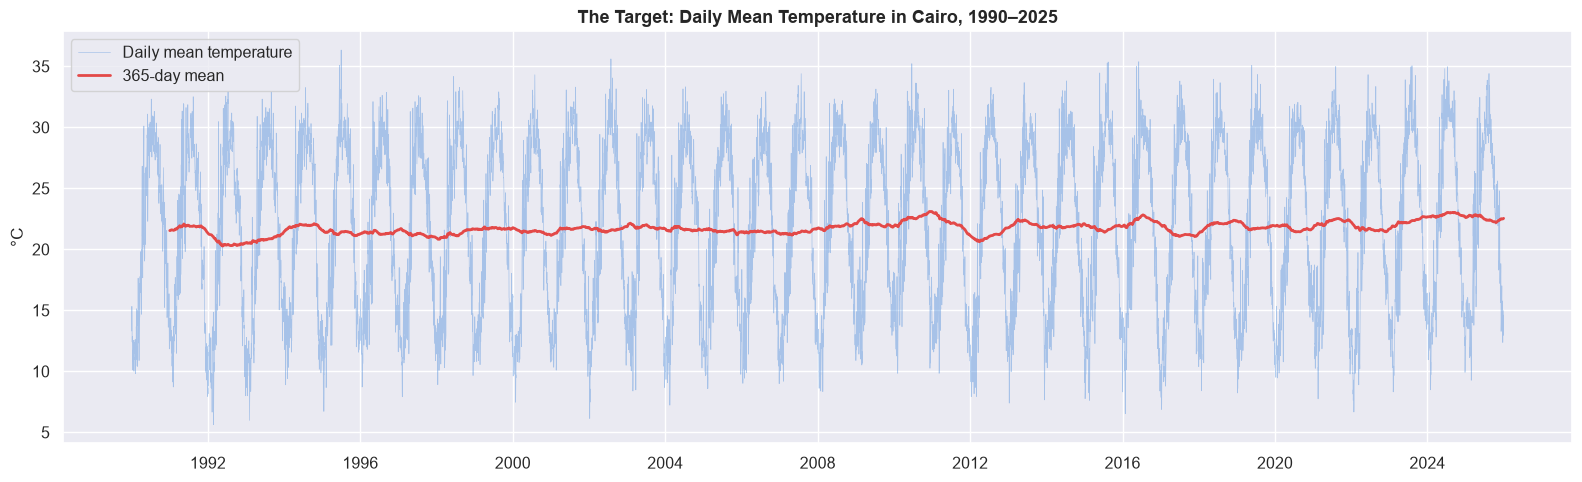

In [77]:
# the forecast target over all 36 years
plt.figure(figsize=(16, 5))
plt.plot(weather.index, weather["temp_mean"], color="#2a78d6", alpha=0.35, linewidth=0.5, label="Daily mean temperature")
plt.plot(weather.index, weather["temp_mean"].rolling(365).mean(), color="#e34948", linewidth=2, label="365-day mean")
plt.title("The Target: Daily Mean Temperature in Cairo, 1990–2025")
plt.ylabel("°C")
plt.legend()
plt.tight_layout()
plt.show()

### The four Task 4 checks that Task 5 expects

| Task 5 expects | Done in Task 4 | What it found |
|---|---|---|
| Missing timestamps and gaps | 2.2, 2.4 | 13,149 days (1990–2025) with no missing dates and no duplicates. The only missing values: wind direction, wrong (below 0°) on every day from 2013, set to empty |
| Trend and seasonality (daily and yearly cycles) | 3.2.2, 3.2.3, 3.3.1 | A strong yearly cycle (about 19 °C between January and July–August) and a slow warming. No daily cycle (the data is daily) and no weekly cycle (same median every weekday) |
| Distributions and outliers | 3.1, 3.4.2, 3.4.3 | Temperature, humidity, wind and pressure are balanced around their mean; rain is very one-sided (75 % of days dry, only 2.9 % with ≥ 1 mm). Outliers found on a 31-day window are real storms, heat and cold, and are kept |
| Correlation between weather variables | 3.4.1 | After removing the season, hotter days are drier (−0.50 between max temperature and humidity) and come with lower pressure (−0.34) |

The plot above shows the target: the same yearly wave 36 times, and a 365-day mean that rises from about 21.5 °C (1990) to 22.5 °C (2025).

### The storm story carried over from Task 4

Task 4 (3.4.4, H5, H6) followed Cairo's storms. Task 5 keeps the same definitions and asks the next question: **can a forecast see them coming?**

| Task 4 finding | Detail | Where Task 5 tests it |
|---|---|---|
| Storm score | Average rank of pressure drop, wind, max-temperature drop and humidity; consistent over all 36 years | Step 9: error vs storm score |
| Strongest storms | 22 Mar 1991 is the strongest; 7 of the top 10 are before 2016 | Step 9 uses the same score |
| The March 2020 storm | 12 Mar 2020: the lowest pressure in 36 years (about 98.3 kPa), 48.5 mm of rain, after a warm day | Step 9: forecast day by day (validation years) |
| Events | 25 storms (rain ≥ 10 mm, 2016–2025), 262 heat waves, 114 cold snaps (first days) | Step 9: error on the day before, the event day and the day after (2020–2025); Step 11: event-day error of every model on test |
| H5 | Storms give almost no warning; heat waves and cold snaps build up over days | Step 9: is the error on the storm day only? |
| H6 | Khamasin-like days: hot, very dry, south wind, mostly December–April | Step 9: the calmest storm-score group |

### The six questions from Task 4 (H1–H6)

Task 4 asked six questions and answered them from the past (EDA on 1990–2025). Task 5 does not repeat that work. It tests each answer **by forecasting years the model never saw**: if an answer is right, it should show up where the forecast succeeds or fails.

| | Question | Task 4 answer | Tested in Task 5 |
|---|---|---|---|
| H1 | Is Cairo getting warmer, and are nights warming faster? | Yes: nights +0.41 °C, days +0.23 °C per 10 years | Steps 4–5 (trend term), Step 8 (bias on the warmest years); nights vs days not tested |
| H2 | Are very hot days becoming more frequent? | Partly: 2023 and 2024 are the highest years | Step 11 (very hot days per year, Task 4's definition); Step 8 (error on them) |
| H3 | Did heavy rain really increase after 2016? | Most likely a change in the data | Used as a decision: rain and storms use 2016–2025 only |
| H4 | Are cold waves becoming rarer? | Yes, slowly; 2022 was still cold | Step 11 (very cold nights per year, Task 4's definition); Step 8 (error on them) |
| H5 | Do storms have a signature in the days before them? | Partly: heat waves and cold snaps do, storms do not | Step 9 (error before, on and after each event; 9.5: which signs together warn of a storm) |
| H6 | Can Khamasin-like days be detected? | Yes: hot, very dry, low pressure, south wind | Not testable after 2012 (no wind direction); Step 9 shows a similar pattern only |

The answers from both tasks are compared side by side in Step 11.

# 2. Preprocessing for Time Series

Task 4 already cleaned the data (Part 2 of that notebook). This section checks each Task 5 preprocessing step on the clean data, adds what Task 5 asks for that Task 4 did not need, and prepares the inputs, targets and splits that every model below uses.

## 2.1 Resampling and Frequency Alignment

**What we do:** Set a fixed daily frequency on the date index and check that it adds no new empty days.

**Why:** Every time-series tool after this (the SARIMA seasonal order, lags, rolling windows, LSTM windows) assumes one row = one day, in order. Without a defined frequency, SARIMAX does not know the time step, and forecasts get no proper dates. If some days were missing, `asfreq` would add them as empty rows, so counting the empty values before and after shows whether any gap was hiding.

**What we do with it:** No resampling is needed: NASA POWER already gives exactly one value per day.

In [78]:
# count empty values before setting the frequency
missing_before = weather.isnull().sum().sum()

# tell pandas the data is daily; any missing day would appear as a new empty row
weather = weather.asfreq("D")

print("Frequency:", weather.index.freq)
print("Empty values before:", missing_before, "| after:", weather.isnull().sum().sum(),
      "-> new gaps:", weather.isnull().sum().sum() - missing_before)

Frequency: <Day>
Empty values before: 4749 | after: 4749 -> new gaps: 0


**What we see:** The frequency is daily ("D"), and setting it adds **no** new empty value (4,749 before and after; all of them are wind direction).

**Why:** The API returns one row per day, and Task 4 (2.2) already found no missing or repeated dates.

**What we do with it:** The index is ready for SARIMA, lags and windows.

## 2.2 Handling Missing Values

**What we do:** Count the empty days in each column and the longest run of empty days in a row.

**Why:** Task 5 asks for time-aware filling: short gaps from the days around them (time interpolation), long gaps from the same day in an earlier period (seasonal-naive), and never a long forward-fill. Which one applies depends on how long the gaps are.

**What we do with it:** See below.

In [79]:
def longest_gap(series):
    # the longest run of empty days in a row
    missing = series.isnull()
    if not missing.any():
        return 0
    return missing.groupby((~missing).cumsum()).sum().max()

missing_table = pd.DataFrame({
    "Empty days": weather.isnull().sum(),
    "Longest gap (days)": [longest_gap(weather[column]) for column in weather.columns],
})
missing_table["Used in Task 5"] = ["No" if column == "wind_dir" else "Yes" for column in weather.columns]
missing_table

,Empty days,Longest gap (days),Used in Task 5
temp_mean,0,0,Yes
temp_max,0,0,Yes
temp_min,0,0,Yes
precipitation,0,0,Yes
humidity,0,0,Yes
wind_speed,0,0,Yes
pressure,0,0,Yes
wind_dir,4749,4749,No


**What we see:** Every column used in Task 5 has **0 empty days**. Only wind direction is empty: 4,749 days in one run (2013–2025).

**Why:** Task 4 (2.6) already filled the short gaps (≤ 3 days) by time interpolation. Wind direction is a different case: it is not missing for a few days, it is wrong for 13 years in a row (Task 4, 2.4). Filling it with a seasonal-naive value or a forward-fill would make up 13 years of data.

**What we do with it:**
- **Short gaps:** handled in Task 4 by time interpolation, as Task 5 recommends.
- **Long gaps:** none in the used columns, so no seasonal-naive fill is needed.
- **Forward-fill:** not used anywhere.
- **Wind direction:** left empty and not used.

## 2.3 Outlier Treatment

**What we do:**
1. **Impossible values:** check every variable against a range that is physically possible for Cairo.
2. **Rolling z-score:** flag days that are far from the 31 days around them (|z| > 3), and compare with one fixed threshold for the whole series.

**Why:** Weather is seasonal, so a global threshold does not work: a cold day in July looks normal next to January. Task 5 asks for a rolling window for this reason. Task 4 (2.5) checked rain, humidity, wind and min > max; the temperature range was not checked there, so it is added here.

**What we do with it:** See below.

In [80]:
# a range that is physically possible for Cairo, for each variable
PLAUSIBLE = {
    "temp_min": (-5, 35),
    "temp_mean": (0, 40),
    "temp_max": (5, 50),
    "precipitation": (0, 200),
    "humidity": (0, 100),
    "wind_speed": (0, 30),
    "pressure": (95, 105),
}

rows = []
for column, (low, high) in PLAUSIBLE.items():
    rows.append({
        "Column": column,
        "Lowest": weather[column].min(),
        "Highest": weather[column].max(),
        "Allowed range": str(low) + " to " + str(high),
        "Days outside": ((weather[column] < low) | (weather[column] > high)).sum(),
    })

pd.DataFrame(rows).set_index("Column")

,Lowest,Highest,Allowed range,Days outside
Column,,,,
temp_min,0.44,27.90,-5 to 35,0
temp_mean,5.63,36.34,0 to 40,0
temp_max,7.90,45.49,5 to 50,0
precipitation,0.00,95.48,0 to 200,0
humidity,9.58,90.17,0 to 100,0
wind_speed,0.66,7.38,0 to 30,0
pressure,98.32,101.61,95 to 105,0


In [81]:
OUTLIER_COLUMNS = ["temp_mean", "temp_max", "temp_min", "humidity", "wind_speed", "pressure"]
WINDOW = 31

# each day compared with the 31 days around it
window_mean = weather[OUTLIER_COLUMNS].rolling(WINDOW, center=True).mean()
window_std = weather[OUTLIER_COLUMNS].rolling(WINDOW, center=True).std()
rolling_z = (weather[OUTLIER_COLUMNS] - window_mean) / window_std

# the same check with one fixed threshold for the whole series, to compare
global_z = (weather[OUTLIER_COLUMNS] - weather[OUTLIER_COLUMNS].mean()) / weather[OUTLIER_COLUMNS].std()

pd.DataFrame({
    "Fixed threshold, whole series (|z| > 3)": (global_z.abs() > 3).sum(),
    "Rolling 31-day window (|z| > 3)": (rolling_z.abs() > 3).sum(),
})

,"Fixed threshold, whole series (|z| > 3)",Rolling 31-day window (|z| > 3)
temp_mean,0,18
temp_max,0,12
temp_min,0,18
humidity,7,30
wind_speed,70,34
pressure,19,10


**What we see:**
- **Impossible values:** none. The coldest night is 0.4 °C, the hottest day 45.5 °C, humidity stays between 9.6 and 90.2 %, and pressure between 98.3 and 101.6 kPa.
- **Rolling z-score:** the 31-day window flags 18 days for the mean temperature; the fixed threshold flags **0**. For wind and pressure it is the other way round: the fixed threshold flags more (70 and 19) than the window (34 and 10). The 18 flagged temperature days are spread over 16 different years, and all but one are sudden warm days.

**Why:** The fixed threshold sees only the yearly range: no single temperature is extreme for the whole year, so it misses the days that are extreme *for their season*. The rolling window catches them. These days are the sudden hot desert-wind days and cold snaps found in Task 4 (H6, 3.4.2, 3.4.3): real weather, not errors.

**What we do with it:** **Keep every outlier, without capping.** Task 5 prefers capping over deletion so the series stays continuous; here the series is already continuous (nothing is deleted), and capping would teach the models that these days do not happen. These are exactly the days the project wants to forecast in the end. How the models do on them is checked in Steps 8 and 9.

## 2.4 Feature Engineering

**What we do:** Build, for every "today", the inputs a model can use to forecast tomorrow. Everything is known today.

| Feature | What it is | Why (Task 4 / Task 5) |
|---|---|---|
| `temp_lag_1`, `temp_lag_2`, `temp_lag_3` | Temperature today, yesterday, 2 days ago | Memory of about 3 days (Task 4, 3.3.2) |
| `temp_lag_7` | Temperature 7 days before tomorrow | The daily version of Task 5's "previous week" lag |
| `temp_mean_7d`, `temp_std_7d`, `temp_mean_30d` | Mean and spread of the last 7 and 30 days | The daily version of Task 5's 24 h / 7 d rolling statistics |
| `day_sin`, `day_cos` | Tomorrow's day of year as sine and cosine | Cyclical encoding: 31 December next to 1 January (Task 4, 3.5) |
| `humidity_anomaly`, `pressure_anomaly` | Today's value minus the normal for the date (normals from 1990–2019 only) | Hotter days are drier and lower in pressure (Task 4, 3.4.1) |
| `pressure_change_1d` | Change in pressure since yesterday | A storm sign (Task 4, H5) |
| `rain_today`, `rain_days_last_3` | Rain day today (≥ 1 mm); rain days in the last 3 days | Rain comes in groups: 39 % chance after a rain day vs 5 % (Task 4, 3.3.2) |

**Not used, on purpose:** hour of day (the data is daily), day of week and weekend (no weekly pattern, Task 4 3.2.3), lag 365 (no link after a year, Task 4 3.3.2), wind direction (wrong from 2013).

**Why:** SARIMA gets the recent days through its AR terms and the season through sine/cosine inputs (4.1), so it does not need this table. The LSTM (Step 10) and the storm story (Step 9) do. Building it once keeps every model on the same inputs.

**What we do with it:** The first 30 days of 1990 have no full 30-day history; they are skipped as training examples later (no rows are removed from the series).

In [82]:
TRAIN_YEARS = slice("1990", "2019")
temp = weather["temp_mean"]
tomorrow_day_of_year = (weather.index + pd.Timedelta(days=1)).dayofyear

def anomaly(column):
    # difference from the normal for each date; normals from the training years only (1990-2019)
    train_part = weather.loc[TRAIN_YEARS, column]
    normal = train_part.groupby(train_part.index.dayofyear).mean()
    return weather[column] - normal.reindex(weather.index.dayofyear).values

# one row per "today": everything here is known today
features = pd.DataFrame({
    "temp_lag_1": temp,
    "temp_lag_2": temp.shift(1),
    "temp_lag_3": temp.shift(2),
    "temp_lag_7": temp.shift(6),
    "temp_mean_7d": temp.rolling(7).mean(),
    "temp_std_7d": temp.rolling(7).std(),
    "temp_mean_30d": temp.rolling(30).mean(),
    "day_sin": np.sin(2 * np.pi * tomorrow_day_of_year / 365.25),
    "day_cos": np.cos(2 * np.pi * tomorrow_day_of_year / 365.25),
    "humidity_anomaly": anomaly("humidity"),
    "pressure_anomaly": anomaly("pressure"),
    "pressure_change_1d": weather["pressure"].diff(),
    "rain_today": (weather["precipitation"] >= 1).astype(int),
    "rain_days_last_3": (weather["precipitation"] >= 1).astype(int).rolling(3).sum(),
}, index=weather.index)

print("Features:", features.shape[1], "| Empty values (only at the start of 1990):", features.isna().sum().sum())
features.loc["2019-12-29":"2019-12-31"].round(2).T

Features: 14 | Empty values (only at the start of 1990): 53


date,2019-12-29,2019-12-30,2019-12-31
temp_lag_1,12.31,11.25,10.55
temp_lag_2,11.32,12.31,11.25
temp_lag_3,11.76,11.32,12.31
temp_lag_7,12.66,12.62,12.81
temp_mean_7d,12.37,12.17,11.87
temp_std_7d,0.63,0.74,0.92
temp_mean_30d,14.15,13.96,13.73
day_sin,-0.02,-0.00,0.02
day_cos,1.00,1.00,1.00
humidity_anomaly,-4.58,-3.41,7.97


## 2.5 Targets and Train/Test Split (Time-Aware Only)

**What we do:** For every day, add tomorrow's value as the target. Then split the days by years, exactly as in Task 4 (4.1):

| | Temperature | Rain |
|---|---|---|
| Train | 1990–2019 | 2016–2020 |
| Validation | 2020–2022 | 2021–2022 |
| Test | 2023–2025 | 2023–2025 |

**Why:** A forecast can only use the past. A random split would put 2024 days in training and 2023 days in testing: the model would see the future and look better than it is. Task 5 suggests the last 2–4 weeks as test for hourly data; with daily data and a yearly season, whole years are needed, so that every season is tested. Rain starts in 2016 because the rain data changed that year (H3).

**What we do with it:** Validation chooses the settings (Steps 3–7); test is used once (Step 8). The test years include the hottest summers (H2), so it is a hard, honest test.

In [83]:
# each row is "today"; the targets are tomorrow's values
data = weather.copy()
data["temp_tomorrow"] = data["temp_mean"].shift(-1)
data["rain_tomorrow"] = (data["precipitation"].shift(-1) >= 1).astype(int)

# the last day has no tomorrow, so it is removed from the targets
data = data.iloc[:-1]
features = features.loc[data.index]

# split by time, never at random
temp_train = data.loc["1990":"2019"]
temp_valid = data.loc["2020":"2022"]
temp_test = data.loc["2023":"2025"]

# rain uses 2016-2025 only, where the rain data is consistent (H3)
rain_train = data.loc["2016":"2020"]
rain_valid = data.loc["2021":"2022"]
rain_test = data.loc["2023":"2025"]

split_sizes = pd.DataFrame({
    "Temperature: years": ["1990–2019", "2020–2022", "2023–2025"],
    "Temperature: days": [len(temp_train), len(temp_valid), len(temp_test)],
    "Rain: years": ["2016–2020", "2021–2022", "2023–2025"],
    "Rain: days": [len(rain_train), len(rain_valid), len(rain_test)],
    "Rain-tomorrow days": [rain_train["rain_tomorrow"].sum(), rain_valid["rain_tomorrow"].sum(), rain_test["rain_tomorrow"].sum()],
}, index=["Train", "Validation", "Test"])
split_sizes["Rain-tomorrow (%)"] = (100 * split_sizes["Rain-tomorrow days"] / split_sizes["Rain: days"]).round(1)
split_sizes

,Temperature: years,Temperature: days,Rain: years,Rain: days,Rain-tomorrow days,Rain-tomorrow (%)
Train,1990–2019,10957,2016–2020,1827,89,4.9
Validation,2020–2022,1096,2021–2022,730,44,6.0
Test,2023–2025,1095,2023–2025,1095,43,3.9


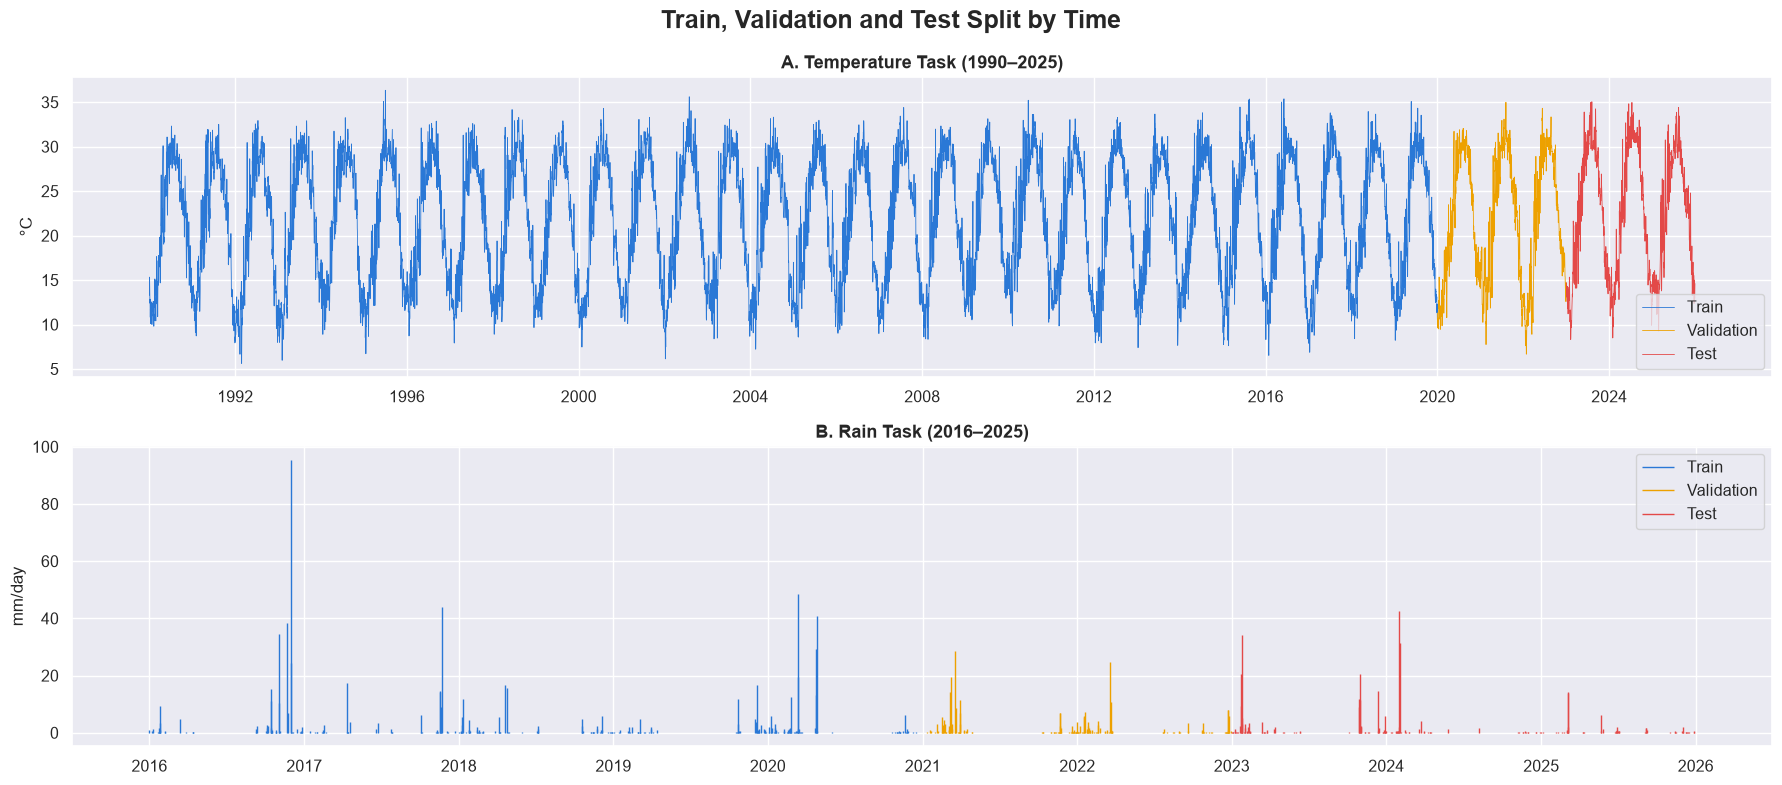

In [84]:
SPLIT_COLORS = {"Train": "#2a78d6", "Validation": "#eda100", "Test": "#e34948"}

fig, ax = plt.subplots(nrows=2, figsize=(18, 8))

# A. temperature task, one color per split
for name, part in zip(SPLIT_COLORS, [temp_train, temp_valid, temp_test]):
    ax[0].plot(part.index, part["temp_mean"], color=SPLIT_COLORS[name], linewidth=0.6, label=name)
ax[0].set_title("A. Temperature Task (1990–2025)")
ax[0].set_ylabel("°C")
ax[0].legend()

# B. rain task, one line per day so no rain day is hidden
for name, part in zip(SPLIT_COLORS, [rain_train, rain_valid, rain_test]):
    ax[1].vlines(part.index, 0, part["precipitation"], color=SPLIT_COLORS[name], linewidth=1, label=name)
ax[1].set_title("B. Rain Task (2016–2025)")
ax[1].set_ylabel("mm/day")
ax[1].legend()

plt.suptitle("Train, Validation and Test Split by Time")
plt.tight_layout()
plt.show()

**What we see:**
- **Temperature:** 30 years to learn from (10,957 days), then 3 years for validation (1,096) and 3 for test (1,095).
- **Rain:** rain tomorrow happens on 4.9 % of train days, 6.0 % of validation days and 3.9 % of test days: only 89, 44 and 43 rain days.

**Why:** Rain changes a lot from year to year, and 2023–2025 happened to be drier.

**What we do with it:** Never judge rain by accuracy ("always no rain" already gets 96 % on test). Show the counts (hits, misses, false alarms) next to the percentages, because one rain day more or less moves recall by about 2 points.

## 2.6 Scaling

- **ARIMA / SARIMA (Steps 3–8):** no scaling. The model works on the temperature in °C directly, so its errors and intervals are in °C too.
- **RNN / LSTM (Step 10):** the inputs are scaled with a scaler **fitted on the training years only**, then the same scaler is applied to validation and test. Forecasts are turned back into °C before any score is computed.

### Preprocessing: where each Task 5 step was done

| Task 5 step | Done in | What was done |
|---|---|---|
| 2.1 Resampling and frequency | Task 4, 2.2 + Step 1 | The API already gives one row per day, with no gaps or duplicates; `asfreq("D")` sets the frequency |
| 2.2 Missing values | Task 4, 2.4 and 2.6 | Short gaps (≤ 3 days) filled by time interpolation; wind direction (wrong from 2013) left empty and not used |
| 2.3 Outliers | Task 4, 2.5 and 3.4.2 | Impossible values checked (none). Outliers found on a 31-day rolling window. **Kept, not capped**, because they are real storms, heat waves and cold spells; capping them would teach the model that these days do not happen |
| 2.4 Feature engineering | 2.4 + Steps 4, 5 and 10 | Day of year as sine and cosine; recent days; humidity and pressure |
| 2.5 Time-aware split | Task 4, 4.1 + Step 1 | Same split by years, never shuffled |
| 2.6 Scaling | Step 10 | Not needed for ARIMA/SARIMAX; for the LSTM, the scaler is fitted on the training years only |

## Step 2: Metrics and Baselines

**What we do:** Bring the scoring functions and the simple forecasts (baselines) from Task 4 (Parts 4.2–4.4), and add two metrics Task 5 asks for: MAPE and sMAPE.

**Why:** The final comparison table needs every model and every baseline scored with the same metrics, on exactly the same days. Recomputing the baselines here (with the same code as Task 4) keeps this notebook complete on its own.

**What we do with it:** The MAE of the baselines must match Task 4 (1.07 °C on validation and 1.04 °C on test for "tomorrow = today"). These are the numbers every model in Steps 5–9 must beat.

### Evaluation metrics
- **Temperature (regression):** MAE (the typical error in °C), RMSE (punishes big misses more), MAPE (the error as a % of the real value), sMAPE (the same idea, fair to forecasts that are too high or too low), R². MAPE is safe here: Cairo's daily mean never gets close to 0 °C (lowest: 5.6 °C).
- **Rain (classification):** hits, misses and false alarms, then precision, recall, F1 and CSI (hits out of all days where rain was forecast or happened). Accuracy is shown but not used to choose, because about 95 % of days are dry.

In [85]:
def regression_scores(y_true, y_pred):
    # Errors in °C and in %, so they are easy to read
    error = y_true - y_pred
    return {
        "MAE (°C)": mean_absolute_error(y_true, y_pred),
        "RMSE (°C)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": 100 * np.mean(np.abs(error / y_true)),
        "sMAPE (%)": 100 * np.mean(2 * np.abs(error) / (np.abs(y_true) + np.abs(y_pred))),
        "R²": r2_score(y_true, y_pred),
    }

def classification_scores(y_true, y_pred):
    # Counts first, because rain days are few and percentages can hide them
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Hits": tp,
        "Misses": fn,
        "False alarms": fp,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        # CSI: hits out of all days where rain was forecast or happened (ignores the many easy dry days)
        "CSI": tp / (tp + fn + fp) if (tp + fn + fp) > 0 else 0.0,
    }

In [86]:
# A perfect forecast should give MAE 0 and R² 1
regression_scores(temp_valid["temp_tomorrow"], temp_valid["temp_tomorrow"])

{'MAE (°C)': 0.0,
 'RMSE (°C)': np.float64(0.0),
 'MAPE (%)': np.float64(0.0),
 'sMAPE (%)': np.float64(0.0),
 'R²': 1.0}

### Temperature Baselines (Task 4, 4.3)

**What we do:** Forecast tomorrow's mean temperature with four simple methods that need no learning, and score them on validation and test.

| Baseline | Forecast for tomorrow | Idea |
|---|---|---|
| Persistence | Today's temperature | Weather changes slowly (Step 3.3.2) |
| Mean of last 7 days | The average of the last 7 days | Smooths out one-day noise |
| Climatology | The normal for tomorrow's date (train years only) | Uses only the season (Step 3.3.1) |
| Same day last year | Tomorrow's date, one year ago | Uses the yearly cycle |

**Why these four:** Each one uses one thing we found in the EDA: recent days, the season, or last year. A real model combines them, so it must beat all four. Climatology uses training years only (1990–2019), so no future data leaks in.

In [87]:
# Normal temperature for each day of the year, from the train years only
normal_by_day = temp_train["temp_mean"].groupby(temp_train.index.dayofyear).mean()
tomorrow_day = (data.index + pd.Timedelta(days=1)).dayofyear

# Each column is one simple forecast for tomorrow
temp_baselines = pd.DataFrame({
    "Persistence (today)": data["temp_mean"],
    "Mean of last 7 days": data["temp_mean"].rolling(7).mean(),
    "Climatology (normal for tomorrow)": normal_by_day.reindex(tomorrow_day).values,
    "Same day last year": data["temp_tomorrow"].shift(365),
}, index=data.index)

# Score every baseline on validation and test
rows = []
for split_name, part in [("Validation", temp_valid), ("Test", temp_test)]:
    for baseline in temp_baselines.columns:
        scores = regression_scores(part["temp_tomorrow"], temp_baselines.loc[part.index, baseline])
        scores["Split"] = split_name
        scores["Baseline"] = baseline
        rows.append(scores)

temp_results = pd.DataFrame(rows).set_index(["Split", "Baseline"])
temp_results.round(2)

MAE (°C)  RMSE (°C)  MAPE (%)  \
Split      Baseline                                                           
Validation Persistence (today)                    1.07       1.49      5.58   
           Mean of last 7 days                    1.59       2.14      8.37   
           Climatology (normal for tomorrow)      1.84       2.40     10.13   
           Same day last year                     2.56       3.35     14.01   
Test       Persistence (today)                    1.04       1.44      5.01   
           Mean of last 7 days                    1.54       2.06      7.59   
           Climatology (normal for tomorrow)      1.79       2.33      8.66   
           Same day last year                     2.27       2.93     11.33   

                                              sMAPE (%)    R²  
Split      Baseline                                            
Validation Persistence (today)                     5.53  0.96  
           Mean of last 7 days                     8.28  0.91  
           Climatology (normal for tomorrow)       9.82  0.88  
           Same day last year                     13.56  0.77  
Test       Persistence (today)                     4.97  0.96  
           Mean of last 7 days                     7.53  0.91  
           Climatology (normal for tomorrow)       8.89  0.89  
           Same day last year                     11.54  0.82

**What we see:** "Tomorrow = today" wins clearly: MAE 1.07 °C on validation and 1.04 °C on test. Next come the 7-day mean (1.59 and 1.54), the normal for the date (1.84 and 1.79), and last year's same day is the worst (2.56 and 2.27).

**Why:** Weather changes slowly from one day to the next, and only the last few days carry information (Step 3.3.2). Last year's weather on this date is mostly luck.

**What we do with it:** A model is only useful if its MAE is below about 1.04–1.07 °C. That is the number to beat.

### Rain Baselines (Task 4, 4.4)

**What we do:** Forecast "real rain tomorrow (≥ 1 mm)" with three simple methods that need no learning, and score them on validation and test (2016–2025 only, H3).

| Baseline | Forecast for tomorrow | Idea |
|---|---|---|
| Always no rain | Never rain | Shows why accuracy is misleading (Step 3.1) |
| Persistence | Rain if it rained today | Rain days come in groups (Step 3.3.2) |
| Seasonal guess | Rain at random, with the month's chance from the train years | Uses only the season (Step 3.2.3); a fixed seed keeps it the same every run |

**Why these three:** They show what you get with no skill, with one day of memory, and with the calendar alone. They are compared on hits, misses, false alarms, precision, recall, F1 and CSI.

In [88]:
# Chance of a rain day in each month, from the train years only
rain_by_month = (rain_train["precipitation"] >= 1).groupby(rain_train.index.month).mean()
tomorrow_month = (data.index + pd.Timedelta(days=1)).month
rain_chance = rain_by_month.reindex(tomorrow_month).values

# Fixed seed so the random guess is the same every run
rng = np.random.default_rng(42)

# Each column is one simple forecast for tomorrow (1 = rain, 0 = no rain)
rain_baselines = pd.DataFrame({
    "Always no rain": 0,
    "Persistence (rain today)": (data["precipitation"] >= 1).astype(int),
    "Seasonal guess (month's chance)": (rng.random(len(data)) < rain_chance).astype(int),
}, index=data.index)

# Score every baseline on validation and test
rows = []
for split_name, part in [("Validation", rain_valid), ("Test", rain_test)]:
    for baseline in rain_baselines.columns:
        scores = classification_scores(part["rain_tomorrow"], rain_baselines.loc[part.index, baseline])
        scores["Split"] = split_name
        scores["Baseline"] = baseline
        rows.append(scores)

rain_results = pd.DataFrame(rows).set_index(["Split", "Baseline"])
rain_results.round(2)

Hits  Misses  False alarms  \
Split      Baseline                                                      
Validation Always no rain                      0      44             0   
           Persistence (rain today)           16      28            28   
           Seasonal guess (month's chance)     3      41            33   
Test       Always no rain                      0      43             0   
           Persistence (rain today)           20      23            23   
           Seasonal guess (month's chance)     2      41            46   

                                            Accuracy  Precision  Recall    F1  \
Split      Baseline                                                             
Validation Always no rain                       0.94       0.00    0.00  0.00   
           Persistence (rain today)             0.92       0.36    0.36  0.36   
           Seasonal guess (month's chance)      0.90       0.08    0.07  0.08   
Test       Always no rain                       0.96       0.00    0.00  0.00   
           Persistence (rain today)             0.96       0.47    0.47  0.47   
           Seasonal guess (month's chance)      0.92       0.04    0.05  0.04   

                                             CSI  
Split      Baseline                               
Validation Always no rain                   0.00  
           Persistence (rain today)         0.22  
           Seasonal guess (month's chance)  0.04  
Test       Always no rain                   0.00  
           Persistence (rain today)         0.30  
           Seasonal guess (month's chance)  0.02

**What we see:**
- **Always no rain:** 94–96 % accuracy, but zero hits.
- **Persistence (rain today → rain tomorrow):** the best. It catches 16 of 44 rain days on validation (F1 0.36, CSI 0.22) and 20 of 43 on test (F1 0.47, CSI 0.30). It gives as many false alarms as misses.
- **Seasonal guess:** almost useless: 3 and 2 hits, with many more false alarms than hits.

**Why:** Rain comes in groups, so "it rained today" is a strong clue (Step 3.3.2). The month only tells you when rain is possible, not which day it falls.

**What we do with it:** Persistence is the rain baseline to beat: a model must catch more than about a third of the rain days on validation without adding many false alarms. Accuracy is ignored.

## Step 3: Stationarity (ADF + KPSS) and the Differencing Decision

**What we do:** Run three tests on the training years only (1990–2019), on three versions of the temperature: as it is, with the season removed (minus the normal for each date, from the training years), and the daily change.
- **ADF** asks: does the series wander like a random walk (a "unit root")? A p-value below 0.05 means no, it is stationary.
- **KPSS (c)** asks the opposite: does the series stay around one fixed level? A p-value below 0.05 means no, it is not stationary.
- **KPSS (ct)** asks: does the series stay around a straight-line trend?

**Why:** ARIMA needs a stationary series, and the tests decide the "d" in ARIMA (how many times to difference). ADF and KPSS start from opposite assumptions, so using both avoids trusting one test alone. When they disagree, the series is usually stationary around a trend or a season, not a random walk.

**What we do with it:** The results decide d, D, and whether the model needs a trend term.

In [89]:
# training years only, so the test years do not decide anything
train_temp = temp_train["temp_mean"]
train_no_season = train_temp - normal_by_day.reindex(train_temp.index.dayofyear).values

series = {
    "Mean temperature (as it is)": train_temp,
    "After removing the season": train_no_season,
    "Daily change (differenced)": train_temp.diff().dropna(),
}

def adf_text(p):
    # ADF gives an exact p-value
    return "< 0.001" if p < 0.001 else str(round(p, 3))

def kpss_text(p):
    # KPSS p-values are cut at 0.01 and 0.10
    if p <= 0.01:
        return "≤ 0.01"
    if p >= 0.10:
        return "≥ 0.10"
    return str(round(p, 3))

rows = []
for name, values in series.items():
    adf_p = adfuller(values)[1]
    kpss_c_p = kpss(values, regression="c", nlags="auto")[1]
    kpss_ct_p = kpss(values, regression="ct", nlags="auto")[1]
    rows.append({
        "Series": name,
        "ADF p-value": adf_text(adf_p),
        "ADF says": "Stationary" if adf_p < 0.05 else "Not stationary",
        "KPSS (c) p-value": kpss_text(kpss_c_p),
        "KPSS (c) says": "Stationary" if kpss_c_p >= 0.05 else "Not stationary",
        "KPSS (ct) p-value": kpss_text(kpss_ct_p),
        "KPSS (ct) says": "Stationary around a trend" if kpss_ct_p >= 0.05 else "Not stationary",
    })

stationarity_results = pd.DataFrame(rows).set_index("Series")
stationarity_results

,ADF p-value,ADF says,KPSS (c) p-value,KPSS (c) says,KPSS (ct) p-value,KPSS (ct) says
Series,,,,,,
Mean temperature (as it is),< 0.001,Stationary,≥ 0.10,Stationary,≥ 0.10,Stationary around a trend
After removing the season,< 0.001,Stationary,≤ 0.01,Not stationary,≥ 0.10,Stationary around a trend
Daily change (differenced),< 0.001,Stationary,≥ 0.10,Stationary,≥ 0.10,Stationary around a trend


In [90]:
# over-differencing check (Task 5, 7.2): what does one difference do to the season-free series?
check = {"Season removed": train_no_season, "Season removed, then differenced": train_no_season.diff().dropna()}
pd.DataFrame({
    "Std (°C)": {name: values.std() for name, values in check.items()},
    "ACF at lag 1": {name: acf(values, nlags=1)[1] for name, values in check.items()},
}).round(3)

,Std (°C),ACF at lag 1
Season removed,2.253,0.761
"Season removed, then differenced",1.559,0.092


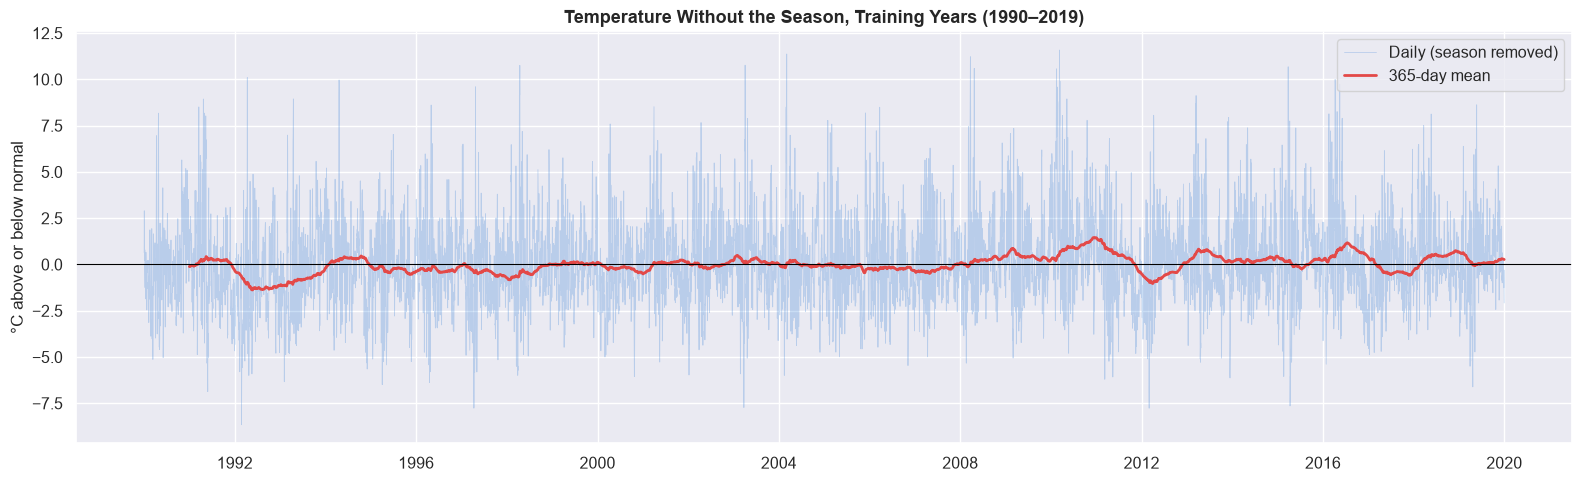

In [91]:
# the season removed, so only the slow changes are left
plt.figure(figsize=(16, 5))
plt.plot(train_no_season.index, train_no_season, color="#2a78d6", alpha=0.25, linewidth=0.6, label="Daily (season removed)")
plt.plot(train_no_season.index, train_no_season.rolling(365).mean(), color="#e34948", linewidth=2, label="365-day mean")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Temperature Without the Season, Training Years (1990–2019)")
plt.ylabel("°C above or below normal")
plt.legend()
plt.tight_layout()
plt.show()

**What we see:**
- **ADF** rejects a unit root for all three series (p < 0.001): the temperature does not wander like a random walk.
- **KPSS (c)** agrees for the temperature as it is (p ≥ 0.10), but **rejects a constant level once the season is removed** (p ≤ 0.01).
- **KPSS (ct)** accepts every series as stationary around a straight-line trend (p ≥ 0.10).
- **Over-differencing check:** without the season, the lag-1 ACF is +0.76. After one difference it falls to +0.09, and the spread falls from 2.25 to 1.56 °C. It does not go near −0.5, the usual sign of over-differencing.
- **The plot:** without the season, the temperature moves around 0, and its 365-day mean drifts slowly upward over the 30 years.

**Why:** ADF and KPSS disagree only on the season-free series. As Task 5 says, this does not mean a unit root: the series is stationary **around a trend**. In the raw series, the 19 °C yearly wave hides a warming of a few tenths of a degree per 10 years. Once the wave is removed, that warming is large next to what is left, so KPSS (c) no longer sees a constant level. KPSS (ct) allows a straight-line trend, and it accepts the series.

**Differencing decision:**

| Order | Value | Reason |
|---|---|---|
| d | 0 | ADF finds no unit root, so a difference is not needed. One difference would not break the series (lag-1 ACF +0.09, not near −0.5), but it would tell the model that every warm or cold day is permanent. Task 4 showed the opposite: temperature always comes back to its normal level. d = 0 keeps that "return to normal" |
| D | 0 | The yearly season is fixed and repeats every year (Task 4: +0.86 at one year). It goes in as sine/cosine inputs (Step 4), not as a seasonal difference. Task 5's period 24 is for hourly data; with daily data the season is the year (m = 365) |
| Trend | Yes | KPSS (c) vs KPSS (ct) on the season-free series: a straight-line trend among the inputs, not a difference |

**What we do with it:** d = 0, D = 0, plus a trend term. Step 4 builds the season and the trend as inputs.

## Step 4: The Season as Sine/Cosine Terms, ACF/PACF, and Choosing the Orders

**What we do:**
1. Build the inputs the model knows in advance for any date: a level, a slow trend (Step 3), and the yearly season as pairs of sine and cosine waves (Fourier terms). Choose how many pairs (K) on the training years.
2. Remove the season and trend, then read the ACF and PACF of what is left to choose the ARIMA orders **by hand**.
3. Run `auto_arima` on the same data and compare its choice with ours.

**Why:** SARIMA would need m = 365 for a yearly season, which is far too heavy to fit on 10,957 days. Sine and cosine waves describe the same yearly shape with a few numbers, so the ARIMA part only has to learn the day-to-day memory. Choosing the orders by hand first, then checking with `auto_arima`, shows that we understand the choice instead of trusting a black box.

**What we do with it:** The chosen K and orders are the models fitted and checked in Step 5.

In [92]:
def make_exog(index, K=3):
    # what the model knows about any date in advance: a level, a slow trend, and the season
    day = index.dayofyear
    exog = pd.DataFrame(index=index)
    exog["const"] = 1.0
    exog["trend"] = (index - pd.Timestamp("1990-01-01")).days / 3652.5  # in decades, so its coefficient is °C per 10 years
    for k in range(1, K + 1):
        exog["sin_" + str(k)] = np.sin(2 * np.pi * k * day / 365.25)
        exog["cos_" + str(k)] = np.cos(2 * np.pi * k * day / 365.25)
    return exog

# try 1 to 4 pairs of sine and cosine, on the training years only
rows = []
for K in [1, 2, 3, 4]:
    season_fit = sm.OLS(train_temp, make_exog(train_temp.index, K)).fit()
    rows.append({
        "K (sine/cosine pairs)": K,
        "AIC": round(season_fit.aic, 1),
        "R²": round(season_fit.rsquared, 4),
        "Left over (std, °C)": round(season_fit.resid.std(), 3),
    })

fourier_results = pd.DataFrame(rows).set_index("K (sine/cosine pairs)")
fourier_results

,AIC,R²,"Left over (std, °C)"
K (sine/cosine pairs),,,
1,49650.1,0.8821,2.331
2,49153.5,0.8874,2.279
3,49104.5,0.8879,2.273
4,49086.2,0.8881,2.271


Trend: 0.27 °C per 10 years


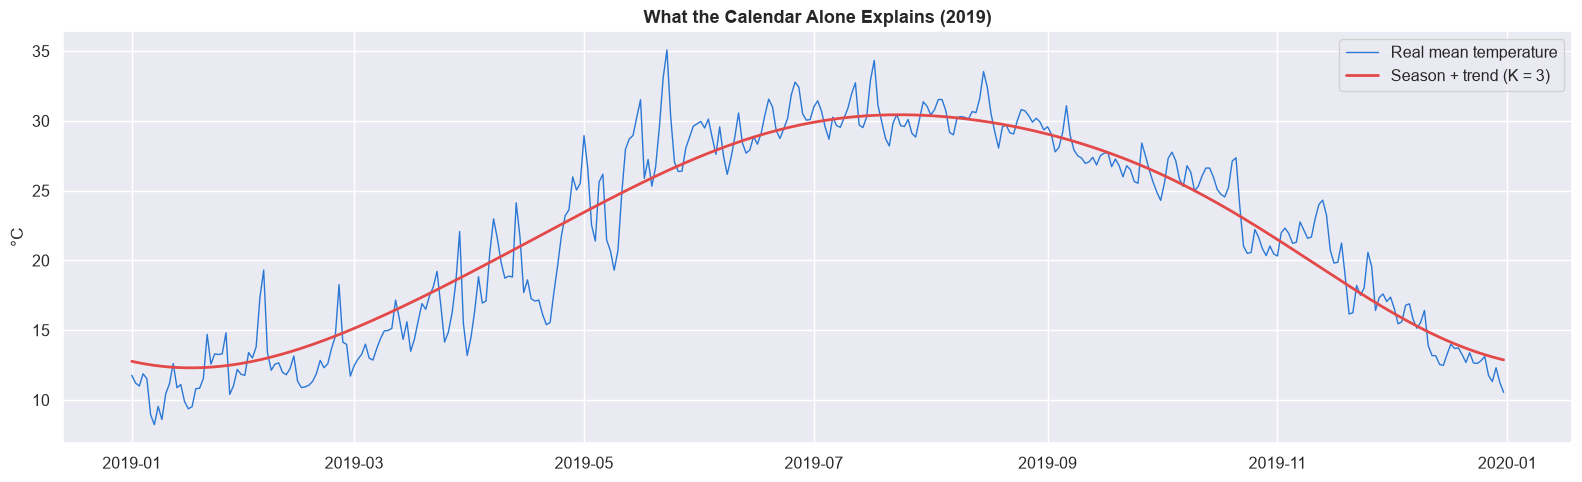

In [93]:
K = 3

# the season and trend with the chosen K, fitted on the training years only
season_fit = sm.OLS(train_temp, make_exog(train_temp.index, K)).fit()
print("Trend:", round(season_fit.params["trend"], 2), "°C per 10 years")

# one year, to see what the calendar alone explains
one_year = train_temp.loc["2019"]
plt.figure(figsize=(16, 5))
plt.plot(one_year.index, one_year, color="#2a78d6", linewidth=1, label="Real mean temperature")
plt.plot(one_year.index, season_fit.fittedvalues.loc["2019"], color="#e34948", linewidth=2, label="Season + trend (K = 3)")
plt.title("What the Calendar Alone Explains (2019)")
plt.ylabel("°C")
plt.legend()
plt.tight_layout()
plt.show()

**What we see:** One sine/cosine pair (K = 1) already explains 88.2 % of the daily temperature. The second pair lowers the AIC by about 500 and the left-over by 0.05 °C, because the year is not a perfect wave. After K = 3 the gain is tiny: K = 4 lowers the left-over by only 0.002 °C. The trend is +0.27 °C per 10 years, between the days (+0.23) and the nights (+0.41) found in H1. In 2019, the red line follows the year closely; what is left are the day-to-day swings, biggest in spring.

**Why:** The yearly shape is smooth, so a few waves are enough. More pairs only follow noise. (The AIC keeps falling a little, but OLS treats the days as independent, so it overrates small terms.)

**What we do with it:** Use K = 3 (3 sine/cosine pairs) plus the level and the trend as the model's inputs. The ARIMA part now only has to learn the left-over: about 2.3 °C of day-to-day weather.

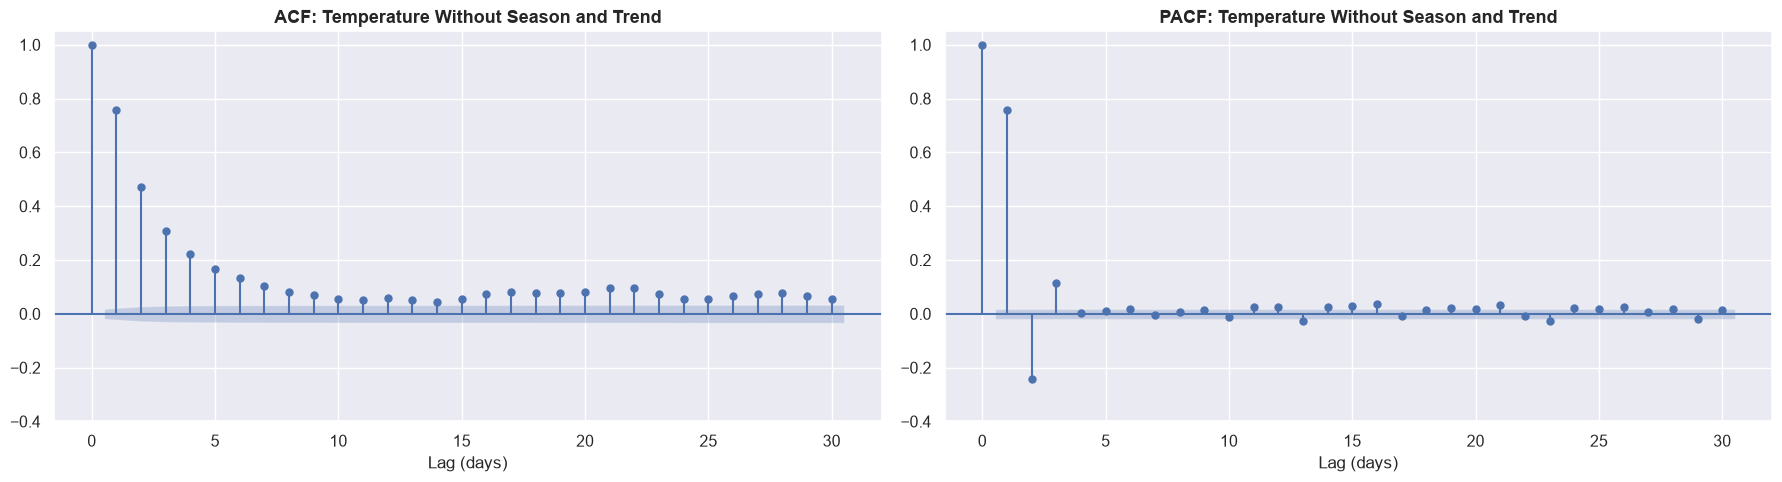

,ACF,PACF
1,0.76,0.76
2,0.47,-0.24
3,0.31,0.11
4,0.22,0.00
5,0.17,0.01
6,0.13,0.02
7,0.10,-0.00


In [94]:
# what is left after removing the season and the trend
left_over = season_fit.resid

fig, ax = plt.subplots(ncols=2, figsize=(18, 5))
plot_acf(left_over, lags=30, ax=ax[0])
plot_pacf(left_over, lags=30, ax=ax[1], method="ywm")
ax[0].set_title("ACF: Temperature Without Season and Trend")
ax[1].set_title("PACF: Temperature Without Season and Trend")
for a in ax:
    a.set_xlabel("Lag (days)")
    a.set_ylim(-0.4, 1.05)
plt.tight_layout()
plt.show()

# the first 7 lags as numbers
pd.DataFrame({"ACF": acf(left_over, nlags=7), "PACF": pacf(left_over, nlags=7, method="ywm")}, index=range(8)).round(2).iloc[1:]

**What we see:**
- **ACF** falls slowly: 0.76, 0.47, 0.31, 0.22, 0.17, … It "tails off" instead of stopping at one lag. After about 10 days a small positive tail stays (0.05–0.08).
- **PACF** has three clear bars, then stops: 0.76 at lag 1, −0.24 at lag 2, 0.11 at lag 3, and about 0 from lag 4 on.
- No spike at any longer lag: the season is already removed.

**Why:** An ACF that tails off together with a PACF that cuts off after lag p is the sign of an AR(p) process: today depends directly on the last p days. Here p = 3. The lag-1 value (0.76) matches Task 4 (0.77). The small positive ACF tail comes from warm or cold spells that last weeks (Task 4, Dashboard 3).

**Manual choice (written before running auto_arima):**

| Order | Value | From |
|---|---|---|
| p | 3 | PACF cuts off after lag 3 |
| d | 0 | Step 3: no unit root |
| q | 0 | ACF tails off; no sharp cut-off |
| (P, D, Q, m) | (0, 0, 0, –) | The season is in the sine/cosine inputs, not in seasonal terms |

**Manual model: ARIMA(3, 0, 0) with season and trend inputs.**

In [95]:
import pmdarima as pm

# the same inputs as the manual model; d = 0 from Step 3; the season is already in X
X_train = make_exog(train_temp.index, K)
auto_model = pm.auto_arima(
    train_temp,
    X=X_train,
    d=0,
    seasonal=False,
    with_intercept=False,  # the level is already the "const" column in X
    stepwise=True,
    max_p=3,
    max_q=3,
    information_criterion="aic",
    trace=True,
    suppress_warnings=True,
    error_action="ignore",
    maxiter=200,  # enough iterations for the bigger orders to converge
)
print("auto_arima picked:", auto_model.order)

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=38941.461, Time=8.87 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=49106.495, Time=3.27 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=39759.485, Time=1.08 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=41758.450, Time=2.27 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=38987.704, Time=2.37 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=38987.714, Time=2.27 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=38940.377, Time=14.10 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=38966.815, Time=4.53 sec
 ARIMA(3,0,3)(0,0,0)[0]             : AIC=38934.062, Time=26.55 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=38939.496, Time=13.37 sec
 ARIMA(3,0,3)(0,0,0)[0] intercept   : AIC=inf, Time=nan sec

Best model:  ARIMA(3,0,3)(0,0,0)[0]          
Total fit time: 78.738 seconds
auto_arima picked: (3, 0, 3)


In [96]:
# fit both choices the same way, so their scores are comparable
orders = {"Manual (from PACF)": (3, 0, 0), "auto_arima": auto_model.order}

rows = []
for name, order in orders.items():
    fit = SARIMAX(train_temp, exog=X_train, order=order).fit(disp=False, maxiter=200)
    rows.append({
        "Choice": name,
        "Order (p, d, q)": order,
        "AIC": round(fit.aic, 1),
        "BIC": round(fit.bic, 1),
        "Parameters": len(fit.params),
    })

order_results = pd.DataFrame(rows).set_index("Choice")
order_results

,"Order (p, d, q)",AIC,BIC,Parameters
Choice,,,,
Manual (from PACF),"(3, 0, 0)",38965.1,39052.7,12
auto_arima,"(3, 0, 3)",38934.1,39043.6,15


**What we see:** auto_arima picks **ARIMA(3,0,3)**; our manual choice from the PACF was **ARIMA(3,0,0)**. The AR part is the same (p = 3, d = 0). auto_arima adds 3 MA terms: its AIC is 31 lower (38,934.1 vs 38,965.1), but its BIC only 9 lower (39,043.6 vs 39,052.7), with 15 parameters instead of 12. All fits use `maxiter=200`, so the bigger orders converge.

**Why the mismatch:** The MA terms catch the small, long ACF tail (0.05–0.08 after 10 days, Step 4): warm and cold spells that last weeks. AIC rewards this small gain. BIC punishes extra parameters more on 10,957 days, so it barely does. The mismatch shows the gain from the extra terms is small, not that the PACF reading was wrong.

**What we do with it:** Keep both: **M2** = manual ARIMA(3,0,0), **M3** = auto_arima's ARIMA(3,0,3). Step 6 decides on the validation years.

## Step 5: Fit the Models and Check Their Residuals

**What we do:** Fit four models on the training years (1990–2019):

| Model | Order | Inputs | Why it is here |
|---|---|---|---|
| M1 | ARIMA(3,0,0) | Level only, **no season** | The "non-seasonal ARIMA" row Task 5 asks for: shows what happens without the season |
| M2 | ARIMA(3,0,0) | Level, trend, season (K = 3) | Our manual choice (Step 4) |
| M3 | auto_arima order | Level, trend, season (K = 3) | auto_arima's choice (Step 4) |
| M4 | ARIMA(3,0,0) | M2 + **yesterday's** humidity and pressure (as differences from normal) | Tests the Task 4 finding "humidity and pressure add information" (3.5, row 9) |

Then check each model's residuals (real minus fitted): AIC and BIC, the Ljung-Box test (is any memory left in the residuals?), and the four diagnostic plots (residuals over time, histogram, Q-Q plot, correlogram).

**Why:** A good model leaves residuals that look like random noise: no pattern over time, no memory from day to day. If memory is left, the model missed something it could have learned. Humidity and pressure enter with **yesterday's** values, because on the day we forecast, today's values are not known yet; using them would leak the future.

**What we do with it:** Models with clean residuals go to Step 6, where the error on the validation years decides between them.

In [97]:
def anomaly(column):
    # difference from the normal for each date; normals from the training years only
    normal = temp_train[column].groupby(temp_train.index.dayofyear).mean()
    return weather[column] - normal.reindex(weather.index.dayofyear).values

# yesterday's humidity and pressure: on the day we forecast, only yesterday's values are known
weather_inputs = pd.DataFrame({
    "humidity_yesterday": anomaly("humidity").shift(1),
    "pressure_yesterday": anomaly("pressure").shift(1),
}, index=weather.index).fillna(0)

def model_inputs(index, name):
    # the inputs each model gets for a list of dates
    if name == "M1":
        return make_exog(index, K)[["const"]]
    if name == "M4":
        return make_exog(index, K).join(weather_inputs.loc[index])
    return make_exog(index, K)

MODELS = {
    "M1": {"label": "M1: ARIMA(3,0,0), no season", "order": (3, 0, 0)},
    "M2": {"label": "M2: ARIMA(3,0,0) + season + trend (manual)", "order": (3, 0, 0)},
    "M3": {"label": "M3: ARIMA" + str(auto_model.order).replace(" ", "") + " + season + trend (auto_arima)", "order": auto_model.order},
    "M4": {"label": "M4: ARIMA(3,0,0) + season + trend + yesterday's humidity and pressure", "order": (3, 0, 0)},
}

# fit every model on the training years only (maxiter=200 so the bigger model finishes fitting)
fits = {}
for name, info in MODELS.items():
    model = SARIMAX(train_temp, exog=model_inputs(train_temp.index, name), order=info["order"])
    fits[name] = model.fit(disp=False, maxiter=200)
    print(info["label"], "| converged:", fits[name].mle_retvals["converged"])

M1: ARIMA(3,0,0), no season | converged: True
M2: ARIMA(3,0,0) + season + trend (manual) | converged: True
M3: ARIMA(3,0,3) + season + trend (auto_arima) | converged: True
M4: ARIMA(3,0,0) + season + trend + yesterday's humidity and pressure | converged: True


In [98]:
rows = []
for name, fit in fits.items():
    residuals = fit.resid.iloc[3:]  # the first days have no past to learn from
    # model_df: the AR and MA terms were fitted on these residuals, so they cost degrees of freedom
    p, d, q = MODELS[name]["order"]
    ljung_box = acorr_ljungbox(residuals, lags=[7, 30], model_df=p + q)
    rows.append({
        "Model": MODELS[name]["label"],
        "AIC": round(fit.aic, 1),
        "BIC": round(fit.bic, 1),
        "Residual std (°C)": round(residuals.std(), 3),
        "Ljung-Box p (lag 7)": round(ljung_box["lb_pvalue"].iloc[0], 3),
        "Ljung-Box p (lag 30)": round(ljung_box["lb_pvalue"].iloc[1], 3),
    })

diagnostics = pd.DataFrame(rows).set_index("Model")
diagnostics

,AIC,BIC,Residual std (°C),Ljung-Box p (lag 7),Ljung-Box p (lag 30)
Model,,,,,
"M1: ARIMA(3,0,0), no season",40272.1,40308.6,1.519,0.000,0.0
"M2: ARIMA(3,0,0) + season + trend (manual)",38965.1,39052.7,1.431,0.260,0.0
"M3: ARIMA(3,0,3) + season + trend (auto_arima)",38934.1,39043.6,1.428,0.007,0.0
"M4: ARIMA(3,0,0) + season + trend + yesterday's humidity and pressure",38837.9,38940.1,1.422,0.385,0.0


In [99]:
# the full statsmodels summary of the manual model (M2)
print(fits["M2"].summary())

                               SARIMAX Results                                
Dep. Variable:              temp_mean   No. Observations:                10957
Model:               SARIMAX(3, 0, 0)   Log Likelihood              -19470.535
Date:                Wed, 21 Oct 2026   AIC                          38965.069
Time:                        15:07:26   BIC                          39052.690
Sample:                    01-01-1990   HQIC                         38994.594
                         - 12-31-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         21.2338      0.112    189.902      0.000      21.015      21.453
trend          0.2743      0.060      4.547      0.000       0.156       0.393
sin_1         -3.4289      0.085    -40.320      0.0

In [100]:
# the trend and the weather inputs: how big they are and whether they matter
rows = []
for name in ["M2", "M3", "M4"]:
    for column in ["trend", "humidity_yesterday", "pressure_yesterday"]:
        if column in fits[name].params:
            rows.append({
                "Model": name,
                "Input": column,
                "Coefficient": round(fits[name].params[column], 3),
                "p-value": round(fits[name].pvalues[column], 4),
            })

pd.DataFrame(rows)

,Model,Input,Coefficient,p-value
0,M2,trend,0.274,0.0000
1,M3,trend,0.272,0.0039
2,M4,trend,0.290,0.0000
3,M4,humidity_yesterday,0.000,0.9578
4,M4,pressure_yesterday,0.941,0.0000


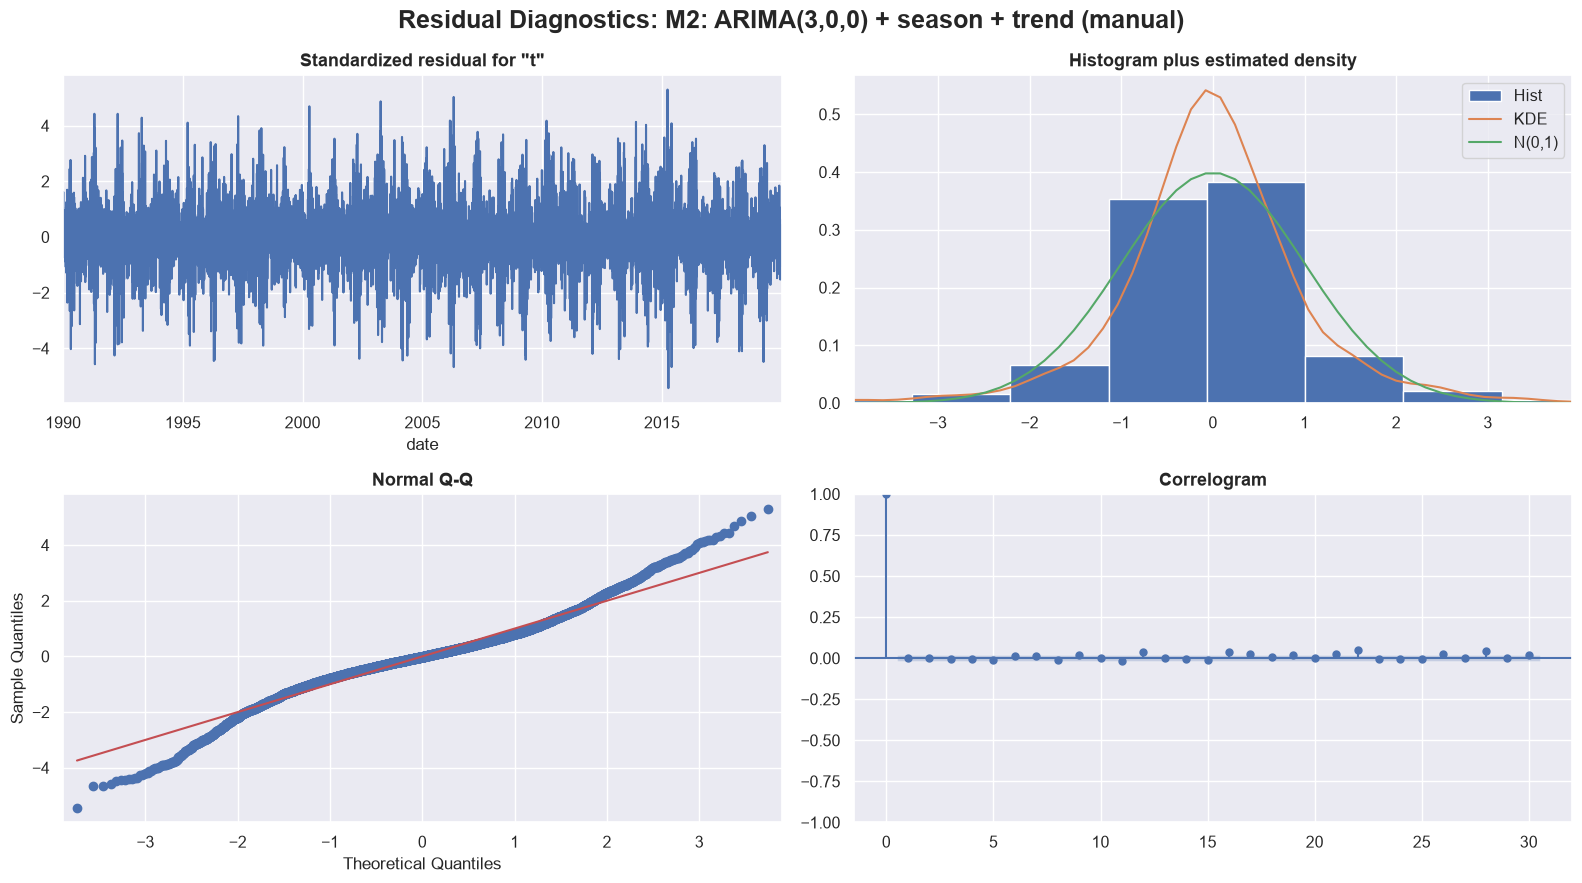

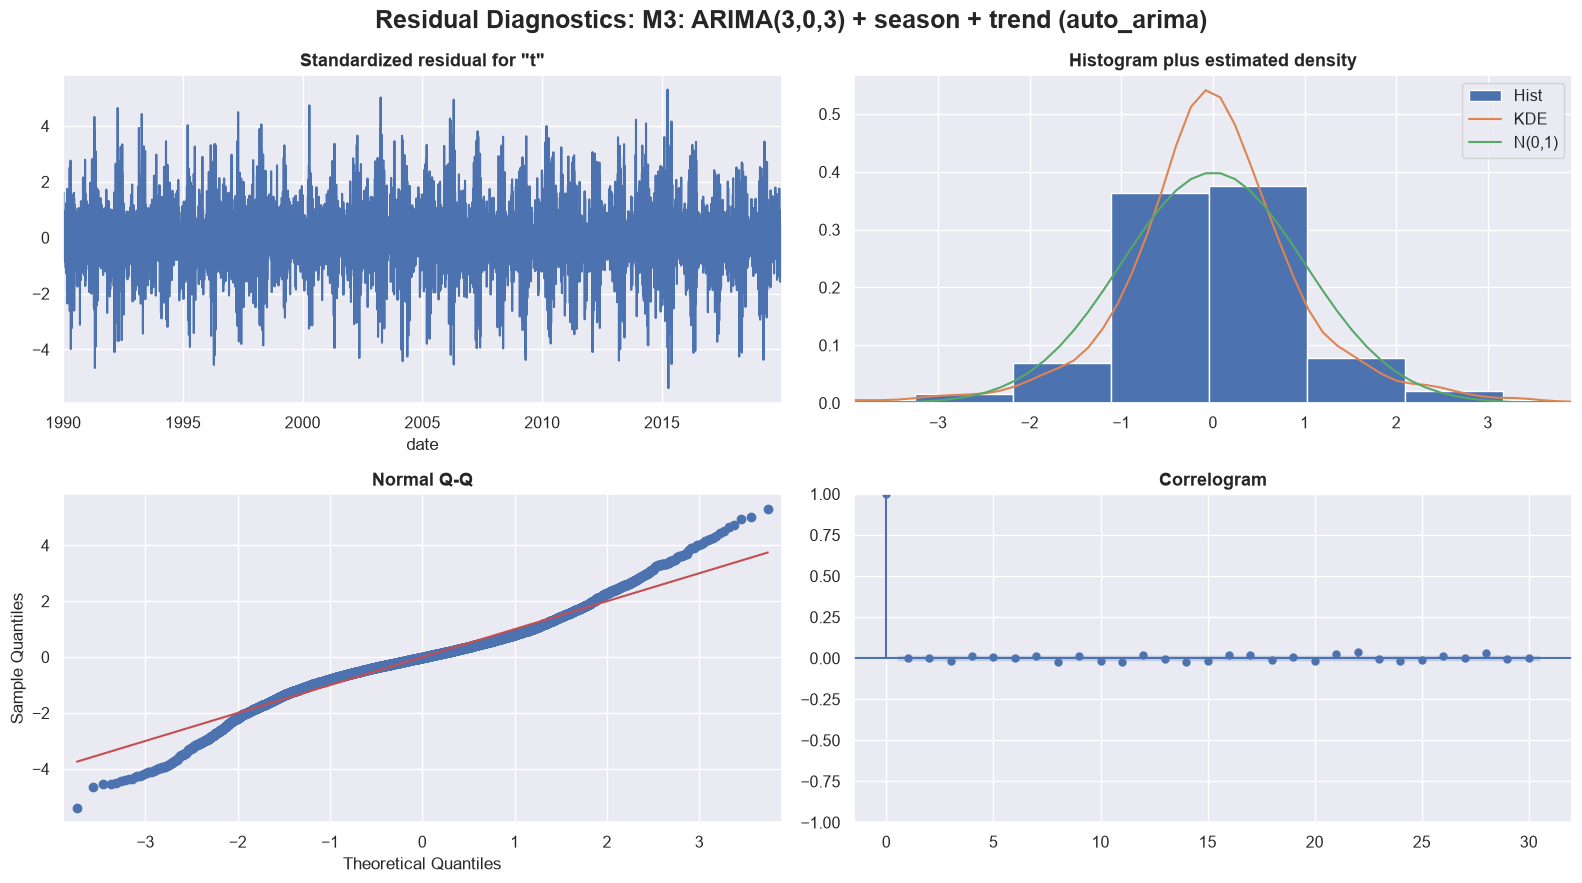

In [101]:
# the four standard residual plots for the two main candidates
for name in ["M2", "M3"]:
    fig = fits[name].plot_diagnostics(figsize=(16, 9), lags=30)
    fig.suptitle("Residual Diagnostics: " + MODELS[name]["label"])
    plt.tight_layout()
    plt.show()

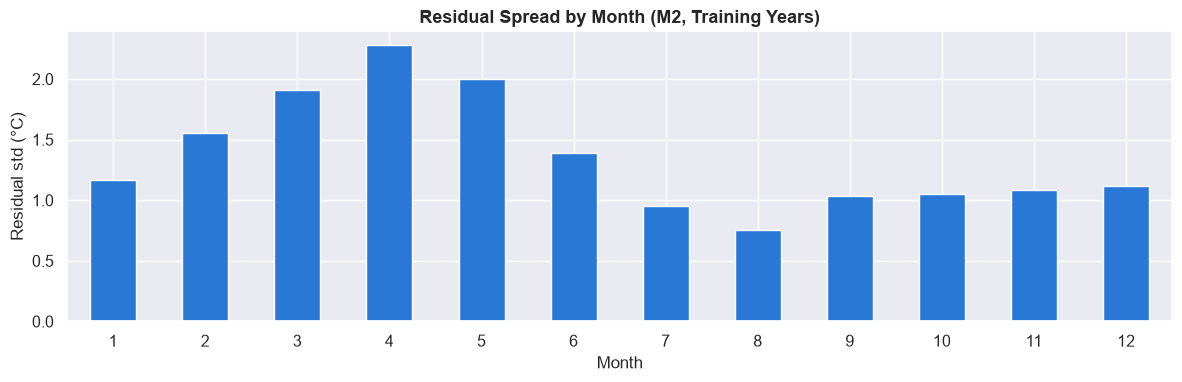

date
2015-04-09   -7.8
2015-03-27    7.6
2006-04-22    7.2
2003-04-04    7.0
2000-04-12    6.7
dtype: float64

In [102]:
# how big the misses are in each month, to see if some seasons are harder
m2_residuals = fits["M2"].resid.iloc[3:]
spread_by_month = m2_residuals.groupby(m2_residuals.index.month).std()

plt.figure(figsize=(12, 4))
spread_by_month.plot(kind="bar", color="#2a78d6")
plt.title("Residual Spread by Month (M2, Training Years)")
plt.xlabel("Month")
plt.ylabel("Residual std (°C)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# the 5 biggest misses
m2_residuals.loc[m2_residuals.abs().nlargest(5).index].round(1)

In [103]:
# saved for the storm story (Step 9): the days the models did not expect
residuals_table = pd.DataFrame({MODELS[name]["label"]: fits[name].resid for name in fits})
residuals_table.to_csv("sarimax_residuals_train.csv")
residuals_table.shape

(10957, 4)

**What we see:**
- **AIC/BIC:** adding the season (M1 → M2) lowers the AIC by about 1,300. M3 and M4 lower it a little more (by 31 and 127).
- **Ljung-Box, lag 7** (with the AR and MA terms counted, `model_df = p + q`): M1 fails (p < 0.001). M2 and M4 pass (p = 0.26 and 0.39): no memory is left from the last week. M3 fails (p = 0.007): with 6 ARMA terms, only 1 degree of freedom is left at lag 7, so the test becomes very strict.
- **Ljung-Box, lag 30:** every model fails (p < 0.001).
- **Diagnostic plots (M2, M3):** the residuals stay around 0 with no trend over 30 years, and the correlogram is flat (every bar close to 0). The histogram is taller and narrower than the normal curve. The Q-Q plot bends away at both ends: big misses (beyond ±2 std) happen more often than a normal curve expects.
- **Spread by month:** the residual std goes from about 0.75 °C in August to 2.3 °C in April. The 5 biggest misses are all in March–April.
- **M2 summary:** the three AR terms are clear (+0.97, −0.35, +0.11; all p < 0.001), matching the PACF in Step 4. The trend is +0.27 °C per 10 years (p < 0.001). The season terms matter except sin_3 (p = 0.40), so K = 3 is the upper limit. Jarque-Bera rejects normality (kurtosis 5.6: heavy tails), and the heteroskedasticity test is just significant (H = 1.09, p = 0.01).
- **Inputs in M4:** yesterday's pressure matters (+0.94, p < 0.001); yesterday's humidity does not (p = 0.96).

**Why:**
- M1 has no season, so part of the yearly cycle stays in its residuals, and Ljung-Box fails even at lag 7.
- **Lag 30:** with almost 11,000 days, Ljung-Box flags even tiny links. The correlogram shows how small they are (about 0.05 at most): the weeks-long warm and cold spells from Step 4. They are not worth more parameters.
- The heavy tails and the spring spread are the storms, desert-wind days and cold snaps of Task 4 (H5, H6): sudden jumps the past days do not announce. Step 9 measures the models on exactly these days.

**What we do with it:** M2 and M4 pass the main check (no short memory left) and go to Step 6. M3 is kept as the auto_arima comparison only. M1 stays only as the "no season" row of the comparison. Because the residuals have heavy tails and change with the season, the 95 % interval is checked month by month (Steps 6 and 8).

## Step 6: Forecasting Tomorrow on the Validation Years (2020–2022)

**What we do:**
1. **One-day-ahead forecasts:** each model keeps the parameters it learned on 1990–2019, then forecasts tomorrow for every day of 2020–2022, using only the days up to today (no refit, no peeking).
2. Score the models and the four baselines on **exactly the same days**, with MAE, RMSE, MAPE, sMAPE and R².
3. Check where the chosen model works and where it fails: forecast vs real with the 95 % interval, error and bias by month, and how often the real value falls inside the interval.
4. Forecast many days ahead to see how the error and the interval grow with the horizon.

**Rule for choosing, written before seeing the scores:** the simplest model (M2) wins, unless another model has a validation MAE lower by more than 0.01 °C. A smaller gap is too small to matter and does not justify more parameters.

**Why:** This is the first honest test: years the models never saw. One-day-ahead is the real question of the project ("tomorrow"), and the only fair comparison with the baselines.

**What we do with it:** The chosen model goes to walk-forward validation (Step 7) and to the final test (Step 8).

In [104]:
def one_step_forecasts(fit, name, today_index):
    # tomorrow's forecast for each "today", with the parameters learned on the training years (no refit)
    target_days = today_index + pd.Timedelta(days=1)
    first_new_day = fit.fittedvalues.index[-1] + pd.Timedelta(days=1)
    new_days = pd.date_range(first_new_day, target_days[-1], freq="D")
    extended = fit.extend(weather["temp_mean"].loc[new_days], exog=model_inputs(new_days, name))
    prediction = extended.get_prediction()
    interval = prediction.conf_int(alpha=0.05)
    return pd.DataFrame({
        "forecast": prediction.predicted_mean.loc[target_days].values,
        "lower": interval.iloc[:, 0].loc[target_days].values,
        "upper": interval.iloc[:, 1].loc[target_days].values,
    }, index=today_index)

# one forecast table per model, on the validation years
valid_forecasts = {name: one_step_forecasts(fits[name], name, temp_valid.index) for name in fits}
valid_forecasts["M2"].head()

,forecast,lower,upper
date,,,
2020-01-01,11.906802,9.103138,14.710466
2020-01-02,10.725588,7.921924,13.529252
2020-01-03,10.943396,8.139732,13.747060
2020-01-04,11.143460,8.339796,13.947124
2020-01-05,10.106485,7.302820,12.910149


In [105]:
# models and baselines, scored on the same days
rows = []
for name in fits:
    scores = regression_scores(temp_valid["temp_tomorrow"], valid_forecasts[name]["forecast"])
    scores["Forecast"] = MODELS[name]["label"]
    rows.append(scores)
for baseline in temp_baselines.columns:
    scores = regression_scores(temp_valid["temp_tomorrow"], temp_baselines.loc[temp_valid.index, baseline])
    scores["Forecast"] = "Baseline: " + baseline
    rows.append(scores)

valid_results = pd.DataFrame(rows).set_index("Forecast").sort_values("MAE (°C)")
valid_results.round(3)

,MAE (°C),RMSE (°C),MAPE (%),sMAPE (%),R²
Forecast,,,,,
"M3: ARIMA(3,0,3) + season + trend (auto_arima)",0.990,1.368,5.305,5.190,0.962
"M2: ARIMA(3,0,0) + season + trend (manual)",0.992,1.373,5.337,5.210,0.962
"M4: ARIMA(3,0,0) + season + trend + yesterday's humidity and pressure",0.994,1.363,5.337,5.215,0.962
"M1: ARIMA(3,0,0), no season",1.032,1.431,5.421,5.337,0.959
Baseline: Persistence (today),1.072,1.487,5.583,5.532,0.955
Baseline: Mean of last 7 days,1.588,2.143,8.368,8.284,0.907
Baseline: Climatology (normal for tomorrow),1.841,2.395,10.131,9.824,0.884
Baseline: Same day last year,2.564,3.346,14.011,13.565,0.773


In [106]:
# how much better than "tomorrow = today"
persistence_mae = valid_results.loc["Baseline: Persistence (today)", "MAE (°C)"]
for name in fits:
    model_mae = valid_results.loc[MODELS[name]["label"], "MAE (°C)"]
    print(MODELS[name]["label"], "->", round(100 * (persistence_mae - model_mae) / persistence_mae, 1), "% lower MAE than persistence")

# the simplest model wins unless another is better by more than 0.01 °C
mae = {name: valid_results.loc[MODELS[name]["label"], "MAE (°C)"] for name in ["M2", "M3", "M4"]}
chosen = "M2"
for name in ["M4", "M3"]:
    if mae[name] < mae[chosen] - 0.01:
        chosen = name
print("\nChosen model:", MODELS[chosen]["label"])
chosen_forecast = valid_forecasts[chosen]

M1: ARIMA(3,0,0), no season -> 3.7 % lower MAE than persistence
M2: ARIMA(3,0,0) + season + trend (manual) -> 7.5 % lower MAE than persistence
M3: ARIMA(3,0,3) + season + trend (auto_arima) -> 7.6 % lower MAE than persistence
M4: ARIMA(3,0,0) + season + trend + yesterday's humidity and pressure -> 7.3 % lower MAE than persistence

Chosen model: M2: ARIMA(3,0,0) + season + trend (manual)


**What we see:**
- All three seasonal models beat every baseline: MAE 0.990 (M3), 0.992 (M2), 0.994 (M4), against 1.072 for "tomorrow = today". That is about **7.5 % lower** (0.08 °C). RMSE drops from 1.49 to about 1.37 °C, and MAPE from 5.6 % to 5.3 %.
- M1 (no season) also beats persistence a little (1.032), but clearly less than the seasonal models.
- The gap between M2, M3 and M4 is only 0.004 °C. M4 has the lowest RMSE (1.363), but not the lowest MAE.

**Why:** Persistence assumes a day warmer than normal stays that warm. The models know it moves back toward the normal for the date (the link with yesterday is 0.76, not 1; Step 4). That is the whole gain, and it is small, as expected from Task 4. Yesterday's pressure helped on the training years (Step 5), but on new years it adds nothing once the model knows the last 3 days.

**What we do with it:** By the rule written above, **M2 is chosen**: ARIMA(3,0,0) + season + trend, the manual choice from the PACF. M3 and M4 stay in the walk-forward check (Step 7) to confirm this on more years.

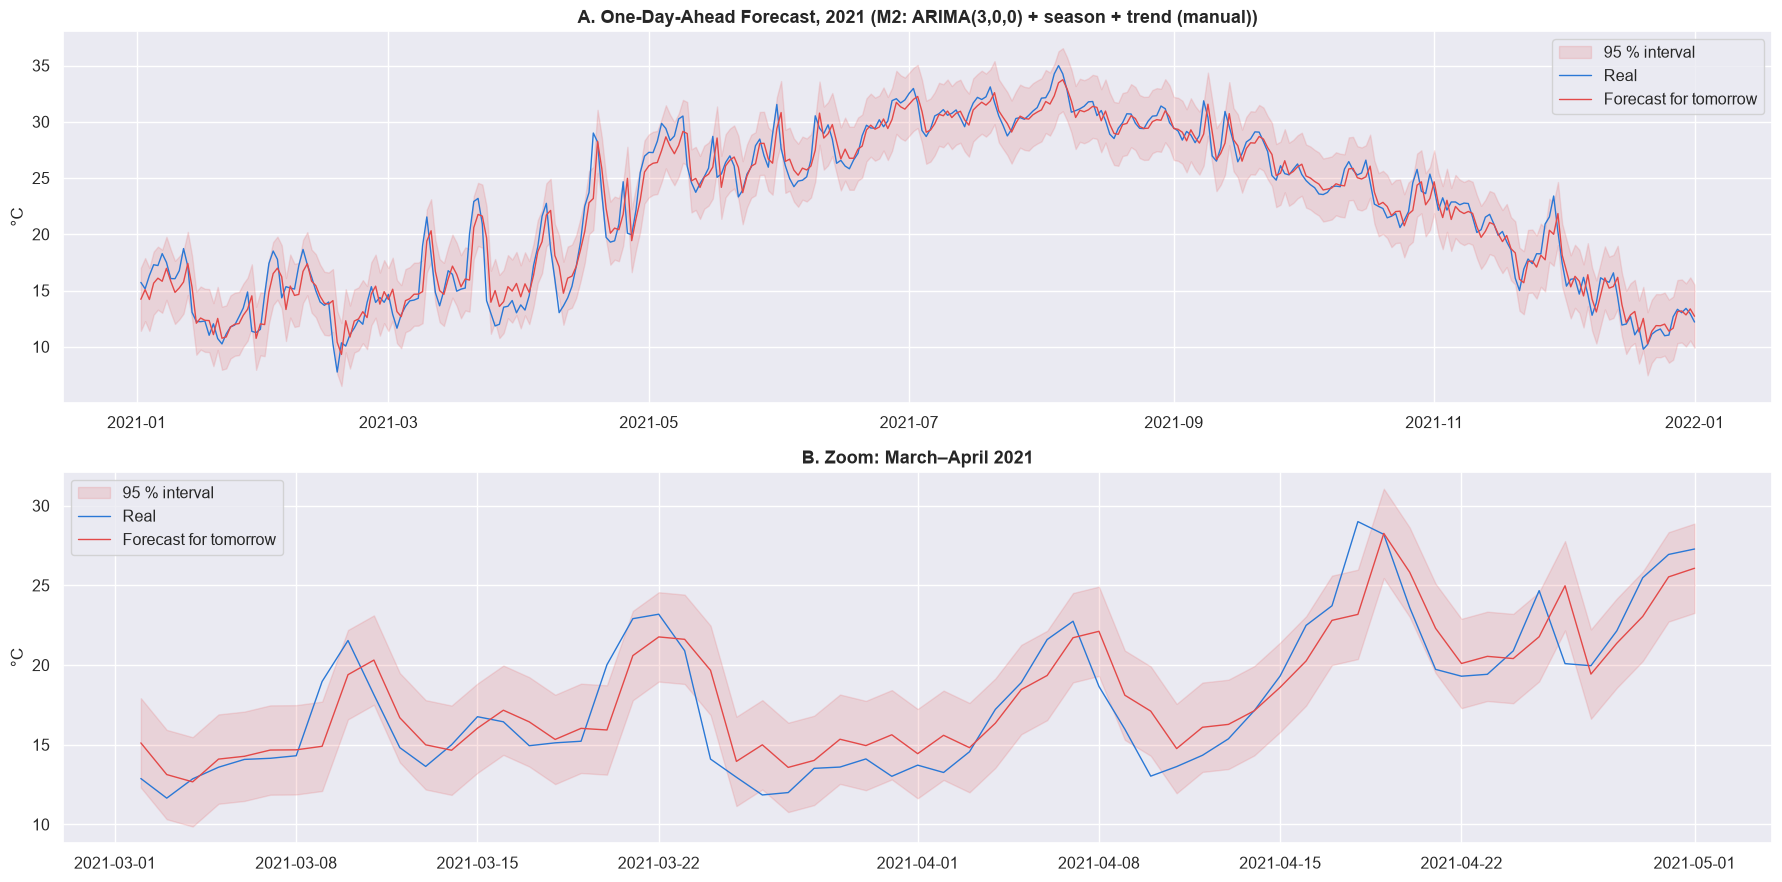

In [107]:
# one-day-ahead forecasts with the 95 % interval, plotted on the day they forecast
actual = temp_valid["temp_tomorrow"]

fig, ax = plt.subplots(nrows=2, figsize=(18, 9))
periods = [slice("2021-01-01", "2021-12-31"), slice("2021-03-01", "2021-04-30")]
for i, period in enumerate(periods):
    part = chosen_forecast.loc[period]
    days = part.index + pd.Timedelta(days=1)
    ax[i].fill_between(days, part["lower"], part["upper"], color="#e34948", alpha=0.15, label="95 % interval")
    ax[i].plot(days, actual.loc[period], color="#2a78d6", linewidth=1, label="Real")
    ax[i].plot(days, part["forecast"], color="#e34948", linewidth=1, label="Forecast for tomorrow")
    ax[i].set_ylabel("°C")
    ax[i].legend()
ax[0].set_title("A. One-Day-Ahead Forecast, 2021 (" + MODELS[chosen]["label"] + ")")
ax[1].set_title("B. Zoom: March–April 2021")
plt.tight_layout()
plt.show()

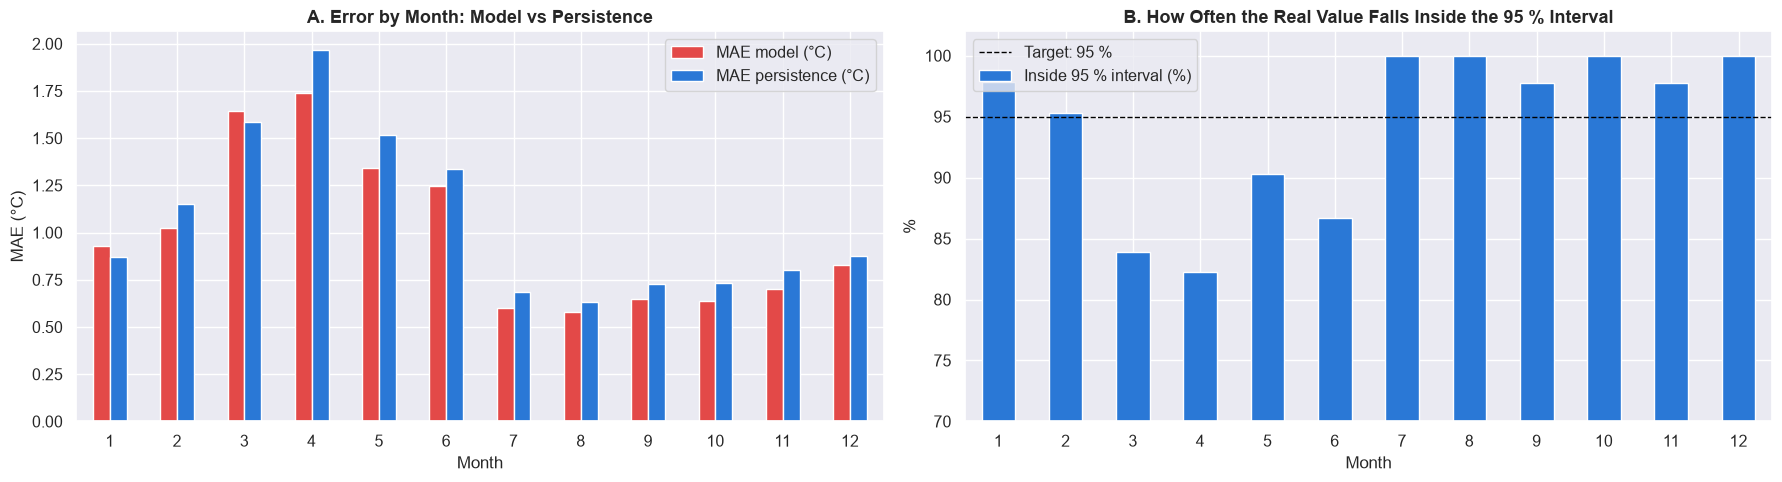

Overall inside the interval: 94.3 %
Overall bias (real − forecast): -0.055 °C


,MAE model (°C),MAE persistence (°C),Bias: real − forecast (°C),Inside 95 % interval (%)
Month,,,,
1,0.93,0.87,-0.15,97.85
2,1.03,1.15,-0.19,95.29
3,1.64,1.58,-0.56,83.87
4,1.74,1.97,-0.26,82.22
5,1.34,1.52,-0.08,90.32
6,1.25,1.33,-0.15,86.67
7,0.60,0.69,-0.00,100.00
8,0.58,0.63,0.16,100.00
9,0.65,0.73,0.23,97.78


In [108]:
# error, bias and interval coverage for each month, on the day being forecast
by_day = pd.DataFrame({
    "real": actual.values,
    "forecast": chosen_forecast["forecast"].values,
    "persistence": temp_baselines.loc[temp_valid.index, "Persistence (today)"].values,
    "inside": ((actual >= chosen_forecast["lower"]) & (actual <= chosen_forecast["upper"])).values,
}, index=temp_valid.index + pd.Timedelta(days=1))
month = by_day.index.month

month_table = pd.DataFrame({
    "MAE model (°C)": (by_day["real"] - by_day["forecast"]).abs().groupby(month).mean(),
    "MAE persistence (°C)": (by_day["real"] - by_day["persistence"]).abs().groupby(month).mean(),
    "Bias: real − forecast (°C)": (by_day["real"] - by_day["forecast"]).groupby(month).mean(),
    "Inside 95 % interval (%)": 100 * by_day["inside"].groupby(month).mean(),
})
month_table.index.name = "Month"

fig, ax = plt.subplots(ncols=2, figsize=(18, 5))
month_table[["MAE model (°C)", "MAE persistence (°C)"]].plot(kind="bar", ax=ax[0], color=["#e34948", "#2a78d6"])
ax[0].set_title("A. Error by Month: Model vs Persistence")
ax[0].set_ylabel("MAE (°C)")
ax[0].tick_params(axis="x", rotation=0)
month_table["Inside 95 % interval (%)"].plot(kind="bar", ax=ax[1], color="#2a78d6")
ax[1].axhline(95, color="black", linestyle="--", linewidth=1, label="Target: 95 %")
ax[1].set_ylim(70, 102)
ax[1].set_title("B. How Often the Real Value Falls Inside the 95 % Interval")
ax[1].set_ylabel("%")
ax[1].tick_params(axis="x", rotation=0)
ax[1].legend()
plt.tight_layout()
plt.show()

print("Overall inside the interval:", round(100 * by_day["inside"].mean(), 1), "%")
print("Overall bias (real − forecast):", round((by_day["real"] - by_day["forecast"]).mean(), 3), "°C")
month_table.round(2)

**What we see:**
- **Forecast vs real:** the forecast follows the real temperature closely all year. In the March–April zoom, it reacts **one day late** to sudden jumps: it misses the first hot or cold day, then catches up.
- **Error by month:** the model beats persistence in 10 of 12 months; not in January (0.93 vs 0.87 °C) and March (1.64 vs 1.58 °C). Errors are biggest from March to June (1.25–1.74 °C) and smallest from July to October (0.58–0.65 °C).
- **Bias:** −0.06 °C overall (the forecast is a little too warm), largest in March (−0.56 °C). There is **no cold bias** on the validation years.
- **Interval:** 94.3 % of real values fall inside the 95 % interval overall, close to the target. But by month it is wrong in both directions: 82–87 % in March, April and June (too narrow), and 100 % in July, August, October and December (too wide). The interval is always about 5.6 °C wide.

**Why:**
- The model only knows the days up to today. A sudden desert-wind day or a cold air mass cannot be seen coming in daily data (Task 4, H5), so the first day of a jump is always missed.
- The interval has the same width all year, but the real misses are about 3 times bigger in April than in August (Step 5). On average it is right; season by season it is not.
- The trend learned on 1990–2019 pushes the forecast up a little; March in 2020–2022 was cooler than that, hence the small warm bias.

**What we do with it:** Report errors by month in the final table, not only one number. State that the 95 % interval is reliable on average but too narrow in spring and too wide in summer; a model whose spread changes with the season is a possible next step. The cold-bias check from Task 4 (H1) is repeated on the warmest years, 2023–2025, in Step 8.

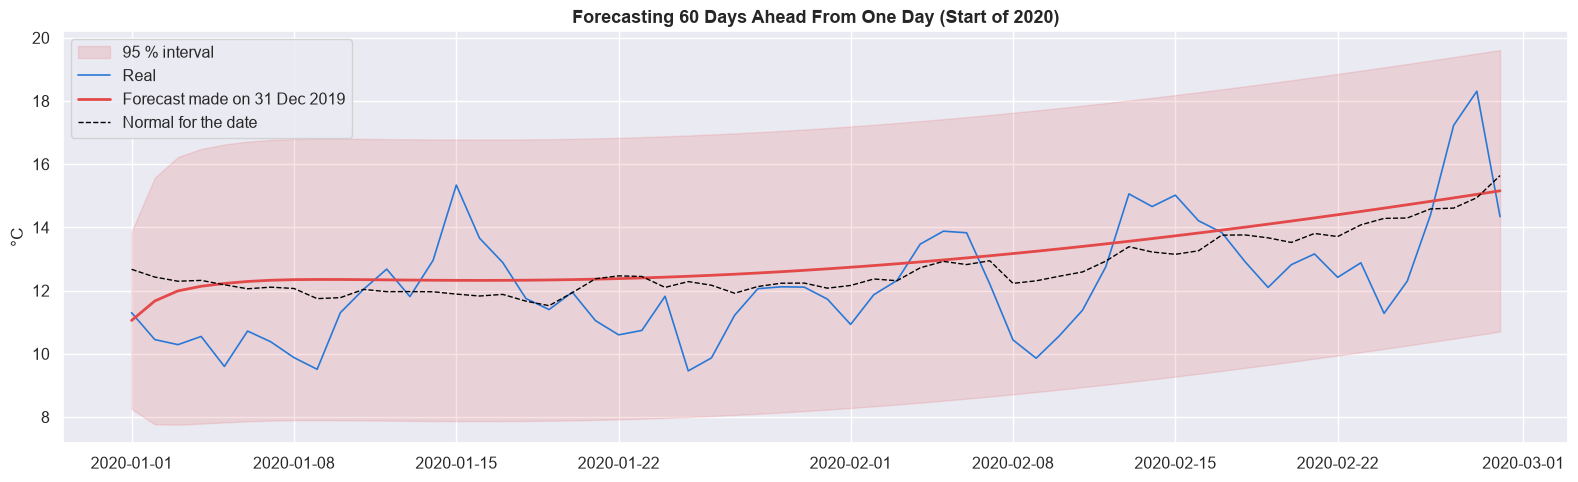

Interval width: day 1 = 5.6 °C | day 7 = 8.9 °C | day 60 = 8.9 °C


In [109]:
# one forecast made on 31 Dec 2019 for the next 60 days, to see how the interval grows
steps = 60
future_days = pd.date_range("2020-01-01", periods=steps, freq="D")
multi_step = fits[chosen].get_forecast(steps=steps, exog=model_inputs(future_days, chosen))
multi_interval = multi_step.conf_int(alpha=0.05)

plt.figure(figsize=(16, 5))
plt.fill_between(future_days, multi_interval.iloc[:, 0], multi_interval.iloc[:, 1], color="#e34948", alpha=0.15, label="95 % interval")
plt.plot(future_days, weather.loc[future_days, "temp_mean"], color="#2a78d6", linewidth=1.2, label="Real")
plt.plot(future_days, multi_step.predicted_mean, color="#e34948", linewidth=2, label="Forecast made on 31 Dec 2019")
plt.plot(future_days, normal_by_day.reindex(future_days.dayofyear).values, color="black", linestyle="--", linewidth=1, label="Normal for the date")
plt.title("Forecasting 60 Days Ahead From One Day (Start of 2020)")
plt.ylabel("°C")
plt.legend()
plt.tight_layout()
plt.show()

width = multi_interval.iloc[:, 1] - multi_interval.iloc[:, 0]
print("Interval width: day 1 =", round(width.iloc[0], 1), "°C | day 7 =", round(width.iloc[6], 1), "°C | day 60 =", round(width.iloc[59], 1), "°C")

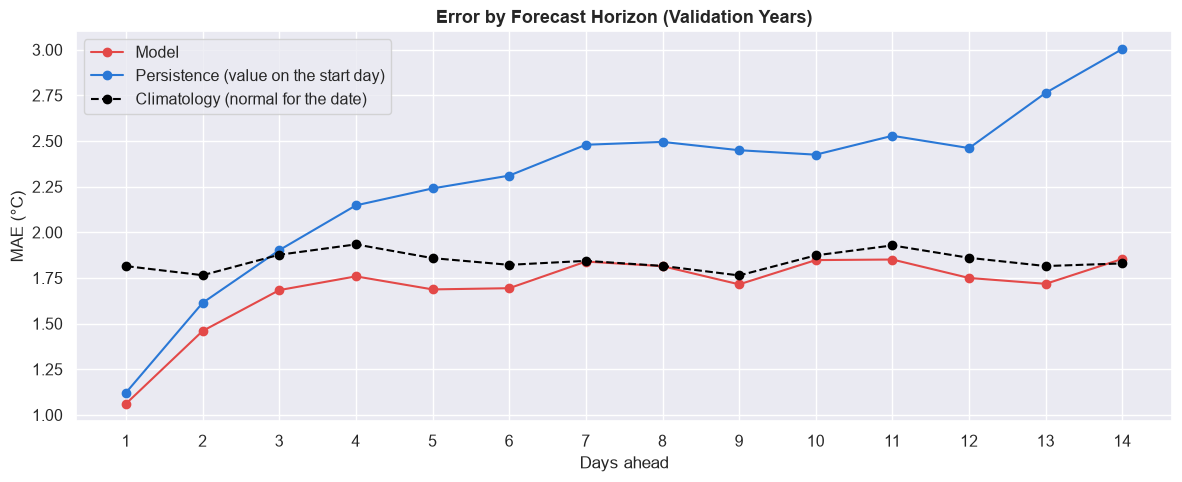

,Model,Persistence,Climatology
Horizon (days),,,
1,1.06,1.12,1.82
2,1.46,1.61,1.77
3,1.68,1.90,1.88
4,1.76,2.15,1.93
5,1.69,2.24,1.86
6,1.69,2.31,1.82
7,1.84,2.48,1.84
8,1.81,2.50,1.82
9,1.72,2.45,1.76


In [110]:
# forecasts 1 to 14 days ahead, starting every 7th day of the validation years
first_new_day = fits[chosen].fittedvalues.index[-1] + pd.Timedelta(days=1)
new_days = pd.date_range(first_new_day, "2022-12-31", freq="D")
extended = fits[chosen].extend(weather["temp_mean"].loc[new_days], exog=model_inputs(new_days, chosen))

HORIZON = 14
rows = []
for start_day in pd.date_range("2020-01-01", "2022-12-17", freq="7D"):
    first = start_day + pd.Timedelta(days=1)
    last = start_day + pd.Timedelta(days=HORIZON)
    # dynamic=True: after the start day, the model uses its own forecasts, not the real values
    path = extended.get_prediction(start=first, end=last, dynamic=True).predicted_mean
    for h, day in enumerate(pd.date_range(first, last), start=1):
        real = weather.loc[day, "temp_mean"]
        rows.append({
            "Horizon (days)": h,
            "Model": abs(real - path.loc[day]),
            "Persistence": abs(real - weather.loc[start_day, "temp_mean"]),
            "Climatology": abs(real - normal_by_day.loc[day.dayofyear]),
        })

horizon_table = pd.DataFrame(rows).groupby("Horizon (days)").mean()

plt.figure(figsize=(12, 5))
plt.plot(horizon_table.index, horizon_table["Model"], marker="o", color="#e34948", label="Model")
plt.plot(horizon_table.index, horizon_table["Persistence"], marker="o", color="#2a78d6", label="Persistence (value on the start day)")
plt.plot(horizon_table.index, horizon_table["Climatology"], marker="o", color="black", linestyle="--", label="Climatology (normal for the date)")
plt.title("Error by Forecast Horizon (Validation Years)")
plt.xlabel("Days ahead")
plt.ylabel("MAE (°C)")
plt.xticks(horizon_table.index)
plt.legend()
plt.tight_layout()
plt.show()

horizon_table.round(2)

**What we see:**
- **60 days ahead:** after about a week, the forecast becomes a smooth line that follows the normal for the date (slightly above it, because of the warming trend). The 95 % interval widens from 5.6 °C on day 1 to 8.9 °C by day 7, then stays the same.
- **Error by horizon** (155 start days, so day 1 is 1.06 °C here, not exactly the 0.99 °C above): the model beats persistence at every horizon, and beats climatology up to about 6 days ahead (day 4: 1.76 vs 1.93 °C). From day 7 on, the model and climatology are equal (1.84 °C). Persistence is worse than climatology from day 3 on.

**Why:** The weather's memory lasts only a few days (Step 4: PACF stops after 3 days; Task 4: about 5 days). After that, the best guess is the calendar, and the model knows it, so it falls back to the normal for the date. Persistence does not, so it keeps getting worse.

**What we do with it:** The useful range of this model is **about a week**; beyond that it is a climatology forecast. For the storm story (Step 9), this sets the limit: from daily data alone, a warning more than a few days ahead is not realistic.

## Step 7: Walk-Forward Validation (Expanding Window)

**What we do:** Repeat the validation one year at a time. For each test year, refit the models on **all** the years before it (from 1990), then forecast tomorrow for every day of that year:

| Fold | Fit on | Forecast |
|---|---|---|
| 1 | 1990–2019 (30 years) | 2020 |
| 2 | 1990–2020 (31 years) | 2021 |
| 3 | 1990–2021 (32 years) | 2022 |

The baselines are scored on the same days; the climatology normals are recomputed from the years before each test year only. Then, as an extra check, the chosen model M2 is run the same way on **13 test years** (2010–2022).

**Why:** One validation period gives one number, and one number can be luck: a calm year makes every model look good. Refitting each year and testing on the next shows whether the gain over persistence is stable, the way the model would be used for real (retrained as new years arrive). The test years (2023–2025) are still not touched.

**What we do with it:** If M2 beats persistence in every year and stays close to M3 and M4, the choice from Step 6 is confirmed, and M2 goes to the final test.

In [111]:
def walk_forward(model_names, test_years):
    # for each test year: refit on all years before it, then forecast tomorrow for every day of that year
    rows = []
    for year in test_years:
        train_y = weather["temp_mean"].loc["1990":str(year - 1)]
        today_index = data.loc[str(year)].index
        real = data.loc[today_index, "temp_tomorrow"]

        for name in model_names:
            model = SARIMAX(train_y, exog=model_inputs(train_y.index, name), order=MODELS[name]["order"])
            fit = model.fit(disp=False, maxiter=200)
            forecast = one_step_forecasts(fit, name, today_index)["forecast"]
            rows.append({
                "Test year": year,
                "Forecast": MODELS[name]["label"],
                "MAE (°C)": mean_absolute_error(real, forecast),
                "RMSE (°C)": np.sqrt(mean_squared_error(real, forecast)),
            })

        # the two main baselines, with normals from the years before the test year only
        normal_y = train_y.groupby(train_y.index.dayofyear).mean()
        baselines = {
            "Baseline: Persistence (today)": data.loc[today_index, "temp_mean"],
            "Baseline: Climatology (normal for tomorrow)": normal_y.reindex((today_index + pd.Timedelta(days=1)).dayofyear).values,
        }
        for label, forecast in baselines.items():
            rows.append({
                "Test year": year,
                "Forecast": label,
                "MAE (°C)": mean_absolute_error(real, forecast),
                "RMSE (°C)": np.sqrt(mean_squared_error(real, forecast)),
            })
    return pd.DataFrame(rows)

In [112]:
# three folds: 2020, 2021, 2022 (takes a few minutes: 9 model fits)
walk_forward_results = walk_forward(["M2", "M3", "M4"], [2020, 2021, 2022])

wf_mae = walk_forward_results.pivot(index="Forecast", columns="Test year", values="MAE (°C)")
wf_mae["Mean"] = wf_mae[[2020, 2021, 2022]].mean(axis=1)
wf_mae["Range (max − min)"] = wf_mae[[2020, 2021, 2022]].max(axis=1) - wf_mae[[2020, 2021, 2022]].min(axis=1)
wf_mae.sort_values("Mean").round(3)

Test year,2020,2021,2022,Mean,Range (max − min)
Forecast,,,,,
"M3: ARIMA(3,0,3) + season + trend (auto_arima)",0.994,1.028,0.947,0.990,0.081
"M2: ARIMA(3,0,0) + season + trend (manual)",1.000,1.024,0.950,0.991,0.073
"M4: ARIMA(3,0,0) + season + trend + yesterday's humidity and pressure",1.004,1.019,0.956,0.993,0.062
Baseline: Persistence (today),1.096,1.122,0.997,1.072,0.126
Baseline: Climatology (normal for tomorrow),1.761,2.040,1.714,1.838,0.326


In [113]:
wf_rmse = walk_forward_results.pivot(index="Forecast", columns="Test year", values="RMSE (°C)")
wf_rmse["Mean"] = wf_rmse[[2020, 2021, 2022]].mean(axis=1)
wf_rmse.sort_values("Mean").round(3)

Test year,2020,2021,2022,Mean
Forecast,,,,
"M4: ARIMA(3,0,0) + season + trend + yesterday's humidity and pressure",1.377,1.372,1.337,1.362
"M3: ARIMA(3,0,3) + season + trend (auto_arima)",1.370,1.394,1.336,1.367
"M2: ARIMA(3,0,0) + season + trend (manual)",1.388,1.389,1.340,1.372
Baseline: Persistence (today),1.498,1.537,1.425,1.486
Baseline: Climatology (normal for tomorrow),2.209,2.628,2.323,2.387


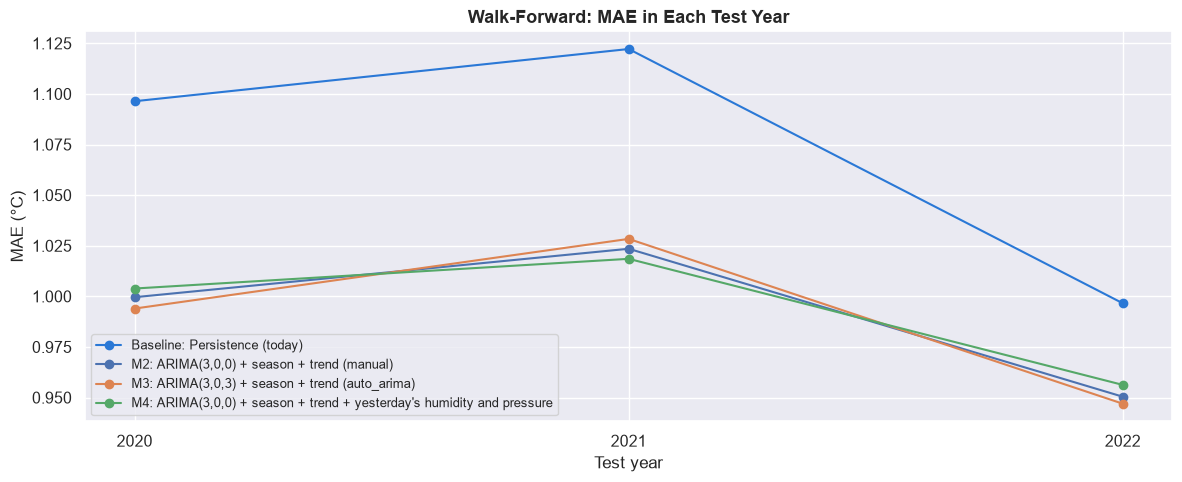

In [114]:
# MAE in each test year, models vs persistence
plt.figure(figsize=(12, 5))
for label in wf_mae.index:
    if "Climatology" in label:
        continue  # much higher (about 1.8 °C), shown in the table only
    color = "#2a78d6" if "Persistence" in label else None
    plt.plot([2020, 2021, 2022], wf_mae.loc[label, [2020, 2021, 2022]], marker="o", color=color, label=label)
plt.title("Walk-Forward: MAE in Each Test Year")
plt.xlabel("Test year")
plt.ylabel("MAE (°C)")
plt.xticks([2020, 2021, 2022])
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

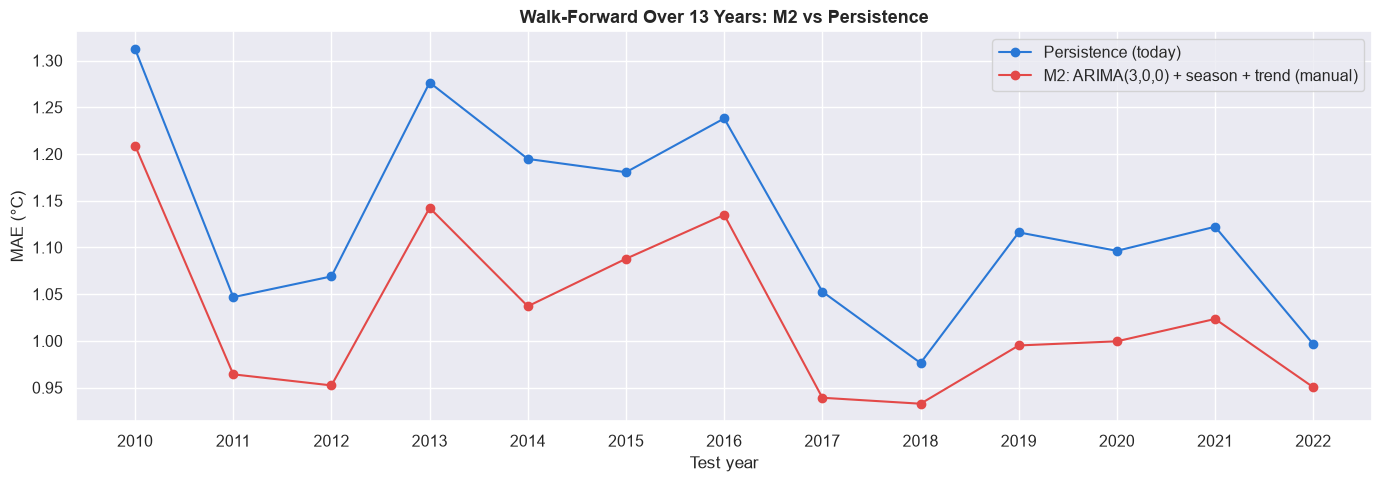

Years where M2 beats persistence: 13 of 13
Mean gain: 8.8 % | smallest: 4.5 % | largest: 13.2 %


Forecast,Baseline: Climatology (normal for tomorrow),Baseline: Persistence (today),"M2: ARIMA(3,0,0) + season + trend (manual)",Gain vs persistence (%)
Test year,,,,
2010,2.358,1.312,1.209,7.875
2011,1.663,1.047,0.964,7.890
2012,1.592,1.069,0.952,10.911
2013,1.920,1.276,1.142,10.506
2014,1.452,1.195,1.037,13.196
2015,1.905,1.181,1.088,7.843
2016,1.999,1.238,1.135,8.335
2017,1.613,1.053,0.939,10.785
2018,1.448,0.976,0.933,4.461


In [115]:
# extra check: the chosen model on 13 test years (2010-2022), each fitted only on the years before it
long_results = walk_forward(["M2"], list(range(2010, 2023)))
long_mae = long_results.pivot(index="Test year", columns="Forecast", values="MAE (°C)")
model_label = MODELS["M2"]["label"]
long_mae["Gain vs persistence (%)"] = 100 * (long_mae["Baseline: Persistence (today)"] - long_mae[model_label]) / long_mae["Baseline: Persistence (today)"]

plt.figure(figsize=(14, 5))
plt.plot(long_mae.index, long_mae["Baseline: Persistence (today)"], marker="o", color="#2a78d6", label="Persistence (today)")
plt.plot(long_mae.index, long_mae[model_label], marker="o", color="#e34948", label=model_label)
plt.title("Walk-Forward Over 13 Years: M2 vs Persistence")
plt.xlabel("Test year")
plt.ylabel("MAE (°C)")
plt.xticks(long_mae.index)
plt.legend()
plt.tight_layout()
plt.show()

print("Years where M2 beats persistence:", (long_mae["Gain vs persistence (%)"] > 0).sum(), "of", len(long_mae))
print("Mean gain:", round(long_mae["Gain vs persistence (%)"].mean(), 1), "% | smallest:", round(long_mae["Gain vs persistence (%)"].min(), 1), "% | largest:", round(long_mae["Gain vs persistence (%)"].max(), 1), "%")
long_mae.round(3)

**What we see:**
- **Three folds (2020–2022):** mean MAE 0.990 (M3), 0.991 (M2), 0.993 (M4), against 1.072 for persistence and 1.838 for climatology. All three models beat persistence in **every** year, by 0.04–0.10 °C. The gap between the models stays at 0.001–0.003 °C. In RMSE, M4 is lowest (1.362 vs 1.372 for M2), again a very small gap.
- **Year to year:** every forecast moves together: 2021 is the hardest year and 2022 the easiest, for the models and the baselines alike. The models move less than persistence (range 0.06–0.08 °C vs 0.13 °C).
- **13 years (2010–2022), M2 only:** M2 beats persistence in **13 of 13** years. The gain ranges from 4.5 % (2018) to 13.2 % (2014), 8.8 % on average (MAE 1.03 vs 1.13 °C).

**Why:** The gain comes from the same simple fact every year: a day warmer or colder than normal tends to move back toward the normal, and persistence ignores this. How much it helps depends on the year: in calm years, today is already a very good guess, so there is less to gain. A hard year (2021) is hard for every method, because the weather itself jumped more.

**What we do with it:** The choice from Step 6 is confirmed: **M2**, the manual ARIMA(3,0,0) + season + trend, is as good as the bigger models, simpler, and beats persistence in every year tested. M2 goes to the final test (Step 8), refitted on 1990–2022. Expected test MAE: around 0.95–1.05 °C, depending on how calm 2023–2025 were.

## Step 8: Final Test (2023–2025), Run Once

**What we do:** Refit the models on all years before the test (1990–2022), then forecast tomorrow for every day of 2023–2025, exactly as in Steps 6 and 7. Score them against the same baselines as Task 4, and check:
1. the forecast against the real temperature, with the 95 % interval (the Task 5 forecast plot);
2. errors, bias and interval coverage by year and by month;
3. **the cold-bias question from Task 4 (H1):** the test years are the warmest, so is the model too cold, especially on very hot days?

**Fixed before this step (rule 7):** the chosen model is **M2**, ARIMA(3,0,0) + season (K = 3) + trend, chosen in Step 6 and confirmed in Step 7. The other models are scored only to fill the comparison table; the choice does not change, whatever the test shows.

**Why:** The test years were never used to choose anything, so this is the honest estimate of how the model will do on new years.

**What we do with it:** These are the final numbers for the comparison table (Step 11) and the README.

In [116]:
# FINAL TEST: run this cell once. Nothing is changed after it.
chosen = "M2"

# refit on every year before the test
final_train = weather["temp_mean"].loc["1990":"2022"]
final_fits = {}
test_forecasts = {}
for name in MODELS:
    model = SARIMAX(final_train, exog=model_inputs(final_train.index, name), order=MODELS[name]["order"])
    final_fits[name] = model.fit(disp=False, maxiter=200)
    test_forecasts[name] = one_step_forecasts(final_fits[name], name, temp_test.index)

# models and baselines, on the same test days
rows = []
for name in MODELS:
    scores = regression_scores(temp_test["temp_tomorrow"], test_forecasts[name]["forecast"])
    scores["Forecast"] = MODELS[name]["label"] + (" ← chosen" if name == chosen else "")
    rows.append(scores)
for baseline in temp_baselines.columns:
    scores = regression_scores(temp_test["temp_tomorrow"], temp_baselines.loc[temp_test.index, baseline])
    scores["Forecast"] = "Baseline: " + baseline
    rows.append(scores)

test_results = pd.DataFrame(rows).set_index("Forecast").sort_values("MAE (°C)")
test_persistence = test_results.loc["Baseline: Persistence (today)", "MAE (°C)"]
test_chosen = test_results.loc[MODELS[chosen]["label"] + " ← chosen", "MAE (°C)"]
print("Chosen model on test:", round(test_chosen, 3), "°C vs persistence", round(test_persistence, 3), "°C ->",
      round(100 * (test_persistence - test_chosen) / test_persistence, 1), "% lower")
test_results.round(3)

Chosen model on test: 0.94 °C vs persistence 1.038 °C -> 9.5 % lower


,MAE (°C),RMSE (°C),MAPE (%),sMAPE (%),R²
Forecast,,,,,
"M3: ARIMA(3,0,3) + season + trend (auto_arima)",0.937,1.282,4.554,4.525,0.965
"M4: ARIMA(3,0,0) + season + trend + yesterday's humidity and pressure",0.937,1.277,4.526,4.507,0.966
"M2: ARIMA(3,0,0) + season + trend (manual) ← chosen",0.940,1.286,4.543,4.526,0.965
"M1: ARIMA(3,0,0), no season",0.984,1.368,4.762,4.708,0.960
Baseline: Persistence (today),1.038,1.443,5.006,4.968,0.956
Baseline: Mean of last 7 days,1.540,2.062,7.591,7.535,0.910
Baseline: Climatology (normal for tomorrow),1.794,2.326,8.660,8.894,0.886
Baseline: Same day last year,2.268,2.925,11.334,11.537,0.819


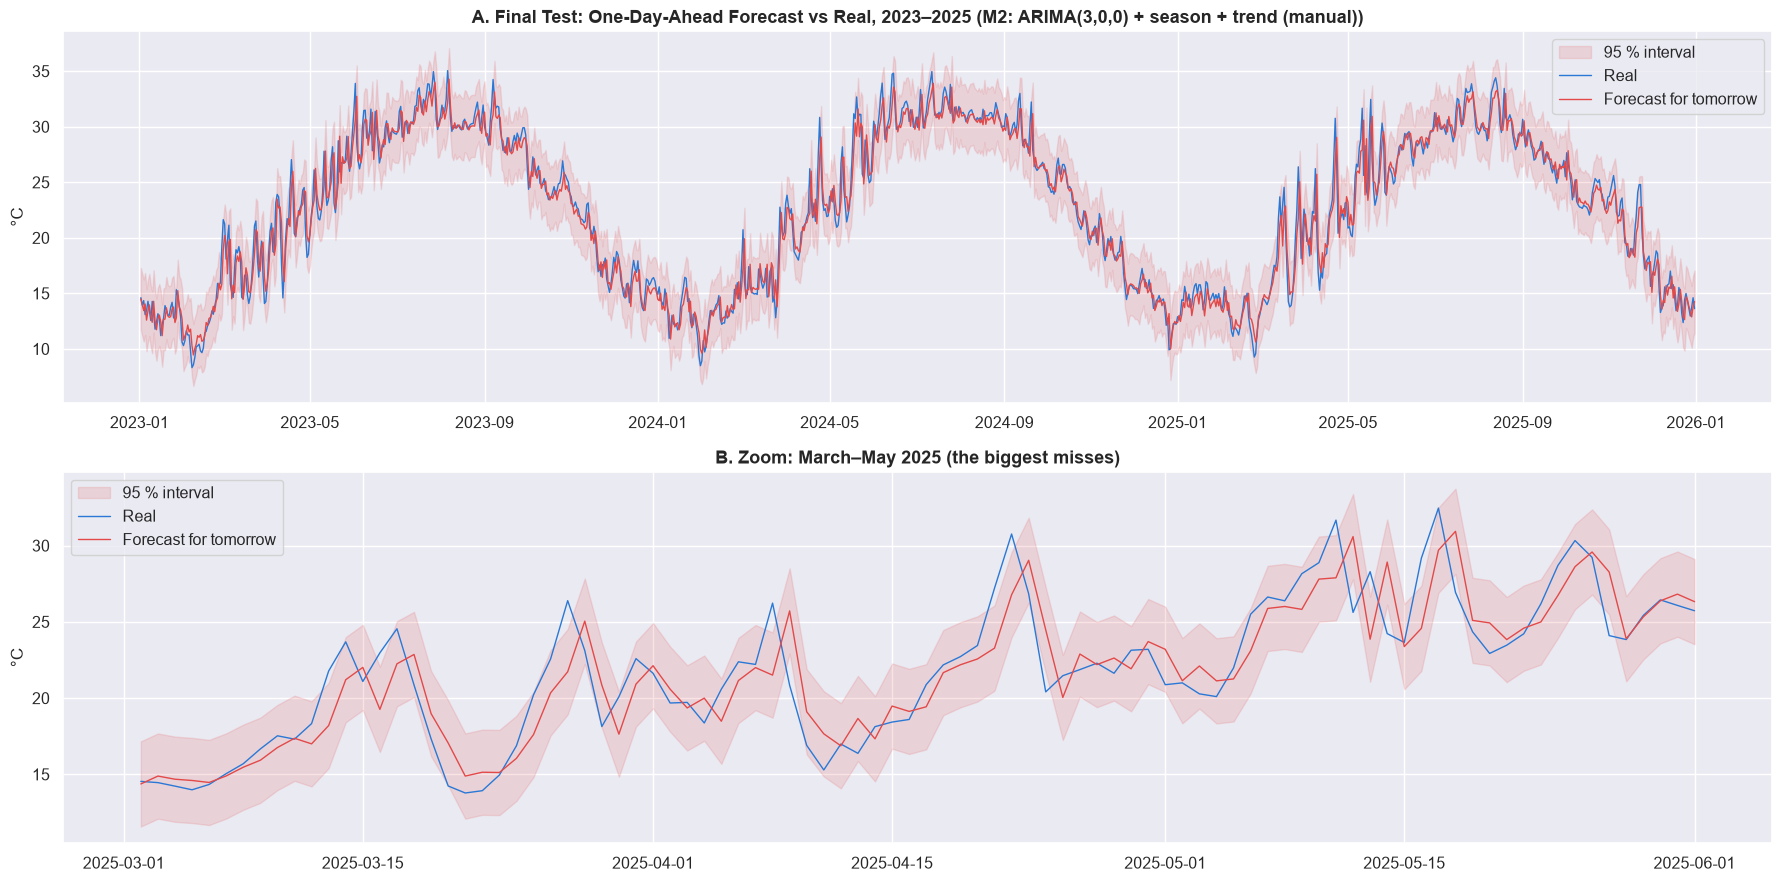

In [117]:
# the Task 5 forecast plot: forecast vs real on the test years, with the 95 % interval
test_forecast = test_forecasts[chosen]
actual_test = temp_test["temp_tomorrow"]

fig, ax = plt.subplots(nrows=2, figsize=(18, 9))
periods = [slice("2023-01-01", "2025-12-31"), slice("2025-03-01", "2025-05-31")]
for i, period in enumerate(periods):
    part = test_forecast.loc[period]
    days = part.index + pd.Timedelta(days=1)
    ax[i].fill_between(days, part["lower"], part["upper"], color="#e34948", alpha=0.15, label="95 % interval")
    ax[i].plot(days, actual_test.loc[period], color="#2a78d6", linewidth=1, label="Real")
    ax[i].plot(days, part["forecast"], color="#e34948", linewidth=1, label="Forecast for tomorrow")
    ax[i].set_ylabel("°C")
    ax[i].legend()
ax[0].set_title("A. Final Test: One-Day-Ahead Forecast vs Real, 2023–2025 (" + MODELS[chosen]["label"] + ")")
ax[1].set_title("B. Zoom: March–May 2025 (the biggest misses)")
plt.tight_layout()
plt.show()

In [118]:
by_day_test = pd.DataFrame({
    "real": actual_test.values,
    "forecast": test_forecast["forecast"].values,
    "persistence": temp_baselines.loc[temp_test.index, "Persistence (today)"].values,
    "inside": ((actual_test >= test_forecast["lower"]) & (actual_test <= test_forecast["upper"])).values,
}, index=temp_test.index + pd.Timedelta(days=1))

error = by_day_test["real"] - by_day_test["forecast"]
persistence_error = by_day_test["real"] - by_day_test["persistence"]

def error_summary(groups):
    # the same five numbers for any grouping of the test days
    return pd.DataFrame({
        "Days": by_day_test["real"].groupby(groups).size(),
        "MAE model (°C)": error.abs().groupby(groups).mean(),
        "MAE persistence (°C)": persistence_error.abs().groupby(groups).mean(),
        "Bias: real − forecast (°C)": error.groupby(groups).mean(),
        "Inside 95 % interval (%)": 100 * by_day_test["inside"].groupby(groups).mean(),
    })

test_by_year = error_summary(by_day_test.index.year)
test_by_year.index.name = "Year"
test_by_month = error_summary(by_day_test.index.month)
test_by_month.index.name = "Month"

# very hot and very cold days: the 5 % hottest and coldest days of the training years
HOT = temp_train["temp_mean"].quantile(0.95)
COLD = temp_train["temp_mean"].quantile(0.05)
day_type = pd.Series("Normal days", index=by_day_test.index)
day_type[by_day_test["real"] > HOT] = "Very hot days (above " + str(round(HOT, 1)) + " °C)"
day_type[by_day_test["real"] < COLD] = "Very cold days (below " + str(round(COLD, 1)) + " °C)"
test_by_day_type = error_summary(day_type)

print("Overall inside the interval:", round(100 * by_day_test["inside"].mean(), 1), "%")
print("Overall bias (real − forecast):", round(error.mean(), 3), "°C")
test_by_year.round(3)

Overall inside the interval: 95.1 %
Overall bias (real − forecast): 0.129 °C


,Days,MAE model (°C),MAE persistence (°C),Bias: real − forecast (°C),Inside 95 % interval (%)
Year,,,,,
2023,364,0.955,1.080,0.151,94.231
2024,366,0.886,0.974,0.128,95.628
2025,365,0.977,1.061,0.108,95.342


In [119]:
test_by_day_type.round(2)

,Days,MAE model (°C),MAE persistence (°C),Bias: real − forecast (°C),Inside 95 % interval (%)
Normal days,938,0.91,1.04,0.06,94.99
Very cold days (below 11.1 °C),26,1.22,0.92,-1.16,96.15
Very hot days (above 30.9 °C),131,1.13,1.04,0.88,95.42


In [120]:
test_by_month.round(2)

,Days,MAE model (°C),MAE persistence (°C),Bias: real − forecast (°C),Inside 95 % interval (%)
Month,,,,,
1,92,0.80,0.83,0.25,100.00
2,85,0.77,0.75,-0.22,98.82
3,93,1.43,1.64,0.12,84.95
4,90,1.41,1.69,0.01,84.44
5,93,1.56,1.81,0.05,81.72
6,90,0.92,1.03,0.16,96.67
7,93,0.80,0.89,0.29,100.00
8,93,0.59,0.63,0.24,98.92
9,90,0.74,0.80,0.18,97.78


In [121]:
# every test forecast, saved for the README and the storm story (Step 9)
saved = pd.DataFrame({"real_tomorrow": actual_test})
for name in MODELS:
    saved[name + "_forecast"] = test_forecasts[name]["forecast"]
saved[chosen + "_lower_95"] = test_forecast["lower"]
saved[chosen + "_upper_95"] = test_forecast["upper"]
saved["persistence"] = temp_baselines.loc[temp_test.index, "Persistence (today)"]
saved.index.name = "today"
saved.to_csv("forecasts_test.csv")
saved.shape

(1095, 8)

**What we see:**
- **Final score:** M2 forecasts tomorrow's mean temperature with **MAE 0.940 °C** on 2023–2025, against 1.038 °C for "tomorrow = today": **9.5 % lower**. RMSE 1.286 vs 1.443 °C, MAPE 4.5 % vs 5.0 %, R² 0.965. This matches the walk-forward (8.8 % on 13 years).
- **Other models:** M3 and M4 0.937, M1 (no season) 0.984: the same order and the same tiny gaps as on validation, so the choice would not have changed.
- **Every year:** M2 beats persistence in 2023 (0.955 vs 1.080), 2024 (0.886 vs 0.974) and 2025 (0.977 vs 1.061).
- **By month:** it beats persistence in 11 of 12 months (not February: 0.77 vs 0.75 °C). The biggest errors are again March–May (1.41–1.56 °C); the biggest single misses are in spring 2025 (for example, 12 May 2025: forecast 5.0 °C too warm).
- **Interval:** 95.1 % of real values fall inside it overall, but only 82–85 % in March–May, and 99–100 % in most other months.
- **Cold bias (H1):** small overall: +0.13 °C (the forecast is a little too cold), in every year (+0.11 to +0.15 °C), more in summer (July +0.29 °C). But on **very hot days** (above 30.9 °C, the hottest 5 % of training days) the model is **0.88 °C too cold** and worse than persistence (MAE 1.13 vs 1.04 °C). On very cold days (below 11.1 °C) it is 1.16 °C too warm, also worse than persistence (1.22 vs 0.92 °C). These days are chosen by what happened; Step 12 (Q4) shows that most of this gap comes from that choice.
- **The test years are hot:** 131 of 1,095 test days (12 %) are very hot days, against 5 % in the training years.

**Why:** The model pulls the forecast back toward the normal for the date. On most days this is right, and it is why the model beats persistence. The small overall bias (+0.13 °C) is the warming of 2023–2025 running ahead of the trend learned on 1990–2022 (H1). The larger bias on the hottest days needs care: those days are chosen *because* they turned out hotter than expected, so any forecast looks too cold on them. Step 12 (Q4) checks this on days chosen in advance.

**What we do with it:**
- **Final answer for temperature:** M2 forecasts tomorrow's mean temperature in Cairo with a typical error of 0.94 °C on unseen years, about 10 % better than "tomorrow = today", and better in every test year.
- **Limits to report:** the 95 % interval is too narrow in spring, and the forecast misses sudden jumps. It looks about 0.9 °C too cold on the days that turned out hottest, mostly because of how those days are chosen (Step 12, Q4).
- **Next steps:** an input that tells the model a warm spell is already running is tested in Step 12 (it changes nothing); an interval whose width changes with the season is still open.
- All test forecasts are saved in `forecasts_test.csv`.

## Step 9: The Storm Story: How the Forecasts Do on Task 4's Storms (H5)

**What we do:** Use exactly the Task 4 definitions (3.4.4), with nothing new:
- the **storm score**: the average rank of the pressure drop, wind, max-temperature drop and humidity;
- the **events** (first day of each): **storms** (rain ≥ 10 mm, 2016–2025), **heat waves** (max temperature ≥ 2 std above normal), **cold snaps** (min temperature ≥ 2 std below normal).

Then measure the chosen model M2 on these days. It forecasts one day ahead: 2020–2022 from Step 6 and 2023–2025 from Step 8.
1. The error on the day before, the event day and the day after, against persistence.
2. The March 2020 storm, day by day.
3. The error on calm days vs stormy days (storm score in 10 groups).
4. The rain side: how many storms "rain today → rain tomorrow" warned about.
5. A storm warning (9.5): which signs, together, raise the chance of a storm tomorrow, and can a model combine them?
6. Rain tomorrow (9.6): Task 4's second goal, a model against persistence.

**Why:** Task 4 ended H5 with: *storms give almost no warning in the days before them; heat waves and cold snaps build up over days.* A forecast model is the real test of this. If the signs are not there, the model must miss the storm days. The overall MAE (0.94 °C) hides these days because they are few.

Task 4's normals use all 36 years. Here they only **label** which days are events; they are never a model input, so no future value enters a forecast.

**What we do with it:** The answer closes H5 and goes into the conclusion (Step 11).

In [122]:
# the same definitions as Task 4 (3.4.4), so the storms here are exactly the storms found there
SIGNS = ["pressure", "humidity", "temp_max", "temp_min", "wind_speed", "precipitation"]

# how unusual each day is for its date: 0 = normal, +2 = much higher than normal, -2 = much lower
z_normal = weather[SIGNS].groupby(weather.index.dayofyear).transform("mean")
z_spread = weather[SIGNS].groupby(weather.index.dayofyear).transform("std")
z = (weather[SIGNS] - z_normal) / z_spread

# storm score: the average rank of four signs that stay consistent over all 36 years
signs = pd.DataFrame({
    "pressure_drop": -weather["pressure"].diff(),
    "wind_speed": weather["wind_speed"],
    "temp_drop": -weather["temp_max"].diff(),
    "humidity": weather["humidity"],
})
storm_score = signs.rank(pct=True).mean(axis=1)

def first_days(is_event):
    # keep only the first day of each event
    return is_event[is_event & ~is_event.shift(1, fill_value=False)].index

EVENTS = {
    "Storms (rain ≥ 10 mm, 2016–2025)": first_days((weather["precipitation"] >= 10) & (weather.index.year >= 2016)),
    "Heat waves (max temp ≥ 2 std above normal)": first_days(z["temp_max"] >= 2),
    "Cold snaps (min temp ≥ 2 std below normal)": first_days(z["temp_min"] <= -2),
}
for name, days in EVENTS.items():
    print(name, "->", len(days), "events in 1990–2025 |", (days.year >= 2020).sum(), "in 2020–2025")

Storms (rain ≥ 10 mm, 2016–2025) -> 25 events in 1990–2025 | 13 in 2020–2025
Heat waves (max temp ≥ 2 std above normal) -> 262 events in 1990–2025 | 52 in 2020–2025
Cold snaps (min temp ≥ 2 std below normal) -> 114 events in 1990–2025 | 6 in 2020–2025


**What we see:** 25 storms, 262 heat waves and 114 cold snaps: the same counts as in Task 4, so these are the same events. 13 storms, 52 heat waves and 6 cold snaps fall in 2020–2025, the years with real out-of-sample forecasts.

In [123]:
# M2's one-day-ahead forecasts for 2020-2025, placed on the day they forecast
# (2020-2022: fitted on 1990-2019, Step 6; 2023-2025: refitted on 1990-2022, Step 8)
m2_path = pd.concat([valid_forecasts["M2"], test_forecasts["M2"]])
m2_path.index = m2_path.index + pd.Timedelta(days=1)

story = pd.DataFrame({
    "real": weather.loc[m2_path.index, "temp_mean"],
    "forecast": m2_path["forecast"],
    "lower": m2_path["lower"],
    "upper": m2_path["upper"],
    "persistence": weather["temp_mean"].shift(1).loc[m2_path.index],
    "storm_score": storm_score.loc[m2_path.index],
})
story["model_error"] = story["real"] - story["forecast"]
story["persistence_error"] = story["real"] - story["persistence"]
story["inside"] = (story["real"] >= story["lower"]) & (story["real"] <= story["upper"])

def event_row(days):
    # the same five numbers for any list of days
    part = story.loc[story.index.intersection(days)]
    return {
        "Days": len(part),
        "MAE model (°C)": part["model_error"].abs().mean(),
        "MAE persistence (°C)": part["persistence_error"].abs().mean(),
        "Bias: real − forecast (°C)": part["model_error"].mean(),
        "Inside 95 % interval (%)": 100 * part["inside"].mean(),
    }

rows = {}
all_event_days = pd.DatetimeIndex([])
for name, days in EVENTS.items():
    for shift, when in [(-1, "day before"), (0, "event day"), (1, "day after")]:
        rows[(name, when)] = event_row(days + pd.Timedelta(days=shift))
    all_event_days = all_event_days.union(days)
rows[("Every other day", "")] = event_row(story.index.difference(all_event_days))

event_table = pd.DataFrame(rows).T
event_table.index.names = ["Event (Task 4, 3.4.4)", "Day"]
event_table.round(2)

Days  MAE model (°C)  \
Event (Task 4, 3.4.4)                      Day                                  
Storms (rain ≥ 10 mm, 2016–2025)           day before    13.0            1.00   
                                           event day     13.0            1.65   
                                           day after     13.0            0.81   
Heat waves (max temp ≥ 2 std above normal) day before    52.0            1.30   
                                           event day     52.0            2.06   
                                           day after     52.0            1.62   
Cold snaps (min temp ≥ 2 std below normal) day before     6.0            1.88   
                                           event day      6.0            1.72   
                                           day after      6.0            1.12   
Every other day                                        2120.0            0.93   

                                                       MAE persistence (°C)  \
Event (Task 4, 3.4.4)                      Day                                
Storms (rain ≥ 10 mm, 2016–2025)           day before                  0.76   
                                           event day                   1.30   
                                           day after                   0.57   
Heat waves (max temp ≥ 2 std above normal) day before                  1.12   
                                           event day                   1.62   
                                           day after                   1.72   
Cold snaps (min temp ≥ 2 std below normal) day before                  0.93   
                                           event day                   0.63   
                                           day after                   1.10   
Every other day                                                        1.04   

                                                       Bias: real − forecast (°C)  \
Event (Task 4, 3.4.4)                      Day                                      
Storms (rain ≥ 10 mm, 2016–2025)           day before                       -0.24   
                                           event day                        -1.05   
                                           day after                        -0.07   
Heat waves (max temp ≥ 2 std above normal) day before                        1.25   
                                           event day                         2.05   
                                           day after                         0.07   
Cold snaps (min temp ≥ 2 std below normal) day before                       -1.88   
                                           event day                        -1.72   
                                           day after                        -0.98   
Every other day                                                             -0.00   

                                                       Inside 95 % interval (%)  
Event (Task 4, 3.4.4)                      Day                                   
Storms (rain ≥ 10 mm, 2016–2025)           day before                     92.31  
                                           event day                      84.62  
                                           day after                     100.00  
Heat waves (max temp ≥ 2 std above normal) day before                     96.15  
                                           event day                      80.77  
                                           day after                      82.69  
Cold snaps (min temp ≥ 2 std below normal) day before                     83.33  
                                           event day                     100.00  
                                           day after                     100.00  
Every other day                                                           95.09

**What we see:**
- **Every other day (2,120 days):** model MAE 0.93 °C vs 1.04 °C for persistence, no bias, and 95.1 % inside the 95 % interval. This is where the 10 % gain comes from.
- **Storms (13):** on the storm day the error jumps to **1.65 °C**, and the model is **worse than persistence** (1.30 °C). The forecast is **1.05 °C too warm**, and only 85 % of storm days fall inside the interval. The day before (1.00 °C) and the day after (0.81 °C) are back to normal.
- **Heat waves (52):** the worst case. On the first day the error is **2.06 °C**, the forecast is **2.05 °C too cold**, and only 81 % of days fall inside the interval. Already on the day before, the model is 1.25 °C too cold and worse than persistence (1.30 vs 1.12 °C). On the day after, it is slightly better than persistence (1.62 vs 1.72 °C).
- **Cold snaps (6):** too few to judge. The model is too warm by 1.7–1.9 °C and worse than persistence on the day before and on the event day.

**Why:** The model's strength is that it pulls tomorrow back toward the normal for the date. On event days this is the wrong move:
- **Storms** cool Cairo suddenly, and the days before show no clear sign (Task 4, H5). The model forecasts an ordinary day, so it is too warm.
- **Heat waves** are defined by a temperature that turned out far above normal, so on their first day every forecast that leans toward normal looks too cold, and persistence, which repeats yesterday's warmth, looks better. Much of this gap comes from how the days are chosen, not from the model: on hot days chosen *in advance*, the model is only 0.1–0.2 °C too cold (Step 12, Q4).

**What we do with it:** The temperature models do not see storms coming: the storm error appears on the storm day only, not before. Whether the signs themselves can warn of a storm is tested in 9.5. For heat, the fair question is a warning asked in advance; Step 12 asks it (Q3).

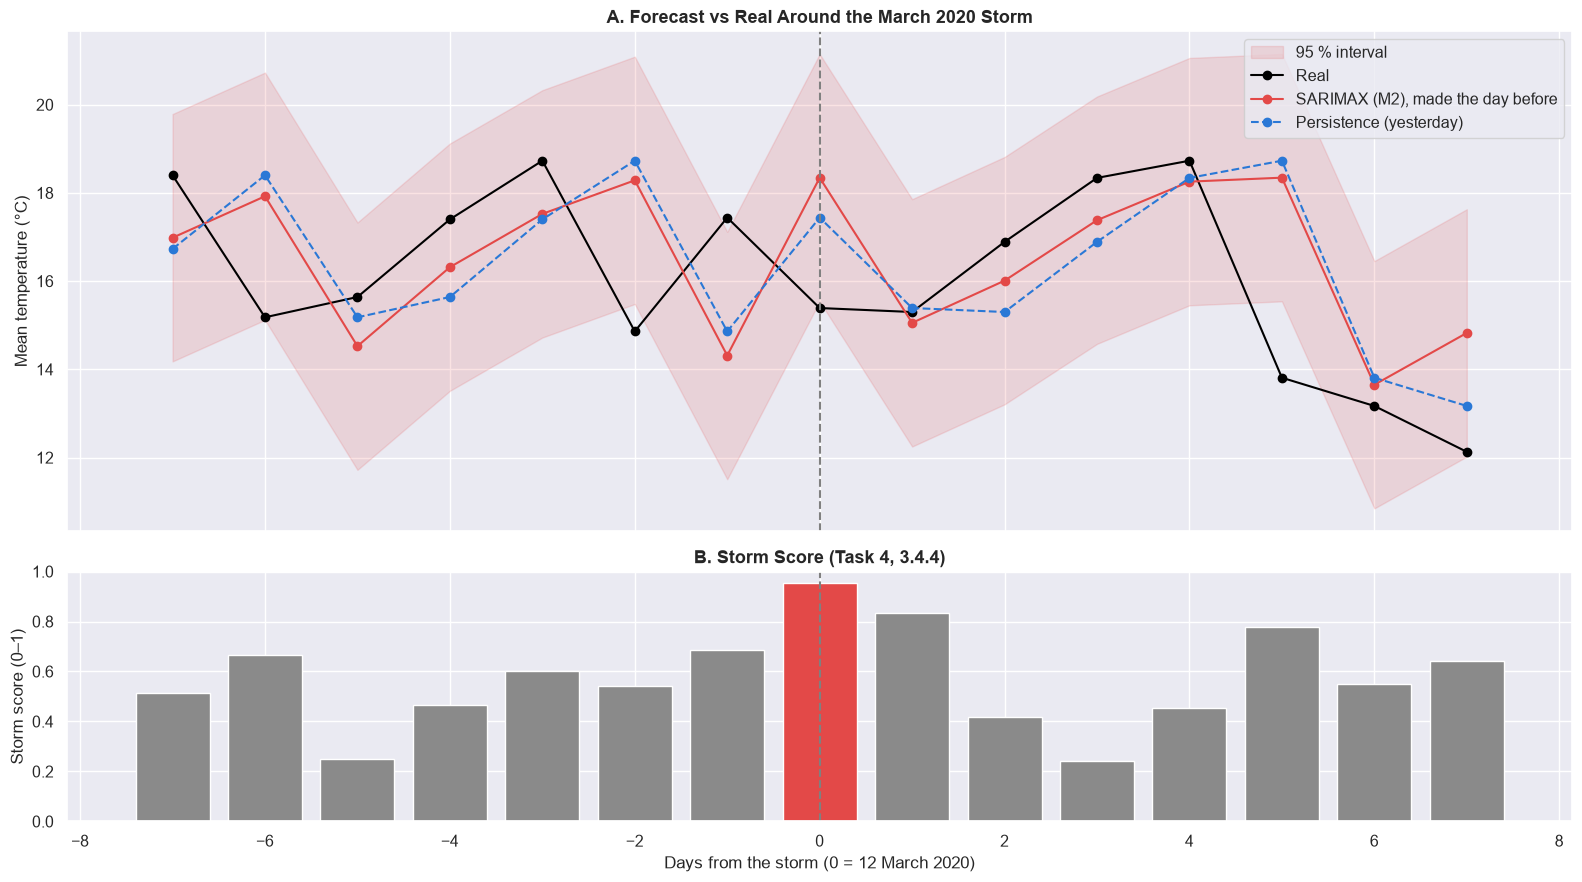

,real,forecast,lower,upper,persistence,model_error,storm_score
date,,,,,,,
2020-03-10,14.86,18.29,15.48,21.09,18.73,-3.43,0.54
2020-03-11,17.44,14.31,11.51,17.12,14.86,3.13,0.69
2020-03-12,15.39,18.34,15.54,21.15,17.44,-2.95,0.95
2020-03-13,15.30,15.05,12.25,17.86,15.39,0.25,0.83
2020-03-14,16.89,16.01,13.21,18.81,15.30,0.88,0.42
2020-03-15,18.34,17.38,14.58,20.18,16.89,0.96,0.24


In [124]:
# the March 2020 storm (Task 4: the lowest pressure in 36 years), day by day
storm_day = pd.Timestamp("2020-03-12")
window = story.loc[storm_day - pd.Timedelta(days=7): storm_day + pd.Timedelta(days=7)]
days_from_storm = (window.index - storm_day).days

fig, ax = plt.subplots(nrows=2, figsize=(16, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].fill_between(days_from_storm, window["lower"], window["upper"], color="#e34948", alpha=0.15, label="95 % interval")
ax[0].plot(days_from_storm, window["real"], marker="o", color="black", label="Real")
ax[0].plot(days_from_storm, window["forecast"], marker="o", color="#e34948", label="SARIMAX (M2), made the day before")
ax[0].plot(days_from_storm, window["persistence"], marker="o", color="#2a78d6", linestyle="--", label="Persistence (yesterday)")
ax[0].set_ylabel("Mean temperature (°C)")
ax[0].set_title("A. Forecast vs Real Around the March 2020 Storm")
ax[0].legend()
ax[1].bar(days_from_storm, window["storm_score"], color=["#e34948" if d == 0 else "#8a8a8a" for d in days_from_storm])
ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Storm score (0–1)")
ax[1].set_title("B. Storm Score (Task 4, 3.4.4)")
for a in ax:
    a.axvline(0, color="gray", linestyle="--")
ax[1].set_xlabel("Days from the storm (0 = 12 March 2020)")
plt.tight_layout()
plt.show()

window[["real", "forecast", "lower", "upper", "persistence", "model_error", "storm_score"]].round(2).loc["2020-03-10":"2020-03-15"]

**What we see:** For 12 March 2020 (storm score 0.95), the forecast was 18.3 °C and the real value 15.4 °C: **2.95 °C too warm**, just outside the 95 % interval (15.5–21.2 °C). Persistence missed by less (2.05 °C). The two days before were also missed: 11 March was warmer than forecast (17.4 vs 14.3 °C), which is the warm day before the storm that Task 4 described. On 13 March the error is back to 0.25 °C.

**Why:** The model saw the warm-up of 11 March and expected it to continue. The storm reversed it in one day, with nothing in the earlier days to announce it. Once the cold day is "today", the model has it and is right again the next day.

**What we do with it:** This one storm matches the table above: one day of surprise, then a quick recovery. It is the clearest case of the "no warning" answer to H5.

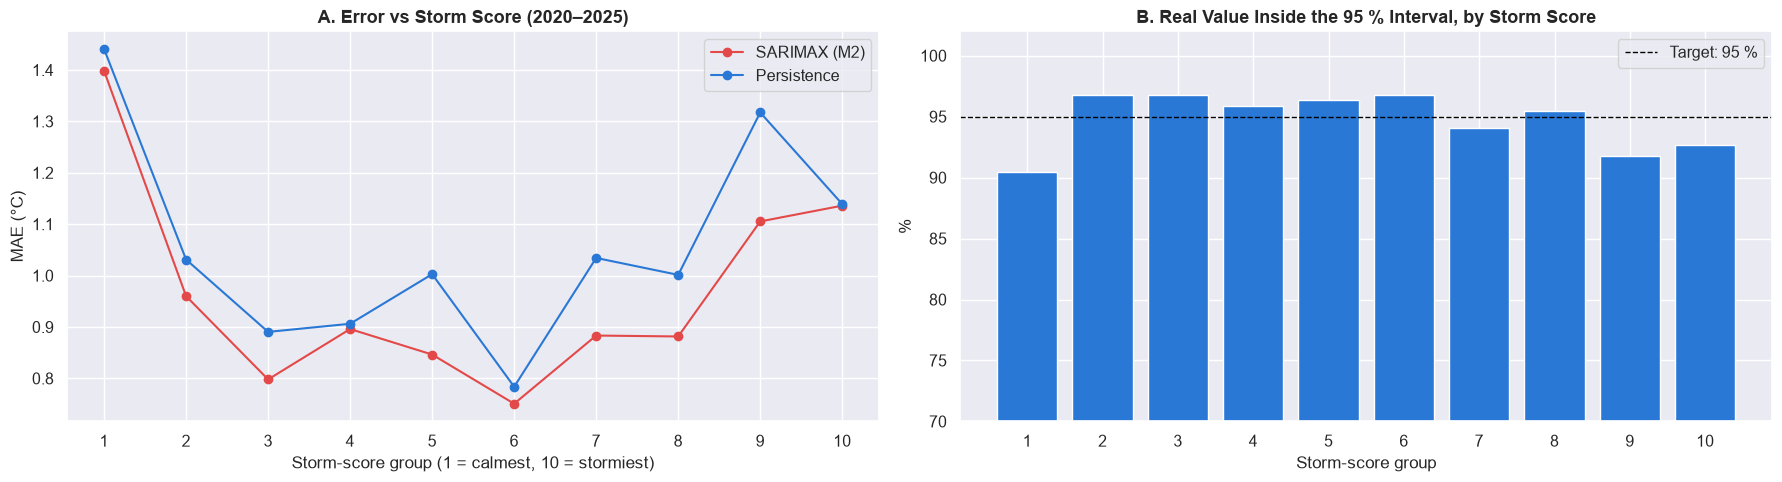

,Storm score from,MAE model (°C),MAE persistence (°C),Inside 95 % interval (%)
"Group (1 = calmest 10 %, 10 = stormiest 10 %)",,,,
1,0.09,1.40,1.44,90.45
2,0.33,0.96,1.03,96.80
3,0.39,0.80,0.89,96.80
4,0.44,0.90,0.91,95.89
5,0.47,0.85,1.00,96.35
6,0.51,0.75,0.78,96.80
7,0.55,0.88,1.03,94.06
8,0.58,0.88,1.00,95.43
9,0.62,1.11,1.32,91.78


In [125]:
# does the error grow with the storm score? Days of 2020-2025 in 10 equal groups, from calm to stormy
story["score_group"] = pd.qcut(story["storm_score"], 10, labels=range(1, 11))
by_score = pd.DataFrame({
    "Storm score from": story.groupby("score_group", observed=True)["storm_score"].min(),
    "MAE model (°C)": story["model_error"].abs().groupby(story["score_group"], observed=True).mean(),
    "MAE persistence (°C)": story["persistence_error"].abs().groupby(story["score_group"], observed=True).mean(),
    "Inside 95 % interval (%)": 100 * story["inside"].groupby(story["score_group"], observed=True).mean(),
})
by_score.index.name = "Group (1 = calmest 10 %, 10 = stormiest 10 %)"

fig, ax = plt.subplots(ncols=2, figsize=(18, 5))
ax[0].plot(by_score.index.astype(int), by_score["MAE model (°C)"], marker="o", color="#e34948", label="SARIMAX (M2)")
ax[0].plot(by_score.index.astype(int), by_score["MAE persistence (°C)"], marker="o", color="#2a78d6", label="Persistence")
ax[0].set_title("A. Error vs Storm Score (2020–2025)")
ax[0].set_xlabel("Storm-score group (1 = calmest, 10 = stormiest)")
ax[0].set_ylabel("MAE (°C)")
ax[0].set_xticks(range(1, 11))
ax[0].legend()
ax[1].bar(by_score.index.astype(int), by_score["Inside 95 % interval (%)"], color="#2a78d6")
ax[1].axhline(95, color="black", linestyle="--", linewidth=1, label="Target: 95 %")
ax[1].set_ylim(70, 102)
ax[1].set_title("B. Real Value Inside the 95 % Interval, by Storm Score")
ax[1].set_xlabel("Storm-score group")
ax[1].set_ylabel("%")
ax[1].set_xticks(range(1, 11))
ax[1].legend()
plt.tight_layout()
plt.show()

by_score.round(2)

**What we see:** The error is **U-shaped**. It is lowest in the middle groups (0.75–0.90 °C) and higher at both ends: the stormiest 10 % (1.14 °C) and, even more, the calmest 10 % (1.40 °C). In the stormiest group the model loses its advantage over persistence (1.14 vs 1.14 °C). At both ends only 90–93 % of real values fall inside the 95 % interval.

**Why:** A low storm score is the opposite of a storm: pressure rises, max temperature jumps up, and the air is dry and calm. That is the sudden warm, dry pattern of heat waves. It looks like Task 4's Khamasin-like days (H6), but Task 4's definition needs a south wind, and wind direction is missing after 2012, so these days cannot be checked as Khamasin. Both ends of the score are sudden changes, in opposite directions, and the model misses sudden changes, not only storms. The score is measured on the day being forecast, so it explains the error after the fact; it is not a warning.

**What we do with it:** The Task 4 storm score also works as a "how unusual was this day" label. On days at either end, the forecast and its interval are least reliable; an interval that widens on such days is a next step.

In [126]:
# the rain side of H5: how many of Task 4's storms did "rain today -> rain tomorrow" warn about?
storm_days = EVENTS["Storms (rain ≥ 10 mm, 2016–2025)"]
rain_day_before = weather["precipitation"].shift(1).loc[storm_days] >= 1
storm_warning = pd.DataFrame({
    "Storms": len(storm_days),
    "Warned (rain ≥ 1 mm the day before)": rain_day_before.sum(),
    "Missed (dry the day before)": (~rain_day_before).sum(),
}, index=["2016–2025"])
storm_warning["Warned (%)"] = (100 * storm_warning["Warned (rain ≥ 1 mm the day before)"] / storm_warning["Storms"]).round(1)
storm_warning

,Storms,Warned (rain ≥ 1 mm the day before),Missed (dry the day before),Warned (%)
2016–2025,25,13,12,52.0


**What we see:** Of the 25 storms (rain ≥ 10 mm, 2016–2025), **13 (52 %)** came after a day with rain ≥ 1 mm, so "rain today → rain tomorrow" warned of them. The other **12** came after a dry day.

**Why:** Task 4 found that light rain often falls in the 2 days before a storm, and that rain comes in groups. That is the only warning daily data gives. The other half of the storms start on a dry day, with no sign in pressure, wind or humidity (Task 4, H5: all links below 0.06).

**What we do with it:** For rain, persistence is the realistic warning: it catches about half of the storms. The other half cannot be seen one day ahead in daily data. This is the limit any rain model built on this data will face.

### 9.5 Storm Warning: How the Signs Work Together

**What we do:** Go back to the question behind H5 in Task 4: *can the signs warn us before a storm?* Task 4 measured each sign **alone** (all correlations below 0.06). Here we look at them **together**:
1. The chance of a storm tomorrow for each combination of signs today (2016–2025, the years with consistent rain data).
2. A logistic regression that combines all the signs, trained on 2016–2020 and tested on 2023–2025, against "rain today → storm tomorrow".
3. What the model learned: how much each sign changes the odds.

A storm is Task 4's definition: the first day of rain ≥ 10 mm. A day that is already part of a storm is not used as "today".

**Why:** A weak correlation for each sign alone does not mean there is no warning: two weak signs can be strong together. This is the direct test of the Task 4 question.

**What we do with it:** The answer refines H5 in the comparison (Step 11).

In [127]:
# Task 4's storms, one day ahead: how the signs work together (2016-2025, the years with consistent rain data)
heavy_day = (weather["precipitation"] >= 10) & (weather.index.year >= 2016)
storm_tomorrow = pd.Series(0, index=weather.index)
storm_tomorrow.loc[EVENTS["Storms (rain ≥ 10 mm, 2016–2025)"] - pd.Timedelta(days=1)] = 1

signs_today = pd.DataFrame({
    "rainy_season": weather.index.month.isin([10, 11, 12, 1, 2, 3, 4]),
    "rain_today": weather["precipitation"] >= 1,
    "humid": z["humidity"] > 1,  # more than 1 std above normal for the date (Task 4's scale)
    "pressure_falling": weather["pressure"].diff() < 0,
    "storm_tomorrow": storm_tomorrow,
}, index=weather.index).loc["2016-01-01":"2025-12-30"]
# a day that is already part of a storm cannot be the day before a new one
signs_today = signs_today[~heavy_day.loc[signs_today.index]]

season = signs_today["rainy_season"]
rain_today = signs_today["rain_today"]
humid = signs_today["humid"]
pressure_falling = signs_today["pressure_falling"]
conditions = {
    "Any day": season | ~season,
    "Rainy season (Oct–Apr)": season,
    "Rainy season + rain today": season & rain_today,
    "+ rain today + humid": season & rain_today & humid,
    "+ rain today + pressure falling": season & rain_today & pressure_falling,
    "+ rain today + humid + pressure falling": season & rain_today & humid & pressure_falling,
    "Rainy season, dry today": season & ~rain_today,
    "Dry today + humid + pressure falling": season & ~rain_today & humid & pressure_falling,
}

base_chance = signs_today["storm_tomorrow"].mean()
rows = []
for name, mask in conditions.items():
    part = signs_today.loc[mask, "storm_tomorrow"]
    rows.append({
        "Signs today": name,
        "Days": len(part),
        "Storms tomorrow": part.sum(),
        "Chance (%)": 100 * part.mean(),
        "Times the usual chance": part.mean() / base_chance,
    })
storm_conditions = pd.DataFrame(rows).set_index("Signs today")
storm_conditions.round(1)

,Days,Storms tomorrow,Chance (%),Times the usual chance
Signs today,,,,
Any day,3614,25,0.7,1.0
Rainy season (Oct–Apr),2084,25,1.2,1.7
Rainy season + rain today,121,13,10.7,15.5
+ rain today + humid,64,5,7.8,11.3
+ rain today + pressure falling,49,10,20.4,29.5
+ rain today + humid + pressure falling,28,4,14.3,20.7
"Rainy season, dry today",1963,12,0.6,0.9
Dry today + humid + pressure falling,134,0,0.0,0.0


**What we see:**
- On an ordinary day, the chance of a storm tomorrow is 0.7 %; in the rainy season, 1.2 %.
- **Rain today** raises it to 10.7 % (15 times the usual chance): 13 of the 25 storms came the day after rain.
- **Rain today + falling pressure** raises it to **20.4 % (about 30 times)**: about 1 day in 5 with these two signs is followed by a storm. 10 of the 13 storms that came after rain also had falling pressure the day before.
- **Humidity adds nothing once it rains:** rain + humid gives 7.8 %, less than rain alone.
- **A dry day gives no warning:** 12 storms started after a dry day (0.6 %, the usual chance). Even a dry day that is humid with falling pressure: 0 storms in 134 days.

**Why:** There are two kinds of storms. Some weather systems arrive slowly: light rain first and falling pressure, then the heavy rain (the March 2020 pattern in Task 4). Others reach Cairo within a day, with nothing in the daily averages before them. On a rainy day the air is already humid, so humidity adds no new information.

**What we do with it:** A simple, readable warning rule exists: *rain today and falling pressure → about a 1 in 5 chance of a storm tomorrow*. It covers 10 of the 25 storms. The storms that start on a dry day cannot be seen one day ahead in this data.

In [128]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# can a model combine the signs better? Inputs known today; normals from the training years only
warning_inputs = pd.DataFrame({
    "rainy_season": weather.index.month.isin([10, 11, 12, 1, 2, 3, 4]).astype(int),
    "rain_today": (weather["precipitation"] >= 1).astype(int),
    "humidity_vs_normal": anomaly("humidity"),
    "pressure_vs_normal": anomaly("pressure"),
    "temp_max_vs_normal": anomaly("temp_max"),
    "wind_vs_normal": anomaly("wind_speed"),
    "pressure_change_3d": weather["pressure"].diff(3),
    "humidity_change_3d": weather["humidity"].diff(3),
    "temp_max_change_3d": weather["temp_max"].diff(3),
}, index=weather.index)

usable = ~heavy_day & warning_inputs.notna().all(axis=1) & (weather.index <= "2025-12-30")
learn = usable & (weather.index.year >= 2016) & (weather.index.year <= 2020)
test = usable & (weather.index.year >= 2023)
print("Storms to learn from (2016–2020):", storm_tomorrow[learn].sum(), "| storms in the test years (2023–2025):", storm_tomorrow[test].sum())

# logistic regression; "balanced" because storms are rare
warning_scaler = StandardScaler().fit(warning_inputs[learn])
warning_model = LogisticRegression(class_weight="balanced", C=0.3, max_iter=2000)
warning_model.fit(warning_scaler.transform(warning_inputs[learn]), storm_tomorrow[learn])
risk = pd.Series(warning_model.predict_proba(warning_scaler.transform(warning_inputs[test]))[:, 1], index=weather.index[test])

# warn on the riskiest 1 % of test days (about 11 days in 3 years), and compare with "rain today -> storm tomorrow"
warnings_compared = {
    "Model: riskiest 1 % of days": (risk >= risk.quantile(0.99)).astype(int),
    "Persistence: rain today": warning_inputs.loc[test, "rain_today"],
}
rows = []
for name, warning in warnings_compared.items():
    scores = classification_scores(storm_tomorrow[test], warning)
    scores["Warning"] = name
    rows.append(scores)
pd.DataFrame(rows).set_index("Warning")[["Hits", "Misses", "False alarms", "Precision", "Recall", "CSI"]].round(2)

Storms to learn from (2016–2020): 15 | storms in the test years (2023–2025): 6


,Hits,Misses,False alarms,Precision,Recall,CSI
Warning,,,,,,
Model: riskiest 1 % of days,2,4,9,0.18,0.33,0.13
Persistence: rain today,4,2,29,0.12,0.67,0.11


In [129]:
# what the model learned: how much each sign changes the odds of a storm tomorrow (per 1 std, the others held fixed)
pd.DataFrame({
    "Coefficient": warning_model.coef_[0],
    "Odds × per 1 std": np.exp(warning_model.coef_[0]),
}, index=warning_inputs.columns).sort_values("Coefficient", ascending=False).round(2)

,Coefficient,Odds × per 1 std
rainy_season,2.29,9.89
rain_today,0.53,1.70
humidity_vs_normal,0.33,1.39
temp_max_vs_normal,0.25,1.29
pressure_change_3d,0.17,1.18
humidity_change_3d,-0.09,0.92
temp_max_change_3d,-0.16,0.85
wind_vs_normal,-0.20,0.82
pressure_vs_normal,-0.57,0.57


**What we see:**
- With 15 storms to learn from, the model warns on the riskiest 1 % of test days (11 days) and catches **2 of 6** storms with 9 false alarms. "Rain today" catches **4 of 6**, with 29 false alarms. CSI 0.13 vs 0.11: the model is more precise but misses more; it is not clearly better.
- What it learned matches the table: the rainy season (×9.9), rain today (×1.7) and **low pressure** (×0.57 per std of *higher* pressure, so lower pressure raises the risk) matter most. A day warmer than normal (×1.3, the warm day before the storm in Task 4) and humidity (×1.4) add a little; wind adds nothing.

**Why:** 15 storms are too few for a model to learn more than a simple rule, and 6 test storms are too few to judge one: one storm more or less moves the recall by 17 points. The rain amounts after 2016 are also uncertain (Task 4, H3).

**What we do with it:** Keep the **rule** from the table (rain today + falling pressure), not the model. **Answer to H5, refined:** storms that start after rain give a one-day warning; storms that start on a dry day do not. A better storm warning needs more storms or finer data (hourly pressure, satellite images), not a more complex model.

### 9.6 Rain Tomorrow: Task 4's Second Goal

**What we do:** Task 4 set two goals: tomorrow's temperature, and rain tomorrow (≥ 1 mm, yes or no). Here the rain goal gets a model: a logistic regression on the signs from 9.5 plus the rain days in the last 3 days. It learns on 2016–2020, its threshold is chosen on 2021–2022 (best F1), and it is tested once on 2023–2025, against the number to beat from Task 4: persistence, "rain today → rain tomorrow" (F1 0.36 on validation, 0.47 on test).

**Why:** Rain days come in groups (39 % chance after a rain day, Task 4), and 9.5 showed that falling pressure adds to rain today. A model that combines the signs might catch more rain days than rain today alone.

**What we do with it:** The result closes Task 4's second goal in the conclusion.

In [130]:
# Task 4's second goal: rain tomorrow (≥ 1 mm), yes or no. The signs from 9.5, plus the rain days in the last 3 days
rain_inputs = warning_inputs.copy()
rain_inputs["rain_days_last_3"] = (weather["precipitation"] >= 1).astype(int).rolling(3).sum()

# learn on 2016-2020, choose the threshold on 2021-2022, test once on 2023-2025 (the Task 4 rain split)
rain_scaler = StandardScaler().fit(rain_inputs.loc[rain_train.index])
rain_model = LogisticRegression(class_weight="balanced", C=0.3, max_iter=2000)
rain_model.fit(rain_scaler.transform(rain_inputs.loc[rain_train.index]), rain_train["rain_tomorrow"])

def rain_chance(index):
    # the model's chance of rain tomorrow for each "today"
    return pd.Series(rain_model.predict_proba(rain_scaler.transform(rain_inputs.loc[index]))[:, 1], index=index)

# the threshold with the best F1 on validation; the test years are not used to choose it
valid_chance = rain_chance(rain_valid.index)
thresholds = np.arange(0.05, 0.96, 0.01)
rain_threshold = max(thresholds, key=lambda t: f1_score(rain_valid["rain_tomorrow"], (valid_chance >= t).astype(int)))
print("Threshold chosen on validation:", round(rain_threshold, 2))

rows = []
for split_name, part in [("Validation", rain_valid), ("Test", rain_test)]:
    forecasts = {
        "Model (logistic regression)": (rain_chance(part.index) >= rain_threshold).astype(int),
        "Baseline: Persistence (rain today)": rain_baselines.loc[part.index, "Persistence (rain today)"],
    }
    for name, forecast in forecasts.items():
        scores = classification_scores(part["rain_tomorrow"], forecast)
        scores["Split"] = split_name
        scores["Forecast"] = name
        rows.append(scores)

rain_model_results = pd.DataFrame(rows).set_index(["Split", "Forecast"])
rain_model_results[["Hits", "Misses", "False alarms", "Precision", "Recall", "F1", "CSI"]].round(2)

Threshold chosen on validation: 0.71


Hits  Misses  False alarms  \
Split      Forecast                                                         
Validation Model (logistic regression)           22      22            41   
           Baseline: Persistence (rain today)    16      28            28   
Test       Model (logistic regression)           21      22            36   
           Baseline: Persistence (rain today)    20      23            23   

                                               Precision  Recall    F1   CSI  
Split      Forecast                                                           
Validation Model (logistic regression)              0.35    0.50  0.41  0.26  
           Baseline: Persistence (rain today)       0.36    0.36  0.36  0.22  
Test       Model (logistic regression)              0.37    0.49  0.42  0.27  
           Baseline: Persistence (rain today)       0.47    0.47  0.47  0.30

**What we see:**
- **Validation (2021–2022):** the model catches 22 of 44 rain days (persistence: 16), with 41 false alarms (persistence: 28). F1 0.41 vs 0.36: better.
- **Test (2023–2025):** the model catches 21 of 43 rain days (persistence: 20), but with 36 false alarms (persistence: 23). F1 0.42 vs 0.47: **worse**.

**Why:** On the test years the model finds one more rain day than persistence and pays for it with 13 more false alarms. The test years were drier (3.9 % rain days, against 6.0 % in validation, Step 2.5), so a threshold chosen on wetter years raises too many alarms. With 89 rain days to learn from, there is little to learn beyond "rain today".

**What we do with it:** Task 4's second goal is answered, honestly: **persistence stays the best rain forecast** (F1 0.47 on test). A model helps in wet years and hurts in dry ones; it is not kept.

## Step 10 (Bonus): Simple RNN and LSTM

**What we do:** Train the two networks from Task 5 (6.2 and 6.3) on the same task, forecasting tomorrow's mean temperature from what is known today. Then compare them with SARIMAX on the same days.

| Setting | Value | Why |
|---|---|---|
| Library | PyTorch | Already installed; the same layers as the Keras code in Task 5 |
| Window | Last 30 days → tomorrow | Task 5 uses 48 hours for hourly data. For daily data, 30 days covers the 3–5-day memory and the weeks-long spells (Step 4) |
| Inputs per day | Temperature (scaled), day of year as sine and cosine | The same calendar information SARIMAX gets |
| Scaling | StandardScaler fitted on 1990–2019 only, refitted on 1990–2022 for the test | Rule 6; Task 5 2.6 |
| Simple RNN | SimpleRNN(32) → Dense(1) | Task 5, 6.2 |
| LSTM | LSTM(64) → Dropout(0.2) → LSTM(32) → Dense(1) | Task 5, 6.3 |
| Training | Adam, MSE, batch 32, up to 50 epochs, early stopping (patience 5), best weights kept | Task 5, 6.3 |
| Early-stopping set | 2017–2019 (the last 10 % of the training years) | Like `validation_split=0.1`, but by time, so 2020–2022 stays untouched for the comparison |
| Test | Refit on 1990–2022 for the number of epochs found, then forecast 2023–2025 | The same refit as SARIMAX in Step 8 |

**Why:** Task 5 asks to give the network "a fair shot": early stopping, a stopping set taken from the end of the training years, and forecasts turned back to °C before any score. The windows are shuffled during training, but the days inside each window stay in order.

**What we do with it:** The networks go into the comparison table (Step 11).

In [131]:
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler

# fixed seeds and one CPU thread, so every run gives the same numbers
torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(1)

N_STEPS = 30  # the last 30 days -> tomorrow

# inputs for each day: the temperature, and the day of year as sine and cosine (the same season information SARIMAX gets)
day_of_year = weather.index.dayofyear
sequence_inputs = pd.DataFrame({
    "temp_mean": weather["temp_mean"],
    "day_sin": np.sin(2 * np.pi * day_of_year / 365.25),
    "day_cos": np.cos(2 * np.pi * day_of_year / 365.25),
}, index=weather.index)

def fit_scaler(last_train_year):
    # the scaler learns the mean and spread of the temperature from the training years only
    return StandardScaler().fit(weather.loc["1990":str(last_train_year), ["temp_mean"]])

def make_windows(scaler):
    # one window per "today": the last N_STEPS days of inputs; the target is tomorrow's temperature
    inputs = sequence_inputs.copy()
    inputs["temp_mean"] = scaler.transform(inputs[["temp_mean"]]).ravel()
    values = inputs.values.astype("float32")
    X, y, today = [], [], []
    for i in range(N_STEPS - 1, len(values) - 1):
        X.append(values[i - N_STEPS + 1 : i + 1])
        y.append(values[i + 1, 0])
        today.append(inputs.index[i])
    return np.array(X), np.array(y, dtype="float32"), pd.DatetimeIndex(today)

def select(X, y, today, start, end):
    # the windows whose "today" falls between two dates
    keep = (today >= pd.Timestamp(start)) & (today <= pd.Timestamp(end))
    return torch.tensor(X[keep]), torch.tensor(y[keep]), today[keep]

scaler = fit_scaler(2019)
X_all, y_all, today_all = make_windows(scaler)

# 1990-2016 to learn, 2017-2019 (the last 10 % of the training years) to decide when to stop, 2020-2022 to compare with SARIMAX
X_fit, y_fit, _ = select(X_all, y_all, today_all, "1990-01-01", "2016-12-31")
X_stop, y_stop, _ = select(X_all, y_all, today_all, "2017-01-01", "2019-12-31")
X_valid, y_valid, valid_days = select(X_all, y_all, today_all, "2020-01-01", "2022-12-30")

print("Windows: learn", len(X_fit), "| early stopping", len(X_stop), "| validation", len(X_valid), "| shape of one window:", tuple(X_fit.shape[1:]))

Windows: learn 9833 | early stopping 1095 | validation 1095 | shape of one window: (30, 3)


In [132]:
class SimpleRNNModel(nn.Module):
    # one SimpleRNN layer with 32 units, then one output (Task 5, 6.2)
    def __init__(self, n_inputs):
        super().__init__()
        self.rnn = nn.RNN(n_inputs, 32, batch_first=True)
        self.out = nn.Linear(32, 1)

    def forward(self, x):
        output, _ = self.rnn(x)
        return self.out(output[:, -1]).squeeze(-1)


class LSTMModel(nn.Module):
    # LSTM(64) -> Dropout(0.2) -> LSTM(32) -> one output (Task 5, 6.3)
    def __init__(self, n_inputs):
        super().__init__()
        self.lstm1 = nn.LSTM(n_inputs, 64, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(64, 32, batch_first=True)
        self.out = nn.Linear(32, 1)

    def forward(self, x):
        output, _ = self.lstm1(x)
        output, _ = self.lstm2(self.dropout(output))
        return self.out(output[:, -1]).squeeze(-1)


def train(model, X_train, y_train, X_stop=None, y_stop=None, epochs=50, patience=5, batch_size=32):
    # Adam + MSE; with a stopping set: stop after `patience` epochs without improvement and keep the best weights
    torch.manual_seed(42)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.MSELoss()
    history = {"train_loss": [], "val_loss": []}
    best_loss, best_state, best_epoch, waited = np.inf, None, 0, 0
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(X_train))  # the windows are shuffled; the days inside each window stay in order
        total = 0.0
        for start in range(0, len(X_train), batch_size):
            batch = order[start : start + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(X_train[batch]), y_train[batch])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        history["train_loss"].append(total / len(X_train))
        if X_stop is None:
            continue
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_stop), y_stop).item()
        history["val_loss"].append(val_loss)
        if val_loss < best_loss:
            best_loss, best_epoch, waited = val_loss, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    return model, history


def predict_celsius(model, X, scaler):
    # forecasts back in °C before any score is computed
    model.eval()
    with torch.no_grad():
        scaled = model(X).numpy().reshape(-1, 1)
    return scaler.inverse_transform(scaled).ravel()

In [133]:
import time

NETWORKS = {"Simple RNN": SimpleRNNModel, "LSTM": LSTMModel}
networks, histories = {}, {}
for label, network in NETWORKS.items():
    start = time.time()
    networks[label], histories[label] = train(network(X_fit.shape[2]), X_fit, y_fit, X_stop, y_stop)
    print(label, "| epochs run:", len(histories[label]["train_loss"]), "| best epoch:", histories[label]["best_epoch"],
          "| best stopping loss:", round(min(histories[label]["val_loss"]), 4), "| time:", round(time.time() - start), "s")

Simple RNN | epochs run: 14 | best epoch: 9 | best stopping loss: 0.0373 | time: 15 s
LSTM | epochs run: 11 | best epoch: 6 | best stopping loss: 0.0375 | time: 27 s


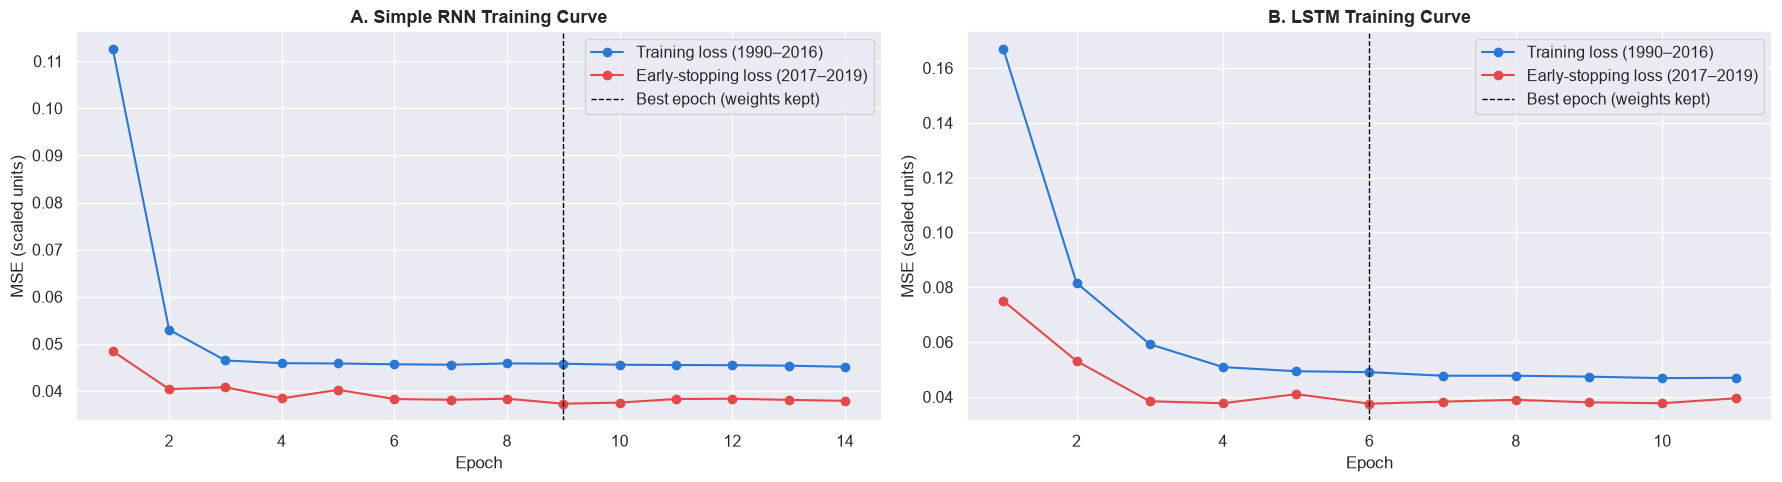

In [134]:
fig, ax = plt.subplots(ncols=2, figsize=(18, 5))
for i, label in enumerate(NETWORKS):
    ax[i].plot(range(1, len(histories[label]["train_loss"]) + 1), histories[label]["train_loss"], marker="o", color="#2a78d6", label="Training loss (1990–2016)")
    ax[i].plot(range(1, len(histories[label]["val_loss"]) + 1), histories[label]["val_loss"], marker="o", color="#e34948", label="Early-stopping loss (2017–2019)")
    ax[i].axvline(histories[label]["best_epoch"], color="black", linestyle="--", linewidth=1, label="Best epoch (weights kept)")
    ax[i].set_title(chr(65 + i) + ". " + label + " Training Curve")
    ax[i].set_xlabel("Epoch")
    ax[i].set_ylabel("MSE (scaled units)")
    ax[i].legend()
plt.tight_layout()
plt.show()

**What we see:** Both networks reach their best early-stopping loss within a few epochs: epoch 9 for the Simple RNN and epoch 6 for the LSTM. Training stops 5 epochs later (14 and 11 epochs run), and the best weights are kept. Both take less than a minute on a CPU.

**Why:** The pattern to learn is simple (recent days plus the season), and there are almost 10,000 training windows. After a few passes, more epochs only fit noise from 1990–2016, and the 2017–2019 loss stops improving.

**What we do with it:** The best epochs (9 and 6) are the number of epochs used to refit on 1990–2022 for the test.

In [135]:
# validation years: networks and SARIMAX models, scored on the same days
valid_real = temp_valid["temp_tomorrow"].loc[valid_days]
valid_network_forecasts = {label: pd.Series(predict_celsius(networks[label], X_valid, scaler), index=valid_days) for label in NETWORKS}

rows = []
for label in NETWORKS:
    scores = regression_scores(valid_real, valid_network_forecasts[label])
    scores["Forecast"] = label
    rows.append(scores)
for name in ["M1", "M2"]:
    scores = regression_scores(valid_real, valid_forecasts[name]["forecast"].loc[valid_days])
    scores["Forecast"] = MODELS[name]["label"]
    rows.append(scores)
scores = regression_scores(valid_real, temp_baselines.loc[valid_days, "Persistence (today)"])
scores["Forecast"] = "Baseline: Persistence (today)"
rows.append(scores)

network_valid_results = pd.DataFrame(rows).set_index("Forecast").sort_values("MAE (°C)")
network_valid_results.round(3)

,MAE (°C),RMSE (°C),MAPE (%),sMAPE (%),R²
Forecast,,,,,
LSTM,0.982,1.356,5.278,5.153,0.963
Simple RNN,0.985,1.367,5.221,5.148,0.962
"M2: ARIMA(3,0,0) + season + trend (manual)",0.991,1.373,5.331,5.204,0.962
"M1: ARIMA(3,0,0), no season",1.032,1.431,5.418,5.334,0.959
Baseline: Persistence (today),1.072,1.488,5.582,5.531,0.955


**What we see (validation, 2020–2022):** LSTM 0.982 °C, Simple RNN 0.985 °C, SARIMAX M2 0.991 °C, persistence 1.072 °C. The networks are 0.006–0.009 °C lower than M2, the same size as the gap between M2 and M3 in Step 6.

**What we do with it:** By the rule fixed in Step 6, a gap below 0.01 °C does not change the choice, so M2 stays the chosen model. The networks are still scored on the test years to fill the comparison table.

In [136]:
# final test: refit the scaler and the networks on 1990-2022 with the number of epochs found above, as SARIMAX was refitted in Step 8
final_scaler = fit_scaler(2022)
X_all_final, y_all_final, today_all_final = make_windows(final_scaler)
X_final, y_final, _ = select(X_all_final, y_all_final, today_all_final, "1990-01-01", "2022-12-31")
X_test, y_test, test_days = select(X_all_final, y_all_final, today_all_final, "2023-01-01", "2025-12-30")

test_network_forecasts = {}
for label, network in NETWORKS.items():
    final_network, _ = train(network(X_final.shape[2]), X_final, y_final, epochs=histories[label]["best_epoch"])
    test_network_forecasts[label] = pd.Series(predict_celsius(final_network, X_test, final_scaler), index=test_days)

rows = []
for label in NETWORKS:
    scores = regression_scores(temp_test["temp_tomorrow"], test_network_forecasts[label])
    scores["Forecast"] = label
    rows.append(scores)
for name in ["M1", "M2"]:
    scores = regression_scores(temp_test["temp_tomorrow"], test_forecasts[name]["forecast"])
    scores["Forecast"] = MODELS[name]["label"]
    rows.append(scores)
scores = regression_scores(temp_test["temp_tomorrow"], temp_baselines.loc[temp_test.index, "Persistence (today)"])
scores["Forecast"] = "Baseline: Persistence (today)"
rows.append(scores)

network_test_results = pd.DataFrame(rows).set_index("Forecast").sort_values("MAE (°C)")
network_test_results.round(3)

,MAE (°C),RMSE (°C),MAPE (%),sMAPE (%),R²
Forecast,,,,,
LSTM,0.929,1.270,4.494,4.480,0.966
Simple RNN,0.934,1.275,4.509,4.495,0.966
"M2: ARIMA(3,0,0) + season + trend (manual)",0.940,1.286,4.543,4.526,0.965
"M1: ARIMA(3,0,0), no season",0.984,1.368,4.762,4.708,0.960
Baseline: Persistence (today),1.038,1.443,5.006,4.968,0.956


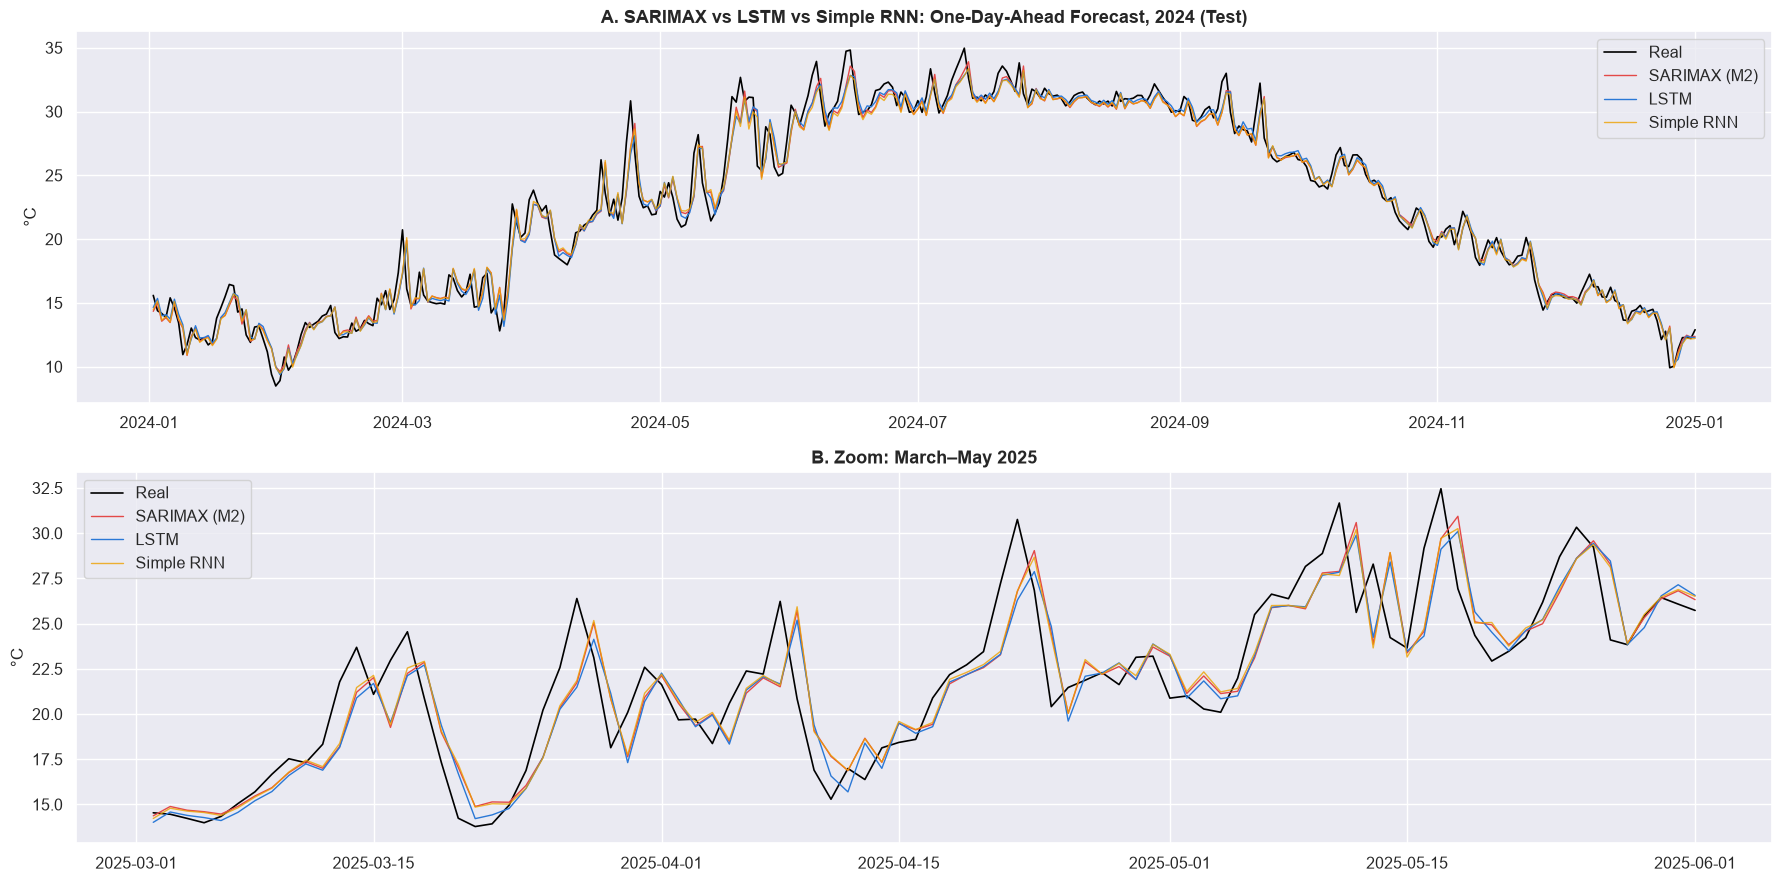

Simple RNN vs SARIMAX (M2): mean absolute difference between the two forecasts = 0.106 °C
LSTM vs SARIMAX (M2): mean absolute difference between the two forecasts = 0.206 °C


In [137]:
# SARIMAX vs LSTM vs RNN on the test years, on the day being forecast
fig, ax = plt.subplots(nrows=2, figsize=(18, 9))
periods = [slice("2024-01-01", "2024-12-31"), slice("2025-03-01", "2025-05-31")]
for i, period in enumerate(periods):
    days = temp_test.loc[period].index + pd.Timedelta(days=1)
    ax[i].plot(days, temp_test.loc[period, "temp_tomorrow"], color="black", linewidth=1.2, label="Real")
    ax[i].plot(days, test_forecasts["M2"].loc[period, "forecast"], color="#e34948", linewidth=1, label="SARIMAX (M2)")
    ax[i].plot(days, test_network_forecasts["LSTM"].loc[period], color="#2a78d6", linewidth=1, label="LSTM")
    ax[i].plot(days, test_network_forecasts["Simple RNN"].loc[period], color="#eda100", linewidth=1, alpha=0.8, label="Simple RNN")
    ax[i].set_ylabel("°C")
    ax[i].legend()
ax[0].set_title("A. SARIMAX vs LSTM vs Simple RNN: One-Day-Ahead Forecast, 2024 (Test)")
ax[1].set_title("B. Zoom: March–May 2025")
plt.tight_layout()
plt.show()

# how close the networks are to SARIMAX, day by day
for label in NETWORKS:
    print(label, "vs SARIMAX (M2): mean absolute difference between the two forecasts =",
          round((test_network_forecasts[label] - test_forecasts["M2"]["forecast"]).abs().mean(), 3), "°C")

**What we see (test, 2023–2025):**
- LSTM **0.929 °C**, Simple RNN 0.934 °C, SARIMAX M2 0.940 °C, persistence 1.038 °C. The LSTM is 10.5 % below persistence; M2 is 9.5 % below.
- The forecasts are very close: the LSTM differs from M2 by 0.21 °C per day on average, and the RNN by 0.11 °C, much less than their errors (about 0.93 °C). They miss the same sudden jumps.

**Why:** All three learn the same thing: the last few days plus a pull back toward the normal for the date. With one daily series and a memory of about 3 days, there is little non-linear pattern left for an LSTM to find. SARIMAX writes this structure down directly, with 12 parameters.

**What we do with it:** The deep-learning bonus **confirms** the SARIMAX result instead of beating it clearly. M2 stays the chosen model: same accuracy (within 0.011 °C), a reliable 95 % interval, and every part can be explained.

## Step 11: Model Comparison and Conclusion

**What we do:** Fill in the Task 5 comparison table (7.1) with every model and baseline, on the same test days (2023–2025). We add one column from Step 9: the MAE on the **Task 4 event days** in the test years, 35 days in total (6 storms, 28 heat waves, 1 cold snap).

**About the "SARIMA (m = 24)" row:** Task 5's template is for hourly data with a daily cycle. This data is daily, so the cycle is the year (m = 365). It is modeled with sine/cosine inputs (SARIMAX with Fourier terms, Step 4); M2, M3 and M4 are this project's SARIMA rows.

In [138]:
# the Task 5 comparison table: every model and baseline on the same test days (2023-2025)
test_real = temp_test["temp_tomorrow"]
final_forecasts = {
    "ARIMA(3,0,0), no season (M1)": test_forecasts["M1"]["forecast"],
    "SARIMAX: ARIMA(3,0,0) + season + trend (M2, chosen)": test_forecasts["M2"]["forecast"],
    "SARIMAX: ARIMA(3,0,3) + season + trend (M3, auto_arima)": test_forecasts["M3"]["forecast"],
    "SARIMAX: M2 + yesterday's humidity and pressure (M4)": test_forecasts["M4"]["forecast"],
    "Simple RNN (bonus)": test_network_forecasts["Simple RNN"],
    "LSTM (bonus)": test_network_forecasts["LSTM"],
    "Baseline: Persistence (today)": temp_baselines.loc[temp_test.index, "Persistence (today)"],
    "Baseline: Climatology (normal for tomorrow)": temp_baselines.loc[temp_test.index, "Climatology (normal for tomorrow)"],
}
NOTES = {
    "ARIMA(3,0,0), no season (M1)": "Ignores the yearly cycle",
    "SARIMAX: ARIMA(3,0,0) + season + trend (M2, chosen)": "Yearly cycle as 3 sine/cosine pairs; chosen in Steps 6-7",
    "SARIMAX: ARIMA(3,0,3) + season + trend (M3, auto_arima)": "auto_arima's order; 3 more parameters",
    "SARIMAX: M2 + yesterday's humidity and pressure (M4)": "Tests the Task 4 humidity/pressure finding",
    "Simple RNN (bonus)": "Last 30 days + day of year; PyTorch",
    "LSTM (bonus)": "Last 30 days + day of year; PyTorch",
    "Baseline: Persistence (today)": "Tomorrow = today",
    "Baseline: Climatology (normal for tomorrow)": "Season only",
}

# the "today" before the first day of every Task 4 storm, heat wave and cold snap in 2023-2025 (Step 9)
event_today = temp_test.index.intersection(all_event_days - pd.Timedelta(days=1))

rows = []
for label, forecast in final_forecasts.items():
    scores = regression_scores(test_real, forecast)
    scores["MAE on Task 4 event days (°C)"] = mean_absolute_error(test_real.loc[event_today], forecast.loc[event_today])
    scores["Model"] = label
    scores["Notes"] = NOTES[label]
    rows.append(scores)

comparison = pd.DataFrame(rows).set_index("Model")
persistence_test_mae = comparison.loc["Baseline: Persistence (today)", "MAE (°C)"]
comparison.insert(5, "Gain vs persistence (%)", 100 * (persistence_test_mae - comparison["MAE (°C)"]) / persistence_test_mae)
comparison = comparison.drop(columns="R²").sort_values("MAE (°C)")
comparison.round(3)

,MAE (°C),RMSE (°C),MAPE (%),sMAPE (%),Gain vs persistence (%),MAE on Task 4 event days (°C),Notes
Model,,,,,,,
LSTM (bonus),0.929,1.270,4.494,4.480,10.468,1.837,Last 30 days + day of year; PyTorch
Simple RNN (bonus),0.934,1.275,4.509,4.495,10.056,1.933,Last 30 days + day of year; PyTorch
"SARIMAX: ARIMA(3,0,3) + season + trend (M3, auto_arima)",0.937,1.282,4.554,4.525,9.755,1.857,auto_arima's order; 3 more parameters
SARIMAX: M2 + yesterday's humidity and pressure (M4),0.937,1.277,4.526,4.507,9.744,1.846,Tests the Task 4 humidity/pressure finding
"SARIMAX: ARIMA(3,0,0) + season + trend (M2, chosen)",0.940,1.286,4.543,4.526,9.479,1.895,Yearly cycle as 3 sine/cosine pairs; chosen in...
"ARIMA(3,0,0), no season (M1)",0.984,1.368,4.762,4.708,5.186,1.634,Ignores the yearly cycle
Baseline: Persistence (today),1.038,1.443,5.006,4.968,0.000,1.540,Tomorrow = today
Baseline: Climatology (normal for tomorrow),1.794,2.326,8.660,8.894,-72.841,4.439,Season only


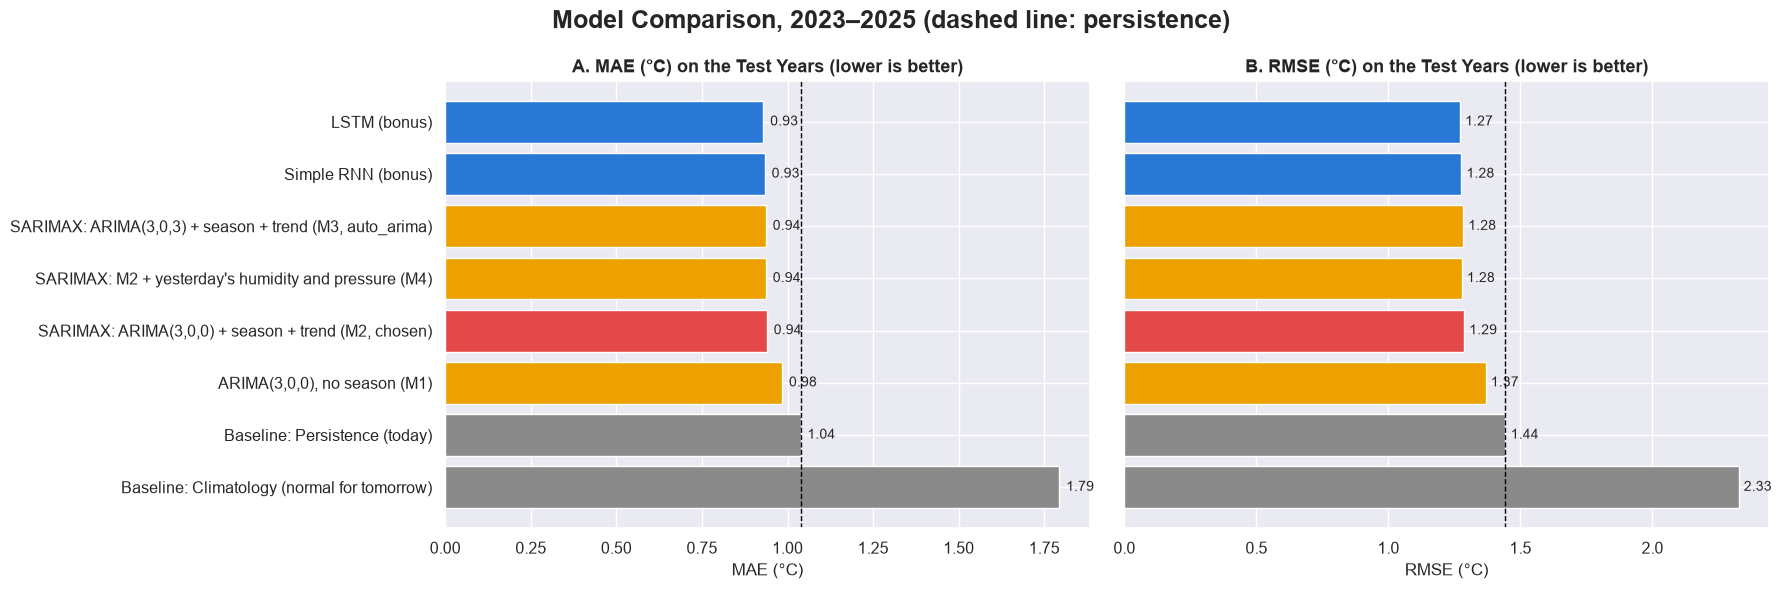

In [139]:
# model comparison bar chart: MAE and RMSE on the test years
chart = comparison.sort_values("MAE (°C)", ascending=False)
colors = ["#e34948" if "chosen" in label else "#2a78d6" if "bonus" in label else "#8a8a8a" if "Baseline" in label else "#eda100" for label in chart.index]

fig, ax = plt.subplots(ncols=2, figsize=(18, 6), sharey=True)
for i, metric in enumerate(["MAE (°C)", "RMSE (°C)"]):
    ax[i].barh(chart.index, chart[metric], color=colors)
    for y, value in enumerate(chart[metric]):
        ax[i].text(value + 0.02, y, str(round(value, 2)), va="center", fontsize=10)
    ax[i].axvline(chart.loc["Baseline: Persistence (today)", metric], color="black", linestyle="--", linewidth=1)
    ax[i].set_title(chr(65 + i) + ". " + metric + " on the Test Years (lower is better)")
    ax[i].set_xlabel(metric)
plt.suptitle("Model Comparison, 2023–2025 (dashed line: persistence)")
plt.tight_layout()
plt.show()

**What we see:**
- **Overall:** every model beats every baseline. The six models are within 0.06 °C of each other: LSTM 0.929, RNN 0.934, M3 and M4 0.937, M2 0.940, and M1 (no season) 0.984 °C. Persistence is 1.038 °C and climatology 1.794 °C. RMSE and MAPE give the same order.
- **On the 35 Task 4 event days the order flips:** persistence is best (1.54 °C), then M1 with no season (1.63 °C), then the LSTM (1.84 °C), M4 (1.85 °C), M3 (1.86 °C), M2 (1.90 °C) and the RNN (1.93 °C). These days are chosen by what happened, which favours forecasts that lean less toward normal (Step 12, Q4).

### Task 4 vs Task 5: the Six Questions, Answered Twice

**What we do:** For each Task 4 question, put the Task 4 answer (from the EDA) next to what the Task 5 forecasts show. The numbers in the table are computed from the results above (Steps 4–9), not typed in.

**Why:** Task 4 answered from the same years it described. Task 5 answers from forecasts on years the model never saw. If both agree, the answer is stronger; if they differ, Task 5 shows where the Task 4 answer needs care.

In [140]:
# H2 and H4 with Task 4's own definitions: very hot days (max > 40.1 °C) and very cold nights (min < 5.7 °C), per year
per_year = pd.DataFrame({
    "Very hot days (max > 40.1 °C)": (weather["temp_max"] > 40.1).groupby(weather.index.year).sum(),
    "Very cold nights (min < 5.7 °C)": (weather["temp_min"] < 5.7).groupby(weather.index.year).sum(),
})
periods = {"1990–1999": slice(1990, 1999), "2000–2009": slice(2000, 2009), "2010–2019": slice(2010, 2019), "2020–2022": slice(2020, 2022), "2023–2025 (test)": slice(2023, 2025)}
pd.DataFrame({name: per_year.loc[years].mean() for name, years in periods.items()}).T.round(1)

,Very hot days (max > 40.1 °C),Very cold nights (min < 5.7 °C)
1990–1999,16.3,20.0
2000–2009,18.6,17.7
2010–2019,16.6,16.5
2020–2022,19.0,21.0
2023–2025 (test),31.0,9.7


In [141]:
from IPython.display import display

# the Task 5 evidence for each Task 4 question, from the results of Steps 4-9
storm_name = "Storms (rain ≥ 10 mm, 2016–2025)"
storm_day = event_table.loc[(storm_name, "event day")]
storm_before = event_table.loc[(storm_name, "day before")]
calmest = by_score.iloc[0]


questions = pd.DataFrame({
    "Question": [
        "H1 Is Cairo getting warmer?",
        "H2 More very hot days?",
        "H3 Did heavy rain increase after 2016?",
        "H4 Are cold waves rarer?",
        "H5 Do storms give a warning?",
        "H6 Khamasin-like days?",
    ],
    "Task 4 answer (EDA)": [
        "Yes: nights +0.41, days +0.23 °C per 10 years",
        "Partly: 2023 and 2024 are the highest",
        "Most likely a change in the data",
        "Yes, slowly; 2022 was still cold",
        "Partly: heat and cold build up; storms do not",
        "Yes: hot, very dry, low pressure, south wind",
    ],
    "Task 5 evidence (forecasts on unseen years)": [
        "M2 learns +" + str(round(final_fits["M2"].params["trend"], 2)) + " °C per 10 years, but is still "
            + str(round(error.mean(), 2)) + " °C too cold on 2023–2025 (nights vs days not tested: the target is the daily mean)",
        "Days with max > 40.1 °C (Task 4's definition): " + str(round(per_year.loc[1990:2019, "Very hot days (max > 40.1 °C)"].mean(), 1))
            + " a year in 1990–2019, " + str(round(per_year.loc[2023:2025, "Very hot days (max > 40.1 °C)"].mean(), 1))
            + " in 2023–2025",
        "Not re-tested: rain and storm days use 2016–2025 only, as Task 4 decided",
        "Nights with min < 5.7 °C (Task 4's definition): " + str(round(per_year.loc[1990:2019, "Very cold nights (min < 5.7 °C)"].mean(), 1))
            + " a year in 1990–2019, " + str(round(per_year.loc[2020:2022, "Very cold nights (min < 5.7 °C)"].mean(), 1)) + " in 2020–2022, "
            + str(round(per_year.loc[2023:2025, "Very cold nights (min < 5.7 °C)"].mean(), 1)) + " in 2023–2025",
        "Storm day: MAE " + str(round(storm_day["MAE model (°C)"], 2)) + " vs persistence " + str(round(storm_day["MAE persistence (°C)"], 2))
            + "; day before only " + str(round(storm_before["MAE model (°C)"], 2)) + ". " + str(storm_warning["Warned (rain ≥ 1 mm the day before)"].iloc[0])
            + " of " + str(storm_warning["Storms"].iloc[0]) + " storms came after a rain day; rain today + falling pressure: "
            + str(round(storm_conditions.loc["+ rain today + pressure falling", "Chance (%)"], 1)) + " % chance of a storm tomorrow (usual: "
            + str(round(100 * base_chance, 1)) + " %); after a dry day: no sign",
        "Not testable after 2012 (no wind direction). A similar pattern: the calmest 10 % of storm-score days (rising heat, dry air) have the largest error: MAE " + str(round(calmest["MAE model (°C)"], 2))
            + ", vs " + str(round(by_score["MAE model (°C)"].iloc[1:9].min(), 2)) + "–" + str(round(by_score["MAE model (°C)"].iloc[1:9].max(), 2)) + " in the middle groups",
    ],
    "Verdict": [
        "Confirmed for the daily mean; nights vs days not tested",
        "Strengthened: almost twice as many very hot days in 2023–2025",
        "Used, not re-tested",
        "Confirmed: rarer, with cold years still possible (2020–2022)",
        "Refined: a warning exists only for storms that start after rain",
        "Not testable here; a similar pattern only",
    ],
}).set_index("Question")

with pd.option_context("display.max_colwidth", None):
    display(questions)

,Task 4 answer (EDA),Task 5 evidence (forecasts on unseen years),Verdict
Question,,,
H1 Is Cairo getting warmer?,"Yes: nights +0.41, days +0.23 °C per 10 years","M2 learns +0.24 °C per 10 years, but is still 0.13 °C too cold on 2023–2025 (nights vs days not tested: the target is the daily mean)",Confirmed for the daily mean; nights vs days not tested
H2 More very hot days?,Partly: 2023 and 2024 are the highest,"Days with max > 40.1 °C (Task 4's definition): 17.2 a year in 1990–2019, 31.0 in 2023–2025",Strengthened: almost twice as many very hot days in 2023–2025
H3 Did heavy rain increase after 2016?,Most likely a change in the data,"Not re-tested: rain and storm days use 2016–2025 only, as Task 4 decided","Used, not re-tested"
H4 Are cold waves rarer?,"Yes, slowly; 2022 was still cold","Nights with min < 5.7 °C (Task 4's definition): 18.1 a year in 1990–2019, 21.0 in 2020–2022, 9.7 in 2023–2025","Confirmed: rarer, with cold years still possible (2020–2022)"
H5 Do storms give a warning?,Partly: heat and cold build up; storms do not,Storm day: MAE 1.65 vs persistence 1.3; day before only 1.0. 13 of 25 storms came after a rain day; rain today + falling pressure: 20.4 % chance of a storm tomorrow (usual: 0.7 %); after a dry day: no sign,Refined: a warning exists only for storms that start after rain
H6 Khamasin-like days?,"Yes: hot, very dry, low pressure, south wind","Not testable after 2012 (no wind direction). A similar pattern: the calmest 10 % of storm-score days (rising heat, dry air) have the largest error: MAE 1.4, vs 0.75–1.11 in the middle groups",Not testable here; a similar pattern only


**What we see:**
- **H1 (warming):** Task 4 measured the warming; Task 5 puts it inside the model (+0.24 °C per 10 years, refitted on 1990–2022). Even so, the forecasts for 2023–2025 are 0.13 °C too cold, in every test year. The warming is real **and** it is running ahead of the 33-year trend. The other half of H1, nights warming faster than days, is not tested here: the target is the daily mean.
- **H2 (very hot days):** with Task 4's own definition (max above 40.1 °C), Cairo had 16–19 very hot days a year in every decade from 1990 to 2022, and **31 a year in 2023–2025**: almost twice as many. Task 4 said "partly" because the years jump a lot; the test years make the answer stronger. Step 12 (Q3) shows they can be warned of 1–3 days ahead.
- **H3 (rain data):** Task 5 does not test this again. It uses the Task 4 decision: rain and storms come from 2016–2025 only.
- **H4 (cold waves):** with Task 4's own definition (min below 5.7 °C), very cold nights went from 20 a year in the 1990s to 18 in the 2000s and 16.5 in the 2010s, rose to 21 a year in 2020–2022 (2022 was cold), and fell to under 10 a year in 2023–2025. Rarer, slowly, with cold years still possible: the same answer as Task 4.
- **H5 (storm warning):** Task 4 looked at each sign alone and found tiny correlations (below 0.06). Task 5 looks at them together (9.5): rain today with falling pressure raises the chance of a storm tomorrow from 0.7 % to 20 %, about 30 times. But 12 of the 25 storms start after a dry day with no sign at all, and the temperature models miss every storm day (1.65 °C, worse than persistence). Task 4's "partly" was right; Task 5 shows which part.
- **H6 (Khamasin):** cannot be tested in Task 5. Task 4's definition needs a south wind, and wind direction is missing after 2012. The closest Task 5 gets is a similar pattern: the calmest storm-score days (rising heat, dry air) have the largest forecast error. That fits H6, but it does not prove these days are Khamasin.

**Why the Task 5 answers are stronger evidence:** Task 4 described the same years it measured, so its answers were patterns in the past. Task 5 checks them on years the model never saw (2023–2025), and measures each one in °C of forecast error. An answer that holds there is no longer just a pattern; it tells us where a forecast can be trusted.

### What Task 5 adds to Task 4

| Task 4 (understand the past) | Task 5 (forecast the future) |
|---|---|
| Found the yearly cycle and a 3-day memory | Built them into one model (season + trend + ARIMA(3,0,0)) that beats persistence by 9.5 % on unseen years |
| Set the number to beat (persistence, 1.04 °C) | Beat it in every test year and in 13 of 13 walk-forward years |
| Asked whether storms give a warning (H5), one sign at a time | Combined the signs: rain today + falling pressure raises the chance of a storm tomorrow about 30 times; storms that start on a dry day give no sign |
| Warned that the test years are the warmest (H1, H2) | Measured it: 0.13 °C too cold overall; very hot days almost doubled; a warning for them 1–3 days ahead (Q3) |
| Described spring as the hardest season | Showed that the 95 % interval is too narrow in spring and on event days |

## Step 12: Sharper Questions for Task 5

**What we do:** Use what the six Task 4 questions taught us to ask sharper questions, questions a forecast can answer for Cairo, and answer the two that were still open (Q3, Q4).

**What Task 4's questions taught us**

| Lesson | Where we learned it | So the sharper question is |
|---|---|---|
| A question needs one fixed definition | H2 and H4 first used other thresholds in Task 5 | Count very hot days (max > 40.1 °C) and very cold nights (min < 5.7 °C) exactly as Task 4 did (Step 11) |
| A question needs data that exists | H6 needs wind direction, missing after 2012 | Ask only what daily NASA data can show |
| One sign at a time hides combined signals | H5: every correlation below 0.06 | Combine the signs (9.5): rain + falling pressure raises the storm risk about 30 times |
| Rare events cannot train a model | 25 storms in 10 years (9.5, 9.6) | Ask warning questions about events that are frequent enough and matter for Cairo |
| Days chosen by what happened give a biased verdict | "The model is 2 °C too cold on heat waves" (Steps 8–9) | Judge a forecast on days chosen in advance (Q4) |
| Describing the past is not forecasting | All six questions describe 1990–2025 | Ask what can be known **before** it happens |

**Sharper questions for Cairo**

| | Question | Why it matters for Cairo | Answer |
|---|---|---|---|
| Q1 | How far ahead is the temperature forecast useful? | Planning | About a week (Step 6) |
| Q2 | When is the forecast least reliable? | When to trust it | Spring; the 95 % interval is too narrow then (Steps 6, 8) |
| Q3 | Can we warn of a very hot day (max > 40.1 °C) 1–3 days ahead? | Heat is Cairo's most frequent extreme, and very hot days almost doubled (H2): health, outdoor work, power demand | Below |
| Q4 | Is the forecast really too cold in hot weather? | Whether a heat warning can trust it | Below |
| Q5 | Do storms give a warning when the signs are combined? | Flooding | Yes, for storms that start after rain (9.5) |
| Q6 | Can rain tomorrow be forecast better than "rain today"? | Task 4's second goal | No (9.6) |

### Q3: A Very Hot Day Warning, 1 to 3 Days Ahead

**What we do:** For each "today", the chance that the max temperature 1, 2 or 3 days later is above 40.1 °C (Task 4's very hot day). Inputs known today: the max temperature of the last 3 days and its difference from normal, how many warm days in a row, humidity, pressure, wind and the date. A logistic regression learns on 1990–2019, the threshold is chosen on 2020–2022 (best F1), and the test years are used once. The number to beat is persistence: "very hot today → very hot then".

**Why:** Very hot days are Cairo's most frequent extreme (31 a year in 2023–2025), so, unlike storms, there are enough of them to learn from (about 500 in the training years). Task 4 found that heat builds up over days (H5), so a warning should be possible.

In [142]:
# Q3: can we warn of a very hot day (max > 40.1 °C, Task 4's definition) 1, 2 or 3 days ahead?
# inputs known today; normals from the training years only
max_vs_normal = anomaly("temp_max")
warm_days_in_a_row = (max_vs_normal > 0).astype(int)
warm_days_in_a_row = warm_days_in_a_row.groupby((warm_days_in_a_row == 0).cumsum()).cumsum()

heat_inputs = pd.DataFrame({
    "temp_max_today": weather["temp_max"],
    "temp_max_yesterday": weather["temp_max"].shift(1),
    "temp_max_2_days_ago": weather["temp_max"].shift(2),
    "temp_max_vs_normal": max_vs_normal,
    "temp_max_change_3d": weather["temp_max"].diff(3),
    "warm_days_in_a_row": warm_days_in_a_row,
    "humidity_vs_normal": anomaly("humidity"),
    "pressure_vs_normal": anomaly("pressure"),
    "pressure_change_3d": weather["pressure"].diff(3),
    "wind_vs_normal": anomaly("wind_speed"),
    "day_sin": np.sin(2 * np.pi * weather.index.dayofyear / 365.25),
    "day_cos": np.cos(2 * np.pi * weather.index.dayofyear / 365.25),
}, index=weather.index)
very_hot_today = (weather["temp_max"] > 40.1).astype(int)

year = weather.index.year
rows = []
for lead in [1, 2, 3]:
    max_then = weather["temp_max"].shift(-lead)
    very_hot_then = (max_then > 40.1).astype(int)
    usable = heat_inputs.notna().all(axis=1) & max_then.notna()
    learn = weather.index[usable & (year <= 2019)]
    choose = weather.index[usable & (year >= 2020) & (year <= 2022)]
    final = weather.index[usable & (year >= 2023)]

    heat_scaler = StandardScaler().fit(heat_inputs.loc[learn])
    heat_model = LogisticRegression(class_weight="balanced", C=0.3, max_iter=3000)
    heat_model.fit(heat_scaler.transform(heat_inputs.loc[learn]), very_hot_then.loc[learn])
    chance = pd.Series(heat_model.predict_proba(heat_scaler.transform(heat_inputs[usable]))[:, 1], index=weather.index[usable])

    # the threshold with the best F1 on validation only
    threshold = max(np.arange(0.05, 0.96, 0.01), key=lambda t: f1_score(very_hot_then.loc[choose], (chance.loc[choose] >= t).astype(int)))
    for split_name, days in [("Validation", choose), ("Test", final)]:
        for name, warning in [("Model", (chance.loc[days] >= threshold).astype(int)), ("Persistence (very hot today)", very_hot_today.loc[days])]:
            scores = classification_scores(very_hot_then.loc[days], warning)
            scores.update({"Days ahead": lead, "Split": split_name, "Warning": name})
            rows.append(scores)

heat_warning = pd.DataFrame(rows).set_index(["Days ahead", "Split", "Warning"])
heat_warning[["Hits", "Misses", "False alarms", "Precision", "Recall", "F1", "CSI"]].round(2)

Hits  Misses  \
Days ahead Split      Warning                                      
1          Validation Model                           43      14   
                      Persistence (very hot today)    29      28   
           Test       Model                           72      21   
                      Persistence (very hot today)    57      36   
2          Validation Model                           39      18   
                      Persistence (very hot today)    19      38   
           Test       Model                           72      21   
                      Persistence (very hot today)    42      51   
3          Validation Model                           35      22   
                      Persistence (very hot today)    14      43   
           Test       Model                           65      28   
                      Persistence (very hot today)    36      57   

                                                    False alarms  Precision  \
Days ahead Split      Warning                                                 
1          Validation Model                                   55       0.44   
                      Persistence (very hot today)            28       0.51   
           Test       Model                                   63       0.53   
                      Persistence (very hot today)            36       0.61   
2          Validation Model                                  106       0.27   
                      Persistence (very hot today)            38       0.33   
           Test       Model                                  126       0.36   
                      Persistence (very hot today)            51       0.45   
3          Validation Model                                  125       0.22   
                      Persistence (very hot today)            43       0.25   
           Test       Model                                  136       0.32   
                      Persistence (very hot today)            57       0.39   

                                                    Recall    F1   CSI  
Days ahead Split      Warning                                           
1          Validation Model                           0.75  0.55  0.38  
                      Persistence (very hot today)    0.51  0.51  0.34  
           Test       Model                           0.77  0.63  0.46  
                      Persistence (very hot today)    0.61  0.61  0.44  
2          Validation Model                           0.68  0.39  0.24  
                      Persistence (very hot today)    0.33  0.33  0.20  
           Test       Model                           0.77  0.49  0.33  
                      Persistence (very hot today)    0.45  0.45  0.29  
3          Validation Model                           0.61  0.32  0.19  
                      Persistence (very hot today)    0.25  0.25  0.14  
           Test       Model                           0.70  0.44  0.28  
                      Persistence (very hot today)    0.39  0.39  0.24

**What we see:**

| Days ahead | Test F1: model | Test F1: persistence | Very hot test days caught (of 93): model vs persistence |
|---|---|---|---|
| 1 | 0.63 | 0.61 | 72 vs 57 |
| 2 | 0.49 | 0.45 | 72 vs 42 |
| 3 | 0.44 | 0.39 | 65 vs 36 |

- The model beats persistence at every lead, on validation and on test. It catches many more very hot days and pays with more false alarms (63 vs 36 one day ahead).
- The skill falls quickly after one day, as expected from a memory of about 3 days.

**Why:** Heat builds up, and the model sees the build-up: today's max, its difference from normal, the date. Persistence only knows whether today was already above 40.1 °C, so it misses the first day of every hot spell.

**What we do with it:** **Yes:** a very hot day in Cairo can be warned of one day ahead, catching about 3 in 4 (77 %), against 61 % for persistence, and still better than persistence 2 and 3 days ahead. This is the most useful new result of Task 5: it turns H2 (more very hot days) and H5 (heat builds up) into a warning.

### Q4: Is the Forecast Really Too Cold in Hot Weather?

**What we do:** Steps 8 and 9 found the model about 0.9 °C too cold on the hottest 5 % of test days, and 2 °C too cold on the first day of heat waves. But those days were chosen by **what happened**. Here the same test forecasts (Step 8) are judged on hot days chosen **in advance**: days the forecast itself said would be hot, and days after a warm spell (more than 1 °C above normal) had run for 3 or 5 days. Then two spell inputs are added to M2 to see if they change anything.

**Why:** Picking the days that turned out hottest picks the days that were hotter than anyone expected, so every forecast looks too cold on them (regression to the mean). Only days chosen in advance show a real bias.

In [143]:
# Q4: is the forecast too cold in hot weather? Judge it on days chosen in advance, not by what happened
test_error = by_day_test["real"] - by_day_test["forecast"]  # the Step 8 test forecasts, on the day being forecast
known_today = by_day_test.index - pd.Timedelta(days=1)

temp_vs_normal = weather["temp_mean"] - normal_by_day.reindex(weather.index.dayofyear).values
warm_spell = (temp_vs_normal > 1).astype(int)
warm_spell = warm_spell.groupby((warm_spell == 0).cumsum()).cumsum()
spell_today = pd.Series(warm_spell.loc[known_today].values, index=by_day_test.index)

groups = {
    "All test days": test_error.notna(),
    "Chosen by what happened: the hottest 5 % of days": by_day_test["real"] > HOT,
    "Chosen in advance: the forecast is above the same line": by_day_test["forecast"] > HOT,
    "Chosen in advance: a warm spell of 3+ days is running": spell_today >= 3,
    "Chosen in advance: a warm spell of 5+ days is running": spell_today >= 5,
}
pd.DataFrame({
    "Days": {name: int(mask.sum()) for name, mask in groups.items()},
    "Bias: real − forecast (°C)": {name: test_error[mask].mean() for name, mask in groups.items()},
}).round(2)

,Days,Bias: real − forecast (°C)
All test days,1095,0.13
Chosen by what happened: the hottest 5 % of days,131,0.88
Chosen in advance: the forecast is above the same line,101,0.11
Chosen in advance: a warm spell of 3+ days is running,323,0.12
Chosen in advance: a warm spell of 5+ days is running,214,0.16


In [144]:
# and does telling M2 that a warm spell is running change anything? Fitted on 1990-2019, scored on validation
spell_inputs = pd.DataFrame({
    "warm_spell_days": warm_spell.clip(upper=10).shift(1),        # known the day before
    "temp_vs_normal_7d": temp_vs_normal.rolling(7).mean().shift(1),
}, index=weather.index).fillna(0)

def with_spell(index):
    return make_exog(index, K).join(spell_inputs.loc[index])

spell_fit = SARIMAX(train_temp, exog=with_spell(train_temp.index), order=(3, 0, 0)).fit(disp=False, maxiter=200)
target_days = temp_valid.index + pd.Timedelta(days=1)
new_days = pd.date_range(train_temp.index[-1] + pd.Timedelta(days=1), target_days[-1], freq="D")
spell_forecast = spell_fit.extend(weather["temp_mean"].loc[new_days], exog=with_spell(new_days)).get_prediction().predicted_mean.loc[target_days]

print("Validation MAE, M2:", round(mean_absolute_error(temp_valid["temp_tomorrow"], valid_forecasts["M2"]["forecast"]), 3),
      "| M2 + spell inputs:", round(mean_absolute_error(temp_valid["temp_tomorrow"].values, spell_forecast.values), 3))
spell_fit.params[["warm_spell_days", "temp_vs_normal_7d"]].round(3)

Validation MAE, M2: 0.992 | M2 + spell inputs: 0.992


warm_spell_days     -0.008
temp_vs_normal_7d    0.080
dtype: float64

**What we see:**
- **Chosen by what happened** (the hottest 5 % of test days): the forecast is **0.88 °C** too cold (131 days).
- **Chosen in advance:** 0.11 °C when the forecast itself said "hot" (101 days), 0.12 °C after 3 or more warm days in a row (323 days), 0.16 °C after 5 or more (214 days). About the same as on all test days (0.13 °C).
- **Spell inputs:** adding "warm days in a row" and "the 7-day difference from normal" to M2 leaves the validation MAE at about 0.99 °C, and both inputs get weights close to 0.

**Why:** The model is not biased in hot weather. The 0.88 °C comes from how those days were picked. The only real bias is the small 0.13 °C on every kind of day: the warming of 2023–2025 running ahead of the trend learned on 1990–2022 (H1). A spell input adds nothing, because the three AR terms already know the last three days.

**What we do with it:** Correct the earlier reading of Steps 8 and 9: the model does not "pull heat waves back to normal"; like any forecast, it misses sudden jumps. The fair way to judge a forecast on heat is a warning question asked in advance, and that is Q3.

## Conclusion

**Which model performed best, and why**
- **The LSTM has the lowest test error (0.929 °C), but SARIMAX M2 is the chosen model.** It is within 0.011 °C, and the choice was fixed on validation before the test (Steps 6 and 7). M2 also gives a 95 % interval that holds overall (95.1 % on test), and every part is clear: the yearly season (3 sine/cosine pairs), the warming trend (+0.24 °C per 10 years), and a 3-day memory.
- **Why all models are so close:** tomorrow's temperature in Cairo is the normal for the date plus a few days of memory. Every model learns this. SARIMAX writes it down directly, so a neural network has little left to find in temperature alone.
- **Why the gain over persistence is only about 10 %:** today already says most of what tomorrow will be (a 0.97 link, Task 4). The model's only extra knowledge is that an unusual day tends to move back toward normal.
- **The no-season ARIMA (M1)** is clearly worse overall (0.984 °C): without the season, it does not know where "normal" is.

**The storm story (Task 4, H5): the models win on ordinary days and lose on the days that matter**
- On ordinary days, M2 beats persistence (0.93 vs 1.04 °C). On the first day of Task 4's storms, heat waves and cold snaps, **persistence beats every model**. Part of this comes from how those days are chosen (by what happened); Step 12 asks the fair question in advance.
- **Storms:** no sign in the temperature the day before, so every temperature model forecasts an ordinary day, about 1 °C too warm. The March 2020 storm was missed by 2.95 °C, then caught the next day.
- **Heat waves:** judged on days chosen by what happened, the models look about 2 °C too cold; judged on hot days chosen in advance, only 0.1–0.2 °C (Q4). And a very hot day (max > 40.1 °C) can be warned of one day ahead, catching 77 % against 61 % for persistence, and still better 2 and 3 days ahead (Q3).
- **Storm warning (9.5):** the signs work together. Rain today with falling pressure raises the chance of a storm tomorrow about 30 times, to 20 %. This covers 10 of the 25 storms; the 12 storms that start on a dry day give no sign. A logistic model with 15 storms to learn from does no better than this simple rule.
- **Rain tomorrow (9.6), Task 4's second goal:** a logistic model beats persistence on validation (F1 0.41 vs 0.36) but not on the drier test years (0.42 vs 0.47). Persistence stays the rain forecast.
- **Answer to H5, refined:** storms that start after rain give a one-day warning (rain + falling pressure); storms that start on a dry day cannot be seen one day ahead in daily data. Heat can be seen coming: Q3 warns of very hot days 1–3 days ahead.

**Limits and next steps**
- The 95 % interval is too narrow in spring and on unusual days (Steps 6, 8, 9), and the forecast misses sudden jumps.
- Judging a forecast on days chosen by what happened makes it look worse than it is (Q4); warnings must be judged in advance, with hits, misses and false alarms.
- Next: an interval whose width changes with the season, the heat warning (Q3) checked on more years, and a storm warning built on more storms or hourly data (pressure, satellite), judged against the rule found in 9.5. In this notebook rain has its baselines (Step 2), the storm-warning analysis (9.5) and a logistic model that does not beat persistence on test (9.6).

### Assumptions (Task 5, 7.2)
| Item | Value |
|---|---|
| Frequency | Daily ("D"); 13,149 days, 1990–2025, no gaps or duplicates (2.1) |
| Timezone | Dates as returned by NASA POWER for Cairo; no timezone conversion |
| Imputed values | Only short gaps (≤ 3 days), filled by time interpolation in Task 4 (2.6); nothing filled in Task 5. Wind direction (wrong from 2013) not used |
| Outliers | Kept, not capped: real storms, heat waves and cold snaps (2.3) |
| Forecast type | Single-step: tomorrow from today. Multi-step only for the error-by-horizon check (Step 6) |
| No leakage | Normals, scalers and models use training years only; the test years were used once (Step 8, Step 10 test refit) |

### Decisions log
| Decision | Value | Where |
|---|---|---|
| Differencing | d = 0, D = 0, plus a trend term | Step 3 |
| Season | 3 sine/cosine pairs of the day of year (K = 3) | Step 4 |
| ARIMA order | (3,0,0) from the PACF; auto_arima (3,0,3) kept as M3 | Steps 4–5 |
| Chosen model | M2, the simplest unless another is better by more than 0.01 °C on validation | Steps 6–7 |
| Validation | Walk-forward, refit each year: 2020–2022 for 3 models, 2010–2022 for M2 | Step 7 |
| Storm events | Task 4 definitions, unchanged | Step 9 |
| Storm warning | The rule "rain today + falling pressure"; a logistic model was tried and not kept | 9.5 |
| Rain tomorrow | Persistence kept (F1 0.47 on test); a logistic model was tried and not kept | 9.6 |
| Networks | 30-day window, early stopping on 2017–2019, refit on 1990–2022 | Step 10 |
| Heat warning | Logistic regression for max > 40.1 °C, 1–3 days ahead; beats persistence | Step 12 (Q3) |
| Spell inputs | Tried in M2; no change, not kept | Step 12 (Q4) |

### Task 5 deliverables checklist
| Deliverable | Where |
|---|---|
| Cleaned, resampled, gap-free series with documented preprocessing | 2.1–2.6 |
| Stationarity tests (ADF + KPSS) and the differencing decision | Step 3 |
| ACF/PACF, manual (p,d,q)(P,D,Q,m), and the auto_arima result | Step 4 |
| Fitted SARIMA(X) with `plot_diagnostics` and Ljung-Box | Step 5 |
| Forecast plot with confidence intervals vs actual | Steps 6 and 8 |
| MAE / RMSE / MAPE on the test set, plus walk-forward scores | Steps 7, 8 and 11 |
| (Bonus) RNN/LSTM with training curve and comparison against SARIMA | Step 10 |
| Written conclusion | Conclusion, after Step 12 |